# Imports:

In [1]:
#Sorgt dafür das wenn es änderungen in den imports gab alles was davon abhängt automatisch neu geladen wird
%load_ext autoreload
%autoreload 2

In [2]:
#Import needed libraries
import torch
import random
import numpy as np
import gpytorch
import matplotlib.pyplot as plt
import pickle
import os

torch.set_default_dtype(torch.double)

In [3]:
import warnings
from gpytorch.utils.warnings import NumericalWarning
from botorch.exceptions.warnings import OptimizationWarning, InputDataWarning

#Ignore warnings that are not problematic atp for now

warnings.filterwarnings("ignore", category=InputDataWarning)
warnings.filterwarnings("ignore", category=NumericalWarning)
warnings.filterwarnings("ignore", category=OptimizationWarning)

In [4]:
#Import Benchmarking Functions
from botorch.test_functions import Branin
from botorch.test_functions import Ackley
from botorch.test_functions import Hartmann

In [5]:
#import kernels
from gpytorch.kernels import LinearKernel, PeriodicKernel, MaternKernel, RBFKernel

In [6]:
#Import the BO loops

from functions.loops import bo_loop_mll
from functions.loops import bo_loop_loocv
from functions.loops import bo_loop_ea
from functions.loops import bo_loop_mcmc

ModuleNotFoundError: No module named 'pyromodels'

In [ ]:
#import the plot functions

from functions.plots import plot_bo_comparison, plot_regret_with_std, save_regret_with_std

In [ ]:
#import the functions needed for experiments
from functions.experiments import setSeed, generateInitialData, bo_experiment, bo_experiment_parallel, save_experiment

#Function to use bbob benchmarking
from functions.experiments import get_bbob_wrapper, BBOBWrapper

#Kernel misspecification selbst erzeugen
from functions.experiments import GPFunction, make_gp_function

#Wilcoxon test 
from functions.experiments import wilcoxon_comparison_all

#Table Funciton
from functions.experiments import build_summary_table

In [ ]:
from botorch.models.utils.gpytorch_modules import get_covar_module_with_dim_scaled_prior
from botorch.models import SingleTaskGP

# Preliminary Experiments 
Preliminary Tests on Standard Testfunctions (Ackley, Branin, Hartmann) to determine general performance and whether to use the Methods tried in the further experiments. This is where the K-fold CV approach with CMA-ES was discarded, because of its worse performance and fitting time than the other methods

In [49]:
setSeed(0)
f= Ackley()
bounds = f.bounds
X_init = generateInitialData(bounds, n=10)

results_loocv = bo_loop_loocv(f =f, X_init =X_init, maximize=False, num_loop=100)
print("LOOCV: ",results_loocv["best_vals"])
print("LOOCV Regrets: ", results_loocv["regrets"])

setSeed(0)
results_mll = bo_loop_mll(f=f,X_init = X_init, maximize=False, num_loop=100)
print("MLL: ",results_mll["best_vals"])
print("MLL Regrets: ", results_mll["regrets"])

plot_bo_comparison({"MLL": results_mll, "LOOCV": results_loocv},title = "Ackley: MLL vs. LOOCV")

NameError: name 'setSeed' is not defined

Done
LOOCV:  [9.719904413125864, 9.719904413125864, 3.4548990290547867, 3.4548990290547867, 2.7293351785236273, 2.7293351785236273, 2.7293351785236273, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.665779801993399, 2.6657798019

/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
MLL:  [9.719904413125864, 9.719904413125864, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 3.6708548397706022, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 2.0165089203392736, 0.6164893779329188, 0.6164893779329188, 0.6164893779329188, 0.61648937

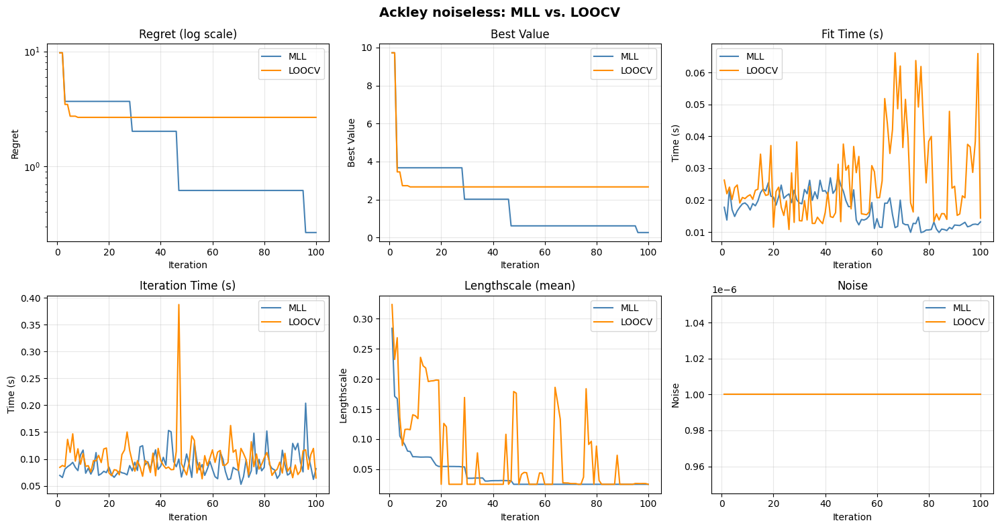

In [ ]:
setSeed(0)
f= Ackley()
bounds = f.bounds
X_init = generateInitialData(bounds, n=10)

results_loocv = bo_loop_loocv(f =f, X_init =X_init, maximize=False, noiseless = True, num_loop=100)
print("LOOCV: ",results_loocv["best_vals"])
print("LOOCV Regrets: ", results_loocv["regrets"])

setSeed(0)
results_mll = bo_loop_mll(f=f,X_init = X_init, maximize=False, noiseless= True, num_loop=100)
print("MLL: ",results_mll["best_vals"])
print("MLL Regrets: ", results_mll["regrets"])

plot_bo_comparison({"MLL": results_mll, "LOOCV": results_loocv},title = "Ackley noiseless: MLL vs. LOOCV")

/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
LOOCV:  [7.994648752329917, 7.994648752329917, 7.994648752329917, 1.982072057785075, 1.982072057785075, 1.982072057785075, 1.9768027991648314, 1.9516846543260744, 1.9514832560356314, 1.9512969283602875, 1.9512524074504345, 1.9512524074504345, 1.9512524074504345, 1.9512524074504345, 1.9512524074504345, 0.43869094411470577, 0.43869094411470577, 0.4110490681020593, 0.4110490681020593, 0.4110490681020593, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.40472653335005404, 0.

/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
MLL:  [7.994648752329917, 2.458699496323103, 2.458699496323103, 2.458699496323103, 2.3135992910030287, 1.951363186042725, 1.951363186042725, 1.951363186042725, 1.951363186042725, 1.951363186042725, 1.951363186042725, 1.951363186042725, 1.951363186042725, 1.951363186042725, 1.951363186042725, 1.951363186042725, 0.6897167499508683, 0.6897167499508683, 0.46405856123862677, 0.46405856123862677, 0.42716927344426026, 0.42716927344426026, 0.41594116973217155, 0.409689854667759, 0.3991815041759583, 0.3991815041759583, 0.3991815041759583, 0.39834835513273426, 0.39834835513273426, 0.39834835513273426, 0.39798094456698685, 0.39798094456698685, 0.39798094456698685, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.3979617929009063, 0.39796179290

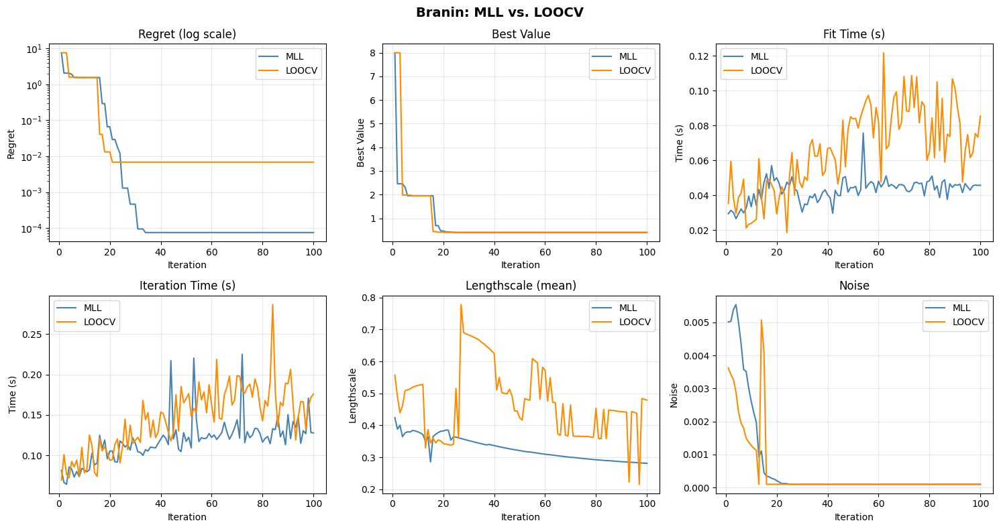

In [ ]:
setSeed(0)
f= Branin()
bounds = f.bounds
X_init = generateInitialData(bounds, n=10)

results_loocv = bo_loop_loocv(f =f, X_init =X_init, maximize=False, num_loop=100)
print("LOOCV: ",results_loocv["best_vals"])
print("LOOCV Regrets: ", results_loocv["regrets"])

setSeed(0)
results_mll = bo_loop_mll(f=f,X_init = X_init, maximize=False, num_loop=100)
print("MLL: ",results_mll["best_vals"])
print("MLL Regrets: ", results_mll["regrets"])

plot_bo_comparison({"MLL": results_mll, "LOOCV": results_loocv}, title = "Branin: MLL vs. LOOCV")

/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
LOOCV:  [-1.1802240330190095, -1.1802240330190095, -1.1802240330190095, -1.1802240330190095, -2.107928067456073, -2.107928067456073, -2.3377419721524384, -2.3377419721524384, -2.3377419721524384, -2.604820186180965, -2.604820186180965, -2.604820186180965, -2.604820186180965, -2.604820186180965, -2.815137351679737, -3.0181966484968386, -3.0181966484968386, -3.0181966484968386, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.129161588475223, -3.1292781597706543, -3.1292781597706543, -3.1292781597706543, -3.1292781597706543, -3.1292781597706543, -3.1292781597706543, -3.1292781597706543, -3.1292781597706543, -3.1292781597706543, -3.1321228617349526, -3.1321228617349526, -3.1321228617349526, -3.1321228617349526, -3.1321228617349526, -3.1321228617349526, -3.1321228617349526, 

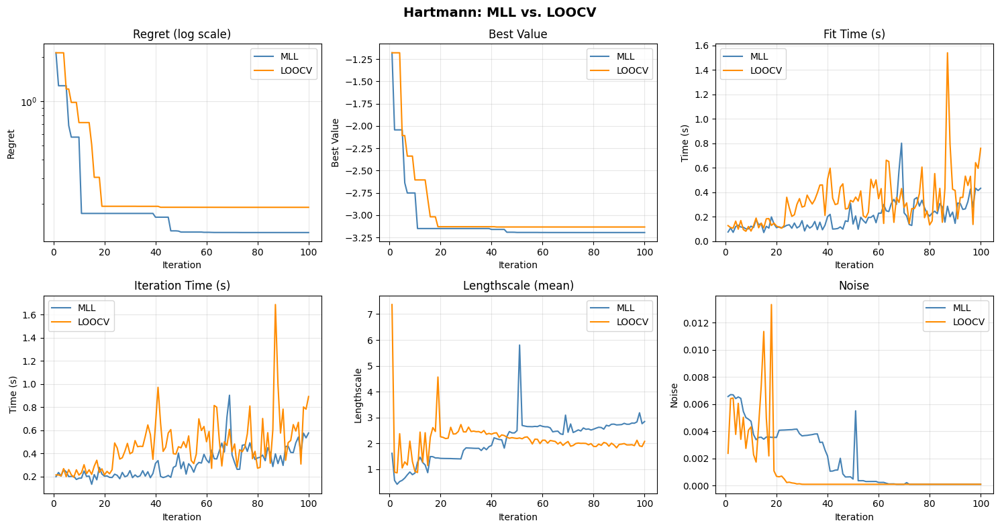

In [ ]:
setSeed(0)
f= Hartmann()
bounds = f.bounds
X_init = generateInitialData(bounds, n=10)

results_loocv = bo_loop_loocv(f =f, X_init =X_init, maximize=False, num_loop=100)
print("LOOCV: ",results_loocv["best_vals"])
print("LOOCV Regrets: ", results_loocv["regrets"])

setSeed(0)
results_mll = bo_loop_mll(f=f,X_init = X_init, maximize=False, num_loop=100)
print("MLL: ",results_mll["best_vals"])
print("MLL Regrets: ", results_mll["regrets"])

plot_bo_comparison({"MLL": results_mll, "LOOCV": results_loocv}, title = "Hartmann: MLL vs. LOOCV")

Done
LOOCV:  [-1.1802240330190095, -1.1802240330190095, -1.2007563689742258, -1.2352607051182802, -1.278055919665824, -1.322041158495796, -1.3622573591333398, -1.3949905725068383, -1.421441105771329, -1.4425997043918426, -1.4588237792042675, -1.4710031534773034, -1.4792988591887481, -1.5060272190382673, -1.5210740667411706, -1.53872944981191, -1.5583703534486588, -1.5845759867274452, -1.595010431680997, -1.5982608717321753, -1.5982608717321753, -1.625748323473931, -1.700310857228519, -1.7465316597369989, -1.7989101481652996, -1.826448122031581, -1.8517994320637836, -1.8721580965953986, -1.8801003058231363, -1.890578817093195, -1.9080782206198443, -1.9111823434369977, -1.9111823434369977, -1.9126333230078527, -1.919224071534081, -1.937295609533023, -1.9612389850046863, -1.984832185690875, -2.005380476929098, -2.0334110813536412, -2.060840748008194, -2.0860251725623487, -2.108080295695348, -2.1265284512779856, -2.140621044700599, -2.1591369121674595, -2.18192486358111, -2.203544730686321

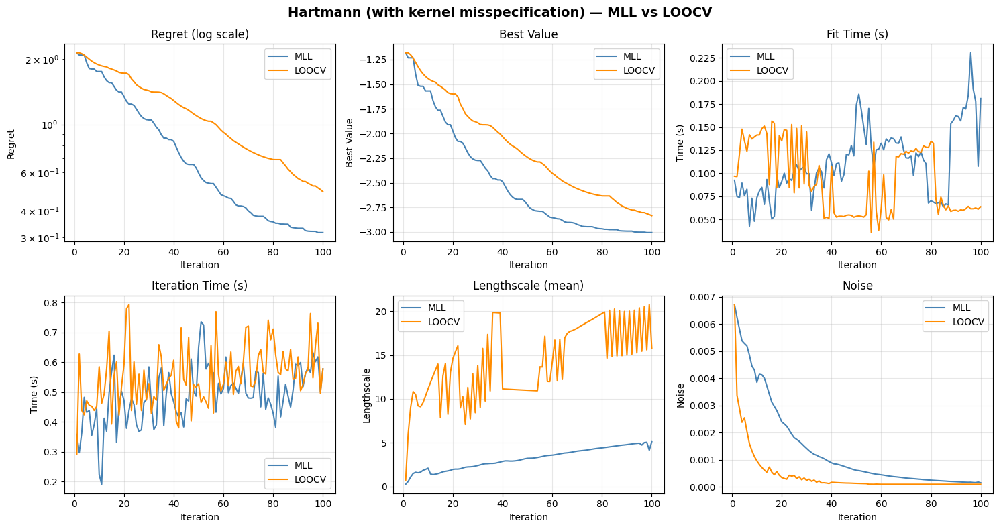

In [ ]:
#Kernel Misspecification Test
#Correct Kernel would be RBF Kernel but a bad kernel for this function is used

from gpytorch.kernels import MaternKernel
setSeed(0)
f= Hartmann()
bounds = f.bounds
X_init = generateInitialData(bounds, n=10)

results_loocv = bo_loop_loocv(f =f, X_init =X_init, maximize=False, num_loop=100, kernel = MaternKernel(nu = 0.5))
print("LOOCV: ",results_loocv["best_vals"])
print("LOOCV Regrets: ", results_loocv["regrets"])

setSeed(0)
results_mll = bo_loop_mll(f=f,X_init = X_init, maximize=False, num_loop=100, kernel = MaternKernel(nu = 0.5))
print("MLL: ",results_mll["best_vals"])
print("MLL Regrets: ", results_mll["regrets"])

plot_bo_comparison({"MLL": results_mll, "LOOCV": results_loocv}, title="Hartmann (with kernel misspecification) — MLL vs LOOCV")

Run No. 0
Done
Done
Run No. 1
Done
Done
Run No. 2
Done
Done
Run No. 3
Done
Done
Run No. 4
Done
Done
Run No. 5
Done
Done
Run No. 6
Done
Done
Run No. 7
Done
Done
Run No. 8
Done
Done
Run No. 9
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
MLL vs LOOCV:
  Median MLL: 1.7674
  Median LOOCV: 1.8004
  p-value: 0.9219
  p-corrected: 0.9219
  Signifikant: Nein


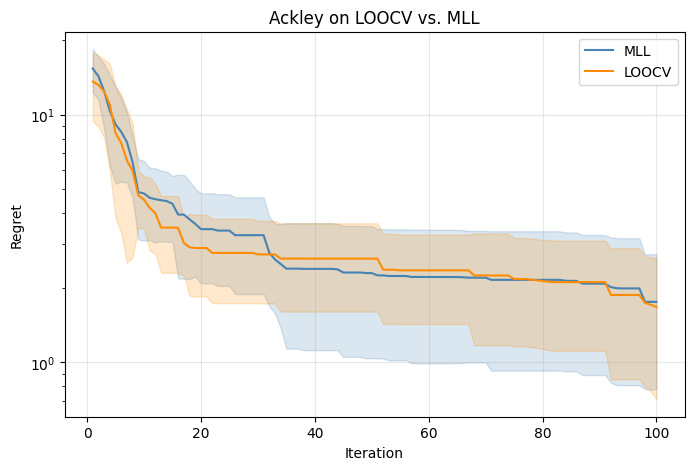

Run No. 0


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_ba

Done
Run No. 1


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_ba

Done
Run No. 2


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_ba

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 3


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_ba

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 4


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 5


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 6


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 7


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 8


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 9
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
MLL vs LOOCV:
  Median MLL: 0.0002
  Median LOOCV: 0.0026
  p-value: 0.0195
  p-corrected: 0.0195
  Signifikant: Ja


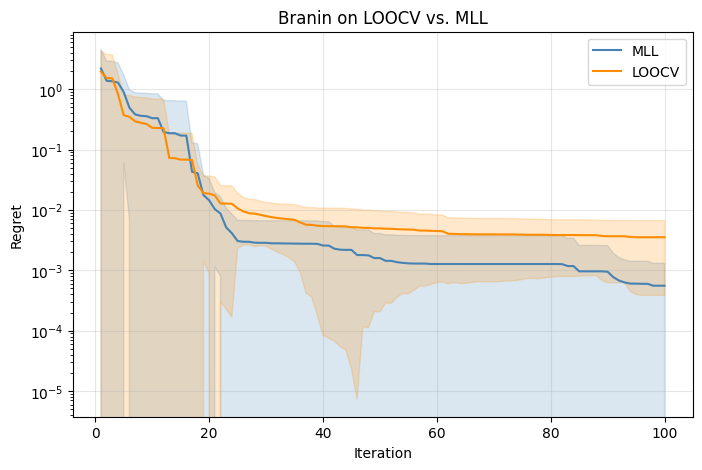

Run No. 0


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 1
Done
Done
Run No. 2
Done
Done
Run No. 3
Done
Done
Run No. 4
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 5
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 6
Done
Done
Run No. 7
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 8
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 9
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
MLL vs LOOCV:
  Median MLL: 0.0047
  Median LOOCV: 0.0052
  p-value: 1.0000
  p-corrected: 1.0000
  Signifikant: Nein


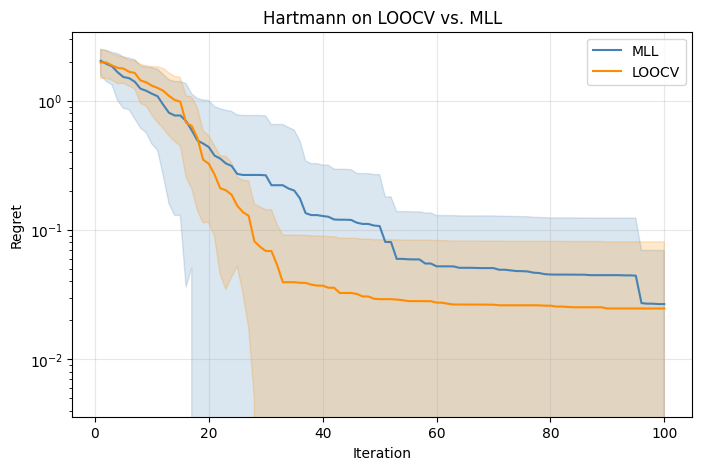

   Experiment Method A  Median A Method B  Median B  p-value Signifikant?
  Ackley(RBF)      MLL    1.7674    LOOCV    1.8004   0.9219         Nein
  Branin(RBF)      MLL    0.0002    LOOCV    0.0026   0.0195           Ja
Hartmann(RBF)      MLL    0.0047    LOOCV    0.0052   1.0000         Nein


In [ ]:
#comparison with 10 runs on ackley, branin and hartmann
experiments = []
regrets = bo_experiment(f= Ackley())["regrets"]
plot_regret_with_std(results = regrets, title = "Ackley on LOOCV vs. MLL")
experiments.append(("Ackley(RBF)",regrets))

regrets = bo_experiment(f= Branin())["regrets"]
plot_regret_with_std(results= regrets, title = "Branin on LOOCV vs. MLL")
experiments.append(("Branin(RBF)",regrets))

regrets= bo_experiment(f= Hartmann())["regrets"]
plot_regret_with_std(results = regrets,  title = "Hartmann on LOOCV vs. MLL")
experiments.append(("Hartmann(RBF)",regrets))

table = build_summary_table(experiments)
print(table.to_string(index = False))

Run No. 0
Done
Done
Run No. 1
Done
Done
Run No. 2
Done
Done
Run No. 3
Done
Done
Run No. 4
Done
Done
Run No. 5
Done
Done
Run No. 6
Done
Done
Run No. 7
Done
Done
Run No. 8
Done
Done
Run No. 9
Done
Done
MLL vs LOOCV:
  Median MLL: 0.2672
  Median LOOCV: 0.7241
  p-value: 0.0273
  p-corrected: 0.0273
  Signifikant: Ja


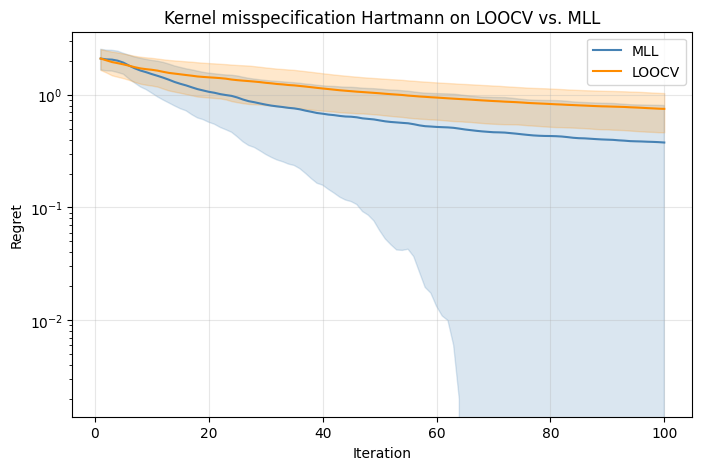

In [ ]:
#comparison of loocv and mll with forced kernel misspecification
regrets = bo_experiment(f= Hartmann(), kernel = MaternKernel(nu = 0.5))["regrets"]
plot_regret_with_std(results = regrets, title = "Kernel misspecification Hartmann on LOOCV vs. MLL")

Run No. 1
Run No. 2
Run No. 7
Run No. 0
Run No. 4
Run No. 5
Run No. 3
Run No. 6
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Done
Done
Done
Done
Done
Done
Done
Run No. 8
Done
Run No. 9
Done
Done
Done
Done
Done
Done
Done
Done
Done
Done
MLL vs LOOCV:
  Median MLL: 0.4464
  Median LOOCV: 0.4696
  p-value: 0.8457
  p-corrected: 0.8457
  Signifikant: Nein


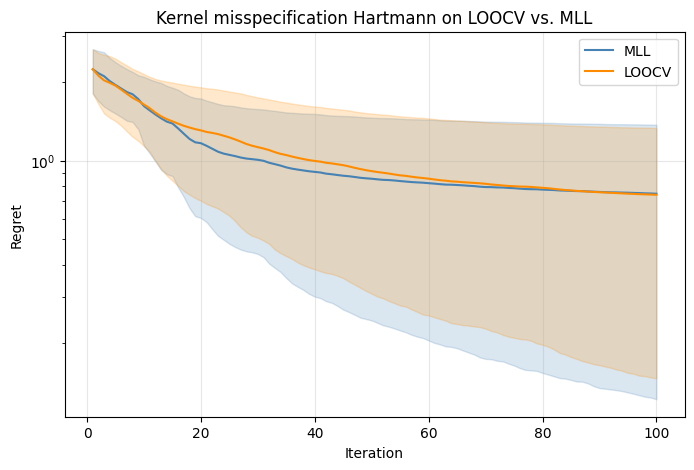

In [ ]:
#comparison of loocv and mll with forced kernel misspecification
regrets = bo_experiment_parallel(f= Hartmann(), kernel = MaternKernel(nu = 0.5))["regrets"]
plot_regret_with_std(results = regrets, title = "Kernel misspecification Hartmann on LOOCV vs. MLL")

Run No. 0
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 1
Done
Done
Done
Run No. 2
Done
Done
Done
Run No. 3
Done
Done
Done
Run No. 4
Done
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 5
Done
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 6
Done
Done
Done
Run No. 7
Done
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 8
Done
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 9
Done
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done


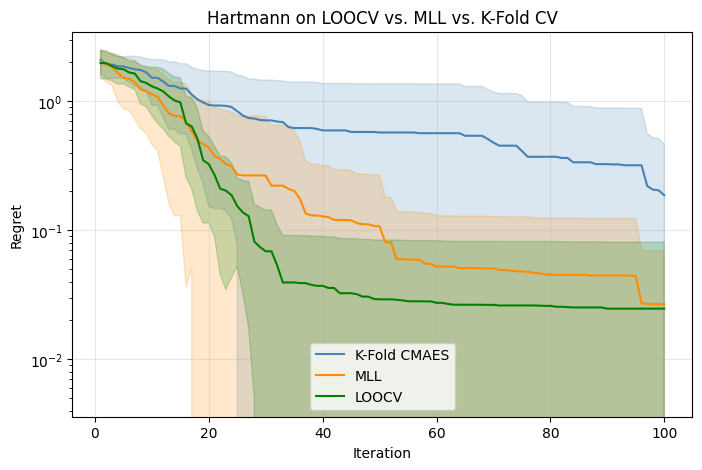

In [ ]:
regrets = bo_experiment(f= Hartmann(), bo_loops = [("K-Fold CMAES", bo_loop_ea),("MLL", bo_loop_mll), ("LOOCV", bo_loop_loocv)])["regrets"]
plot_regret_with_std(results = regrets, title = "Hartmann on LOOCV vs. MLL vs. K-Fold CV")

In [18]:
setSeed(0)
f= Branin()
bounds = f.bounds
X_init = generateInitialData(bounds, n=10)

results_ea = bo_loop_ea(f =f, X_init =X_init, maximize=False, num_loop= 100)
print("EA: ",results_ea["best_vals"])
print("EA Regrets: ", results_ea["regrets"])

setSeed(0)
results_loocv = bo_loop_loocv(f=f,X_init = X_init, maximize=False, num_loop=100)
print("LOOCV: ",results_loocv["best_vals"])
print("LOOCV Regrets: ", results_loocv["regrets"])

Done
EA:  [2.62162817850926, 0.9809101254582853, 0.9809101254582853, 0.9809101254582853, 0.9809101254582853, 0.9809101254582853, 0.9809101254582853, 0.9809101254582853, 0.9809101254582853, 0.9809101254582853, 0.9809101254582853, 0.9809101254582853, 0.9809101254582853, 0.9809101254582853, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.44507629137880045, 0.4450762913788004

/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
LOOCV:  [7.994648752329917, 7.994648752329917, 7.994648752329917, 1.982058111131911, 1.982058111131911, 1.982058111131911, 1.976779023308616, 1.951695863314372, 1.9515306493164495, 1.95129654192122, 1.95129654192122, 1.95129654192122, 1.95129654192122, 1.95129654192122, 1.95129654192122, 1.95129654192122, 1.95129654192122, 0.4410195289365131, 0.4410195289365131, 0.41454770782524797, 0.41454770782524797, 0.41454770782524797, 0.4086491827916028, 0.4086491827916028, 0.4086491827916028, 0.4086491827916028, 0.4086491827916028, 0.4086491827916028, 0.4086491827916028, 0.4086491827916028, 0.4086491827916028, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.39803354592168816, 0.3980335

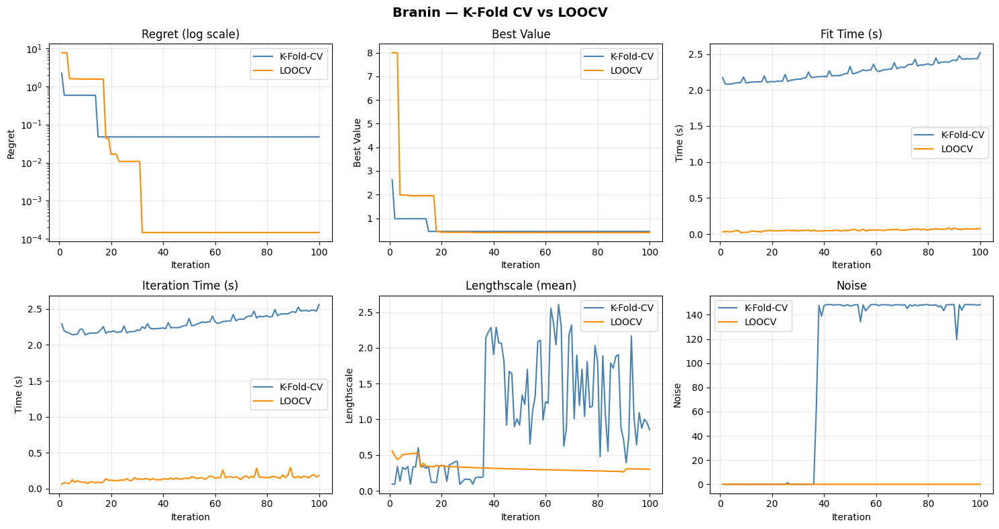

In [19]:
plot_bo_comparison({"K-Fold-CV": results_ea, "LOOCV": results_loocv}, title="Branin — K-Fold CV vs LOOCV")

Done


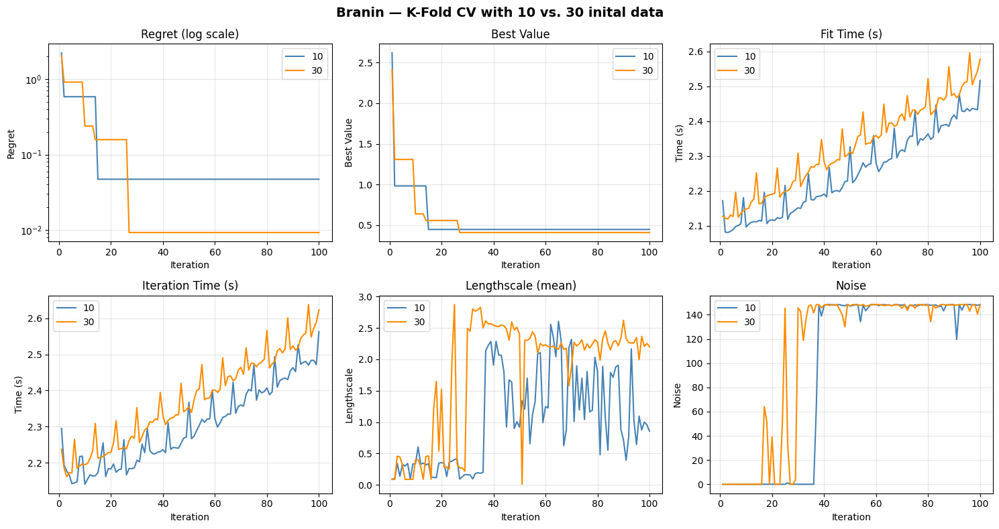

In [20]:
#test if EA loop works better with higher count of initial data (30 vs. 10)
setSeed(0)
f= Branin()
bounds = f.bounds
X_init = generateInitialData(bounds, n=30)

results_ea_more_initial = bo_loop_ea(f =f, X_init =X_init, maximize=False, num_loop= 100)

plot_bo_comparison({"10": results_ea, "30": results_ea_more_initial}, title="Branin — K-Fold CV with 10 vs. 30 inital data", labels = ["10","30"])

Run No. 0
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 1
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_ba

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 2
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 3
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` wit

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 4
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 5
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Run No. 6
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_ba

Done
Run No. 7
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_ba

Done
Run No. 8
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_ba

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed on the second try, after generating a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[Optimi

Done
Run No. 9
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


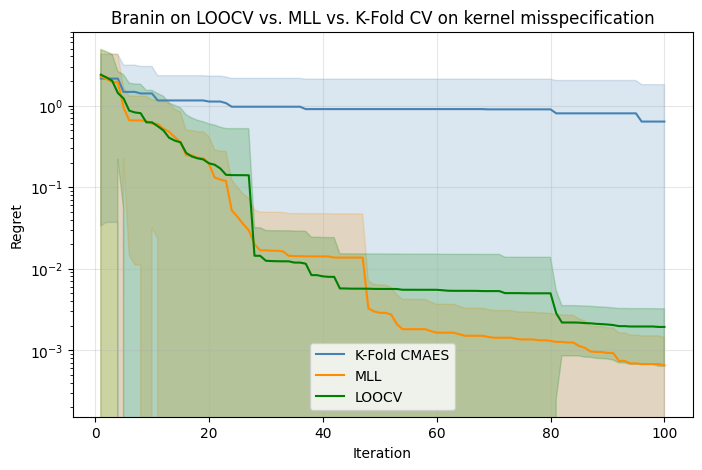

In [ ]:
#CMAES, MLL and LOOCV on kernel misspecification
regrets = bo_experiment(f= Branin(), bo_loops = [("K-Fold CMAES", bo_loop_ea),("MLL", bo_loop_mll), ("LOOCV", bo_loop_loocv)], kernel = PeriodicKernel())["regrets"]
plot_regret_with_std(results = regrets, title = "Branin on LOOCV vs. MLL vs. K-Fold CV on kernel misspecification")

#Hier ist der Kernel zwar misspecified aber nicht sehr stark misspecified weshalb das ergebnis sich bei loocv und mll kaum unterscheidet

In [22]:
import carps
help(carps)

Help on package carps:

NAME
    carps

PACKAGE CONTENTS
    analysis (package)
    configs (package)
    container (package)
    experimenter (package)
    loggers (package)
    objective_functions (package)
    optimizers (package)
    run
    run_from_db
    utils (package)

FILE
    /Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/carps/__init__.py




In [36]:
setSeed(0)


f = get_bbob_wrapper(fid=1, instance=1, dimension=5, seed = 0)
print(f.bounds)
print(f.optimal_value)

X = generateInitialData(f.bounds)
print(f(X))

tensor([[-5., -5., -5., -5., -5.],
        [ 5.,  5.,  5.,  5.,  5.]])
79.48
tensor([132.0973,  92.9214,  91.5808, 115.8340, 110.9075,  90.4671, 134.3944,
        101.5918, 129.6465, 168.9651])


In [37]:
#Repräsentative BBOB Funktionen nehmen anhand derer Experimente gemacht und ausgewertet werden
bbob_functions = [
    (1, "Sphere"), #unimodal, simple
    (8, "Rosenbrock"), #unimodal, valley 
    (15, "Rastrigin"), #multimedial function and is oscillating -> periodic kernel better
    (21, "Gallagher"), #many peaks without structure/random -> maximal misspecification of kernel because it cant fit
]

Running: Sphere
Run No. 0
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Done
Run No. 1
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 2
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 3
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 4
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/p

Done
Done
Run No. 5
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed on the second try, after generating a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[Optimi

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 6
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Done
Run No. 7
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_ba

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Run No. 8
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Done
Run No. 9
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done


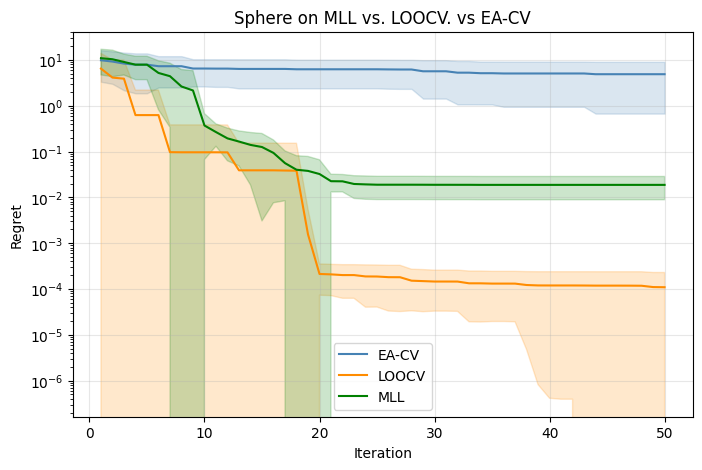

Running: Rosenbrock
Run No. 0
Done
Done
Done
Run No. 1
Done
Done
Done
Run No. 2
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed on the second try, after generating a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
Done
Run No. 3
Done
Done
Done
Run No. 4
Done
Done
Done
Run No. 5
Done
Done
Done
Run No. 6
Done
Done
Done
Run No. 7
Done
Done
Done
Run No. 8
Done
Done
Done
Run No. 9
Done
Done
Done


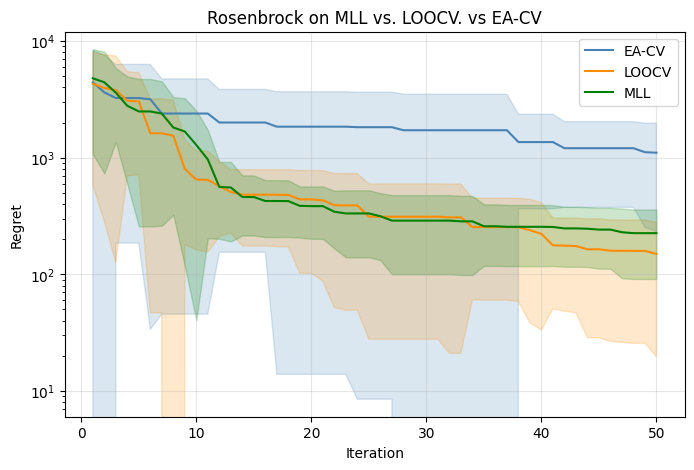

Running: Rastrigin
Run No. 0
Done
Done
Done
Run No. 1
Done
Done
Done
Run No. 2
Done
Done
Done
Run No. 3
Done
Done
Done
Run No. 4
Done
Done
Done
Run No. 5
Done
Done
Done
Run No. 6
Done
Done
Done
Run No. 7
Done
Done
Done
Run No. 8
Done
Done
Done
Run No. 9
Done
Done
Done


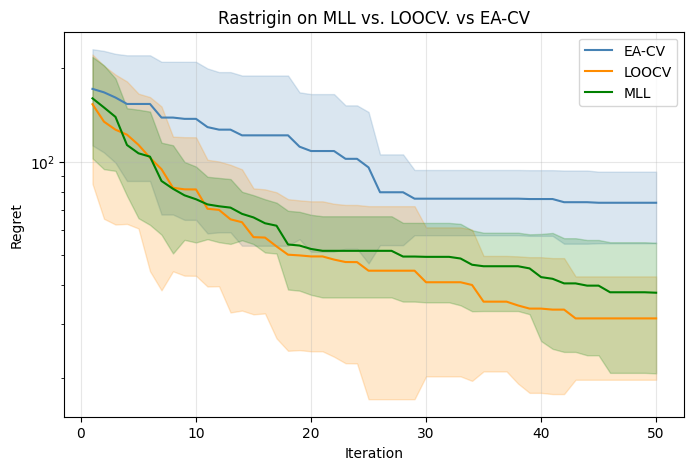

Running: Gallagher
Run No. 0
Done
Done
Done
Run No. 1
Done
Done
Done
Run No. 2
Done
Done
Done
Run No. 3
Done
Done
Done
Run No. 4
Done
Done
Done
Run No. 5
Done
Done
Done
Run No. 6
Done
Done
Done
Run No. 7
Done
Done
Done
Run No. 8
Done
Done
Done
Run No. 9


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:362: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  generated_initial_conditions = opt_inputs.get_ic_generator()(


Done
Done
Done


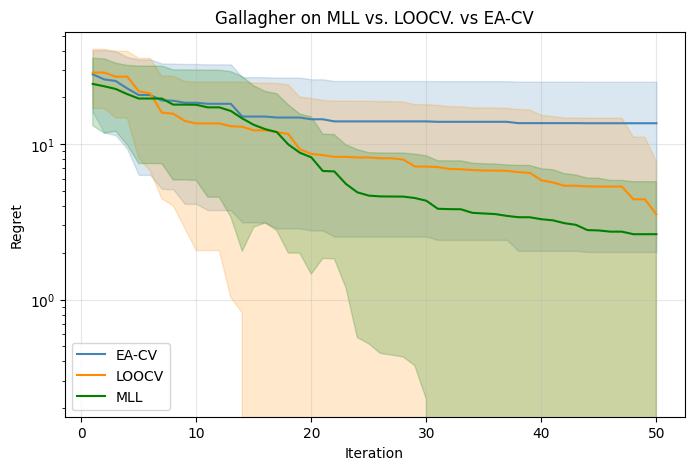

In [ ]:
#Für die oberen Funktionen je ein Experiment drauflaufen lassen und auswerten per ergebnis
all_results = {}
experiments = []
for fid, func_name in bbob_functions:
    print(f"Running: {func_name}")
    
    #erstmal nur mit einem instance und seed pro funktion (das später anpassen)
    f = get_bbob_wrapper(fid, instance = 1, dimension = 5, seed =1)
    results = bo_experiment(f = f,
        n_runs = 10,
        num_loop = 50, 
        bo_loops= [("EA-CV", bo_loop_ea), ("LOOCV", bo_loop_loocv), ("MLL", bo_loop_mll)]
    )["regrets"]
    
    all_results[func_name] = results
    experiments.append((func_name,results))

    plot_regret_with_std(results, title = f"{func_name} on MLL vs. LOOCV. vs EA-CV")

table = build_summary_table(experiments)
print(table.to_string(index = False))

## Kernel Misspecification selbst erzeugen:

Done
Done
-2.6139757535412254


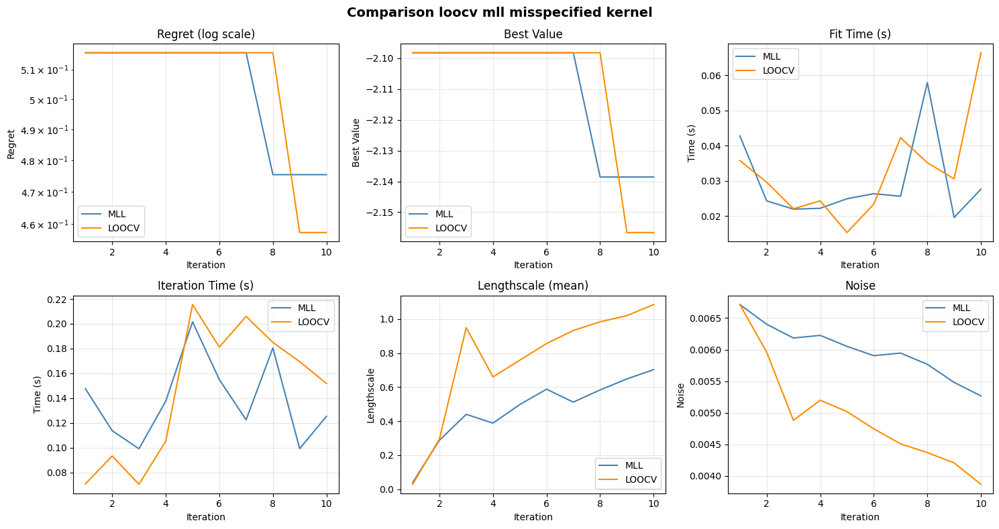

In [17]:
f = make_gp_function(seed = 10)
setSeed(10)
X_init = generateInitialData(f.bounds)

#Evaluate with misspecified Kernel
results_mll = bo_loop_mll(f, X_init, maximize= False, kernel = MaternKernel(nu = 0.5))
setSeed(10)
results_loocv = bo_loop_loocv(f, X_init, maximize= False, kernel = MaternKernel(nu = 0.5))
print(f.optimal_value)

plot_bo_comparison({"MLL": results_mll, "LOOCV": results_loocv}, title = "Comparison loocv mll misspecified kernel")

### MCMC Loop

Done
Done
Done


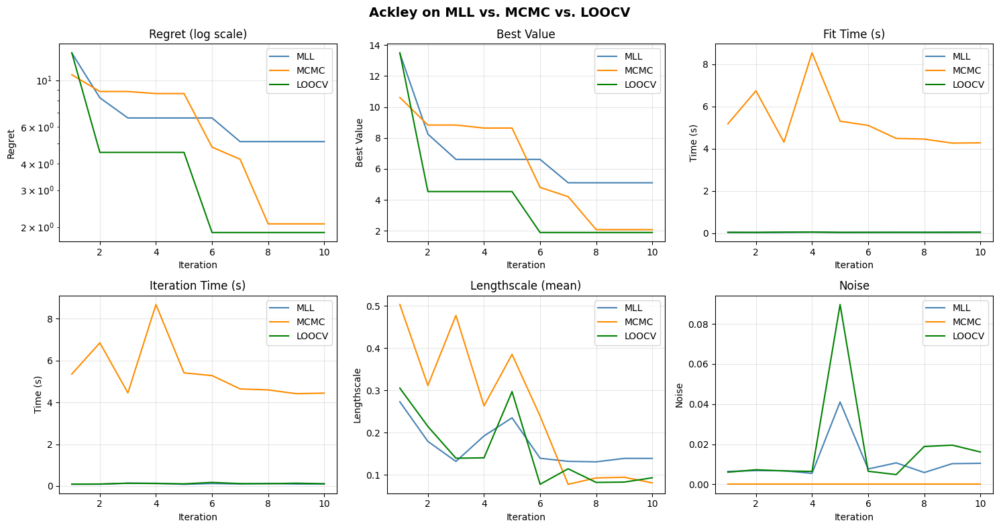

In [21]:
f = Ackley()
bounds = f.bounds
X_init = generateInitialData(bounds)

setSeed(10)
results_mll = bo_loop_mll(f, X_init, maximize= False)
setSeed(10)
results_mcmc = bo_loop_mcmc(f, X_init, maximize= False)
setSeed(10)
results_loocv = bo_loop_loocv(f, X_init, maximize= False)

results = {"MLL": results_mll, "MCMC": results_mcmc, "LOOCV": results_loocv}

plot_bo_comparison(results, title = "Ackley on MLL vs. MCMC vs. LOOCV")

Run No. 0
Done
Done
Run No. 1
Done
Done
Run No. 2
Done
Done
Run No. 3
Done
Done
Run No. 4
Done
Done
Run No. 5
Done
Done
Run No. 6
Done
Done
Run No. 7
Done
Done
Run No. 8
Done
Done
Run No. 9
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
MLL vs LOOCV:
  Median MLL: 1.7674
  Median LOOCV: 1.8004
  p-value: 0.9219
  p-corrected: 0.9219
  Signifikant: Nein


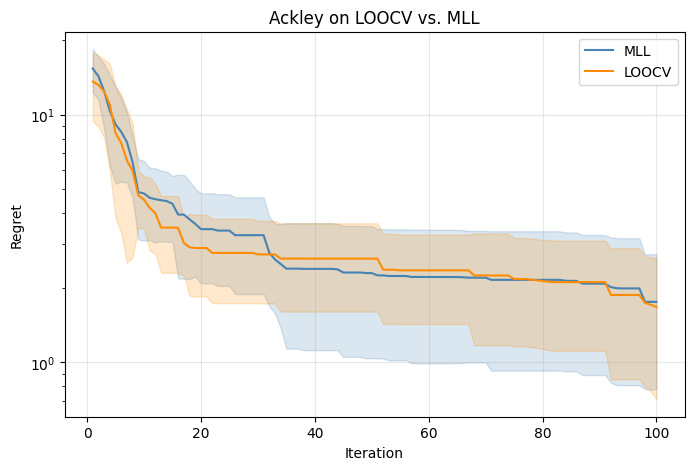

 Experiment Method A  Median A Method B  Median B  p-value Signifikant?
Ackley(RBF)      MLL    1.7674    LOOCV    1.8004   0.9219         Nein


In [ ]:
#Test Table function
experiments = []

regrets = bo_experiment(f= Ackley())["regrets"]
plot_regret_with_std(results = regrets, title = "Ackley on LOOCV vs. MLL")
experiments.append(("Ackley(RBF)",regrets))
table = build_summary_table(experiments)
print(table.to_string(index = False))

/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/optim/optimize.py:796: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_ba

Done
Done


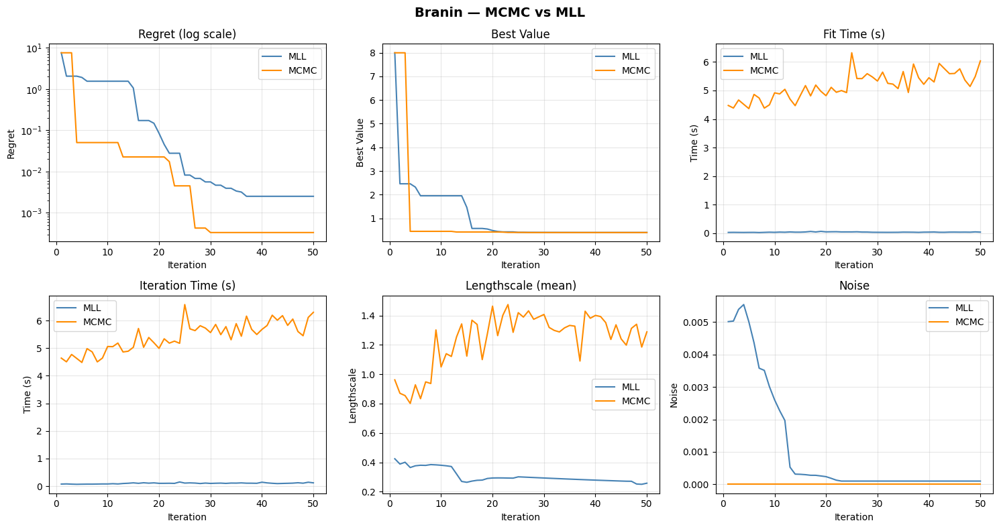

In [45]:
f = Branin()
setSeed(0)
X_init = generateInitialData(f.bounds, n=10)

results_mcmc = bo_loop_mcmc(f=f, X_init=X_init, maximize=False, num_loop=50)
results_mll = bo_loop_mll(f=f, X_init=X_init, maximize=False, num_loop=50)

plot_bo_comparison({
    "MLL": results_mll,
    "MCMC": results_mcmc
}, title="Branin — MCMC vs MLL")

# Main Experiments (deprecated): Main Experiments were done via run_experiments.py on the HPC Cluster

## Experiment 1

Run No. 0


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit

Done
MCMC seed 1/10 done
Run No. 1


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed on the second try, after generating a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), Optim

Done
MCMC seed 2/10 done
Run No. 2


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed on the second try, after generating a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), Optim

Done
MCMC seed 3/10 done
Run No. 3


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed on the second try, afte

Done
MCMC seed 4/10 done
Run No. 4


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit

Done
MCMC seed 5/10 done
Run No. 5


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scip

Done
MCMC seed 6/10 done
Run No. 6


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial

Done
MCMC seed 7/10 done
Run No. 7


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scip

Done
MCMC seed 8/10 done
Run No. 8


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed on the second try, afte

Done
MCMC seed 9/10 done
Run No. 9


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scip

Done
MCMC seed 10/10 done
MLL vs LOOCV:
  Median MLL: 0.0108
  Median LOOCV: 0.0000
  p-value: 0.0020
  p-corrected: 0.0059
  Signifikant: Ja
MLL vs MCMC:
  Median MLL: 0.0108
  Median MCMC: 0.0071
  p-value: 0.1934
  p-corrected: 0.5801
  Signifikant: Nein
LOOCV vs MCMC:
  Median LOOCV: 0.0000
  Median MCMC: 0.0071
  p-value: 0.0020
  p-corrected: 0.0059
  Signifikant: Ja


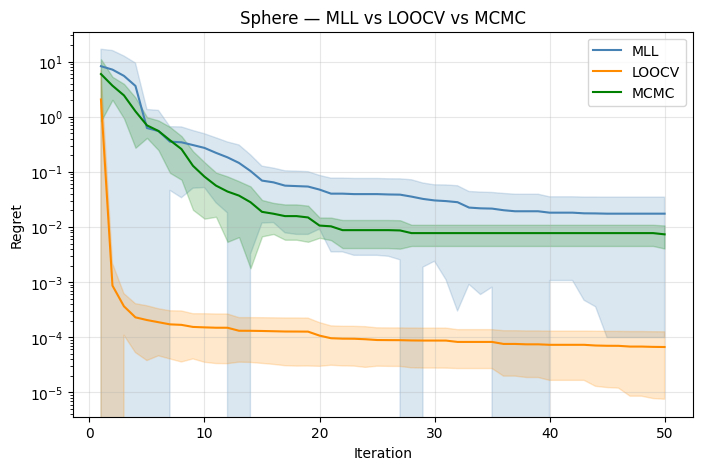

Run No. 0
Done
MCMC seed 1/10 done
Run No. 1
Done
MCMC seed 2/10 done
Run No. 2
Done
MCMC seed 3/10 done
Run No. 3
Done
MCMC seed 4/10 done
Run No. 4
Done
MCMC seed 5/10 done
Run No. 5
Done
MCMC seed 6/10 done
Run No. 6
Done
MCMC seed 7/10 done
Run No. 7
Done
MCMC seed 8/10 done
Run No. 8
Done
MCMC seed 9/10 done
Run No. 9
Done
MCMC seed 10/10 done
MLL vs LOOCV:
  Median MLL: 158.6685
  Median LOOCV: 183.0139
  p-value: 0.6953
  p-corrected: 1.0000
  Signifikant: Nein
MLL vs MCMC:
  Median MLL: 158.6685
  Median MCMC: 95.4039
  p-value: 0.1934
  p-corrected: 0.5801
  Signifikant: Nein
LOOCV vs MCMC:
  Median LOOCV: 183.0139
  Median MCMC: 95.4039
  p-value: 0.1602
  p-corrected: 0.4805
  Signifikant: Nein


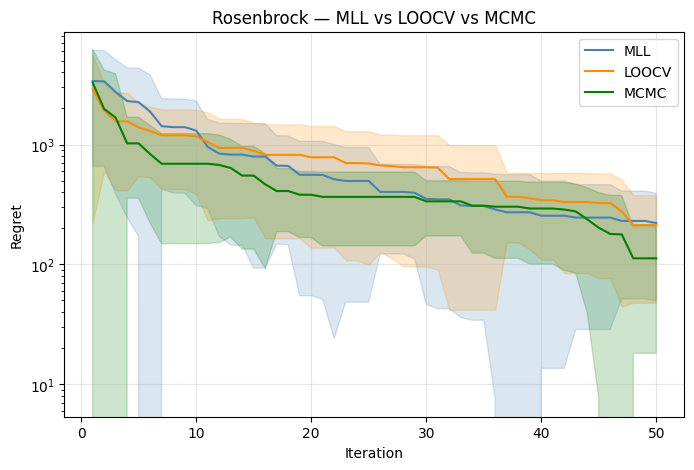

Run No. 0
Done
MCMC seed 1/10 done
Run No. 1
Done
MCMC seed 2/10 done
Run No. 2
Done
MCMC seed 3/10 done
Run No. 3
Done
MCMC seed 4/10 done
Run No. 4
Done
MCMC seed 5/10 done
Run No. 5
Done
MCMC seed 6/10 done
Run No. 6
Done
MCMC seed 7/10 done
Run No. 7
Done
MCMC seed 8/10 done
Run No. 8
Done
MCMC seed 9/10 done
Run No. 9
Done
MCMC seed 10/10 done
MLL vs LOOCV:
  Median MLL: 13653.6628
  Median LOOCV: 7423.6536
  p-value: 0.0645
  p-corrected: 0.1934
  Signifikant: Nein
MLL vs MCMC:
  Median MLL: 13653.6628
  Median MCMC: 11866.0958
  p-value: 0.9219
  p-corrected: 1.0000
  Signifikant: Nein
LOOCV vs MCMC:
  Median LOOCV: 7423.6536
  Median MCMC: 11866.0958
  p-value: 0.1602
  p-corrected: 0.4805
  Signifikant: Nein


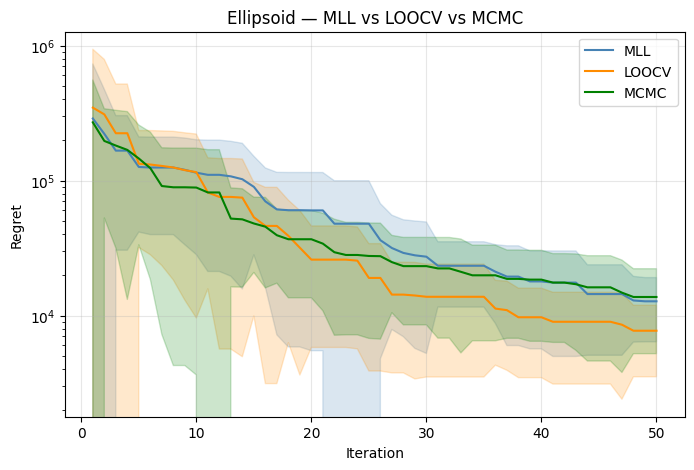

Run No. 0
Done
MCMC seed 1/10 done
Run No. 1
Done
MCMC seed 2/10 done
Run No. 2
Done
MCMC seed 3/10 done
Run No. 3
Done
MCMC seed 4/10 done
Run No. 4
Done
MCMC seed 5/10 done
Run No. 5
Done
MCMC seed 6/10 done
Run No. 6


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
MCMC seed 7/10 done
Run No. 7


d:\UniKrams\Bachelorarbeit\Projekt\Bachelorarbeit\.venv\lib\site-packages\botorch\optim\optimize.py:789: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Done
MCMC seed 8/10 done
Run No. 8
Done
MCMC seed 9/10 done
Run No. 9
Done
MCMC seed 10/10 done
MLL vs LOOCV:
  Median MLL: 44.2664
  Median LOOCV: 38.5163
  p-value: 0.2754
  p-corrected: 0.8262
  Signifikant: Nein
MLL vs MCMC:
  Median MLL: 44.2664
  Median MCMC: 37.9983
  p-value: 0.2754
  p-corrected: 0.8262
  Signifikant: Nein
LOOCV vs MCMC:
  Median LOOCV: 38.5163
  Median MCMC: 37.9983
  p-value: 0.8457
  p-corrected: 1.0000
  Signifikant: Nein


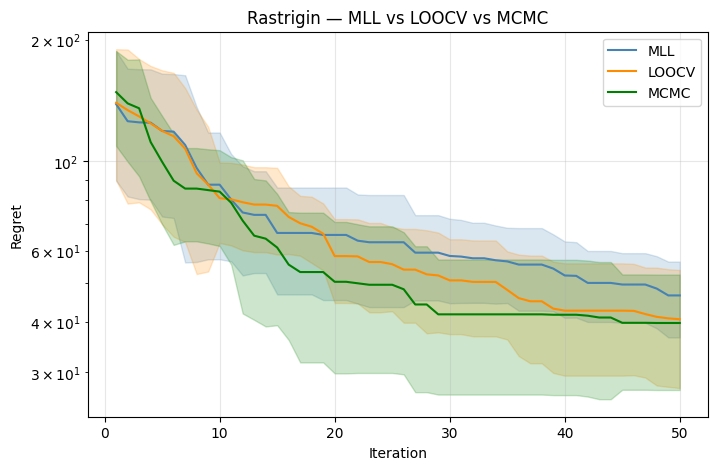

Run No. 0
Done
MCMC seed 1/10 done
Run No. 1
Done
MCMC seed 2/10 done
Run No. 2
Done
MCMC seed 3/10 done
Run No. 3
Done
MCMC seed 4/10 done
Run No. 4
Done
MCMC seed 5/10 done
Run No. 5
Done
MCMC seed 6/10 done
Run No. 6
Done
MCMC seed 7/10 done
Run No. 7
Done
MCMC seed 8/10 done
Run No. 8
Done
MCMC seed 9/10 done
Run No. 9
Done
MCMC seed 10/10 done
MLL vs LOOCV:
  Median MLL: 2.3428
  Median LOOCV: 3.7928
  p-value: 0.6953
  p-corrected: 1.0000
  Signifikant: Nein
MLL vs MCMC:
  Median MLL: 2.3428
  Median MCMC: 1.3873
  p-value: 0.1309
  p-corrected: 0.3926
  Signifikant: Nein
LOOCV vs MCMC:
  Median LOOCV: 3.7928
  Median MCMC: 1.3873
  p-value: 0.0488
  p-corrected: 0.1465
  Signifikant: Nein


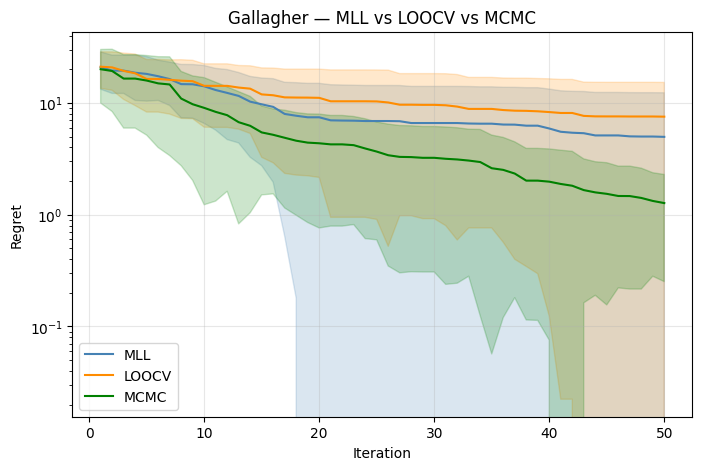

In [ ]:
experiments = []


#Experiment 1: Korrekte Spezifikation auf BBOB:
bbob_suite = [
    (1,  "Sphere"),
    (8,  "Rosenbrock"),
    (10, "Ellipsoid"),
    (15, "Rastrigin"),
    (21, "Gallagher"),
]

for fid, name in bbob_suite:
    f = get_bbob_wrapper(fid=fid, instance=1, dimension=5,seed = 1)
    results = bo_experiment_parallel(
        f=f, n_runs=10, num_loop=50,
        bo_loops=[
            ("MLL",   bo_loop_mll),
            ("LOOCV", bo_loop_loocv),
            ("MCMC",  bo_loop_mcmc),
        ]
    )
    save_experiment(results, title=f"{name} — MLL vs LOOCV vs MCMC", save_path= f"experiments/experiment_1/{name}")
    plot_regret_with_std(results["regrets"], title=f"{name} — MLL vs LOOCV vs MCMC")
    experiments.append((name, results))


In [ ]:
#speichern der MCMC regrets da sie zeitlich sehr aufwendig zu kriegen sind damit sie nur einmal berechnet werden müssen
mcmc_regrets = {}
mcmc_fit_times = {}

for (name,results) in experiments:
    if "MCMC" in results["regrets"]:
        mcmc_regrets[name] = results["regrets"]["MCMC"]
        mcmc_fit_times[name] = results["fit_times"]["MCMC"]

#Speichern in Backups
with open("backups/mcmc_regrets_backup_temp.pkl", "wb") as f:
    pickle.dump(mcmc_regrets,f)

with open("backups/mcmc_fit_times_backup_temp.pkl", "wb") as f:
    pickle.dump(mcmc_fit_times,f)

## Experiment 2

### Version 1

MLL vs LOOCV:
  Median MLL: 0.0049
  Median LOOCV: 0.0282
  p-value: 0.0137
  p-corrected: 0.0137
  Signifikant: Ja


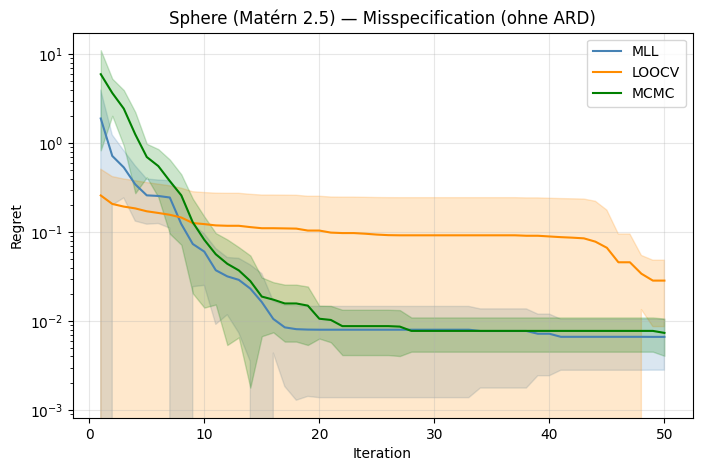

MLL vs LOOCV:
  Median MLL: 0.1021
  Median LOOCV: 0.0475
  p-value: 0.2324
  p-corrected: 0.2324
  Signifikant: Nein


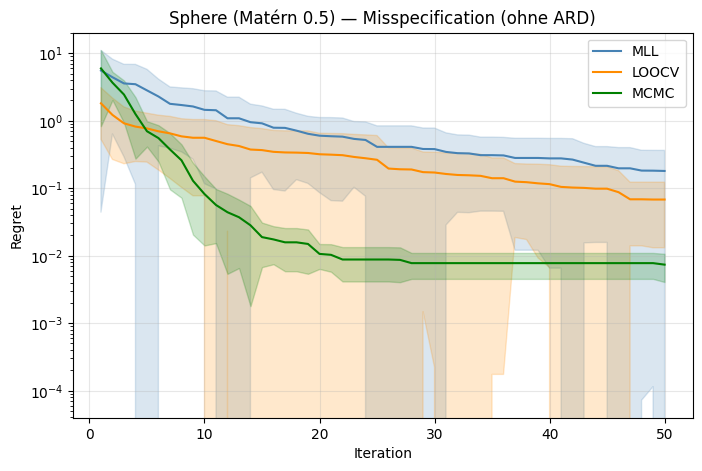

MLL vs LOOCV:
  Median MLL: 0.0142
  Median LOOCV: 0.0101
  p-value: 0.4922
  p-corrected: 0.4922
  Signifikant: Nein


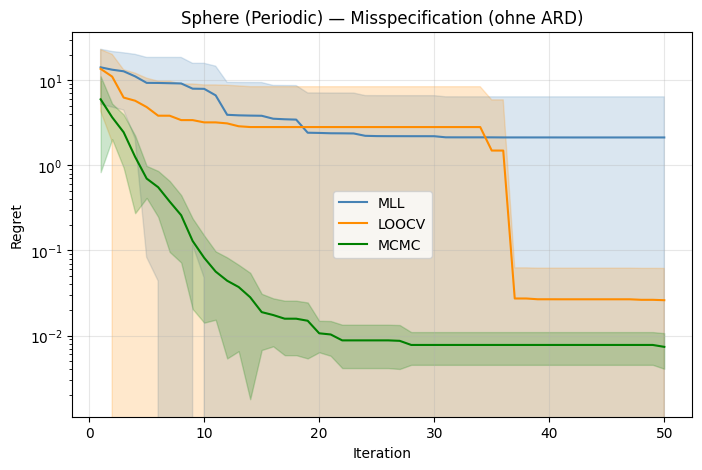

MLL vs LOOCV:
  Median MLL: 118.5814
  Median LOOCV: 129.6375
  p-value: 0.3223
  p-corrected: 0.3223
  Signifikant: Nein


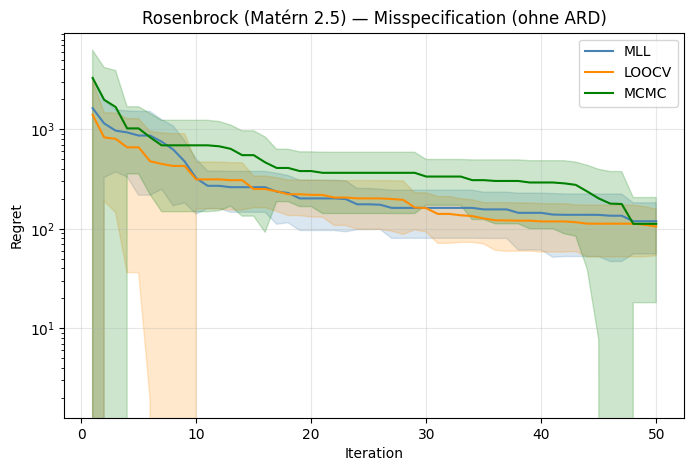

MLL vs LOOCV:
  Median MLL: 160.7793
  Median LOOCV: 184.0280
  p-value: 0.6953
  p-corrected: 0.6953
  Signifikant: Nein


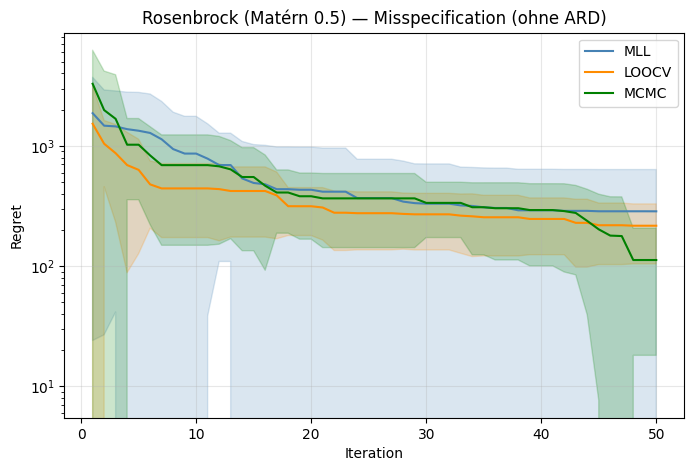

MLL vs LOOCV:
  Median MLL: 149.2542
  Median LOOCV: 179.7599
  p-value: 0.9219
  p-corrected: 0.9219
  Signifikant: Nein


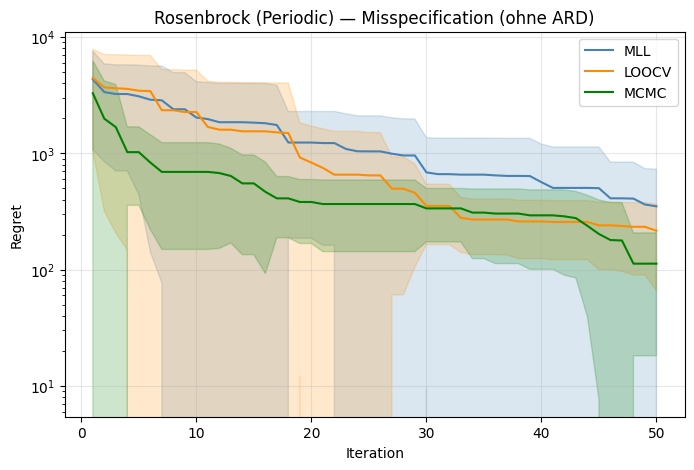

MLL vs LOOCV:
  Median MLL: 20347.6702
  Median LOOCV: 11285.7506
  p-value: 0.0273
  p-corrected: 0.0273
  Signifikant: Ja


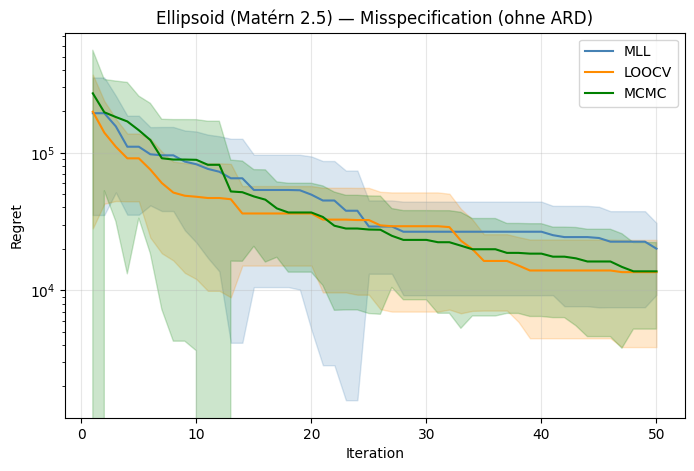

MLL vs LOOCV:
  Median MLL: 13713.9184
  Median LOOCV: 21531.7446
  p-value: 0.4922
  p-corrected: 0.4922
  Signifikant: Nein


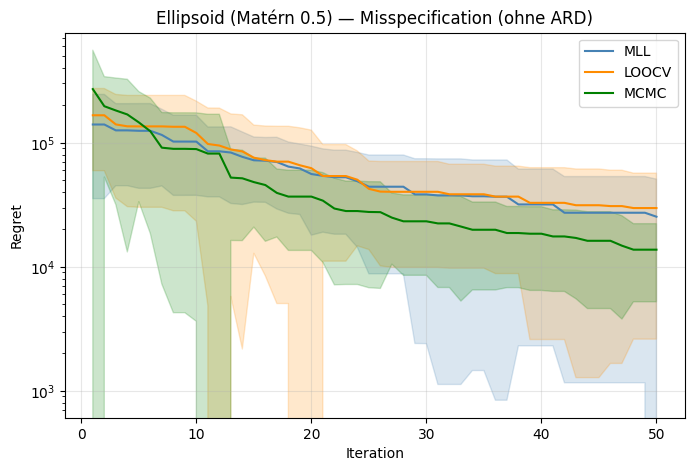

MLL vs LOOCV:
  Median MLL: 19266.2822
  Median LOOCV: 7503.5966
  p-value: 0.3008
  p-corrected: 0.3008
  Signifikant: Nein


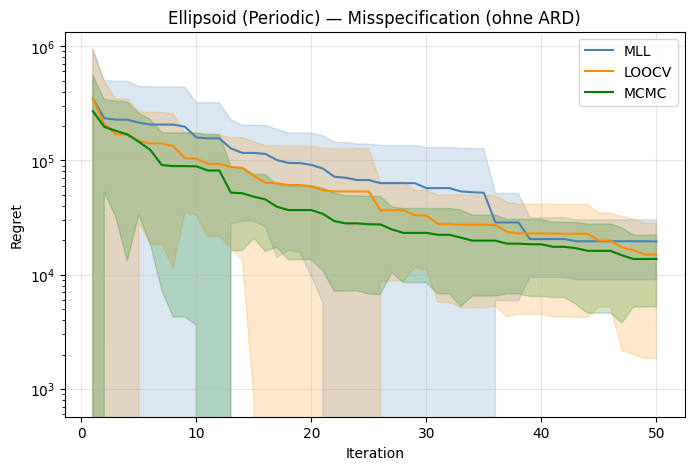

MLL vs LOOCV:
  Median MLL: 39.8374
  Median LOOCV: 40.2719
  p-value: 0.4922
  p-corrected: 0.4922
  Signifikant: Nein


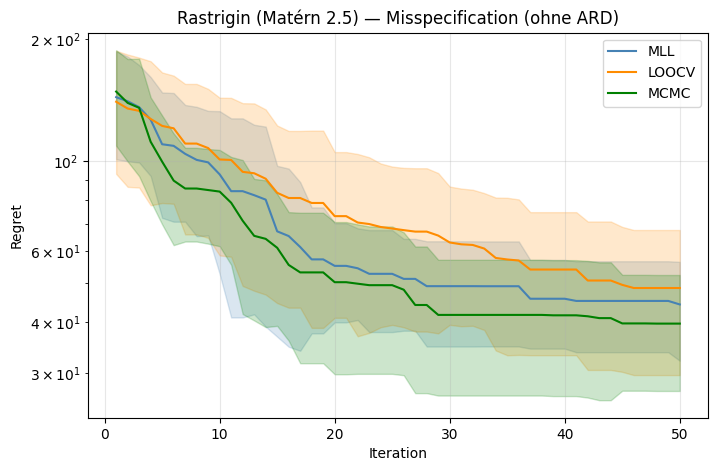

MLL vs LOOCV:
  Median MLL: 47.9975
  Median LOOCV: 54.5302
  p-value: 0.2754
  p-corrected: 0.2754
  Signifikant: Nein


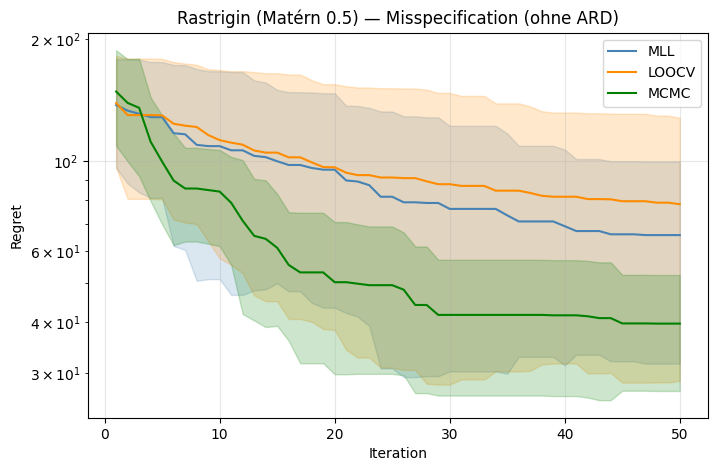

MLL vs LOOCV:
  Median MLL: 66.6977
  Median LOOCV: 48.9103
  p-value: 0.1602
  p-corrected: 0.1602
  Signifikant: Nein


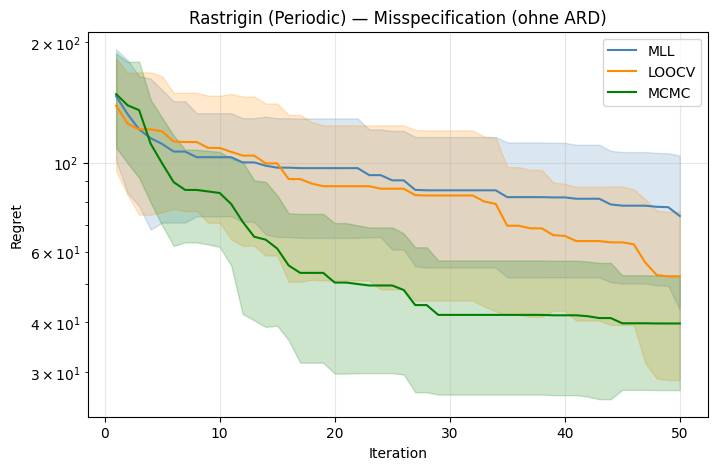

MLL vs LOOCV:
  Median MLL: 1.9516
  Median LOOCV: 1.6137
  p-value: 1.0000
  p-corrected: 1.0000
  Signifikant: Nein


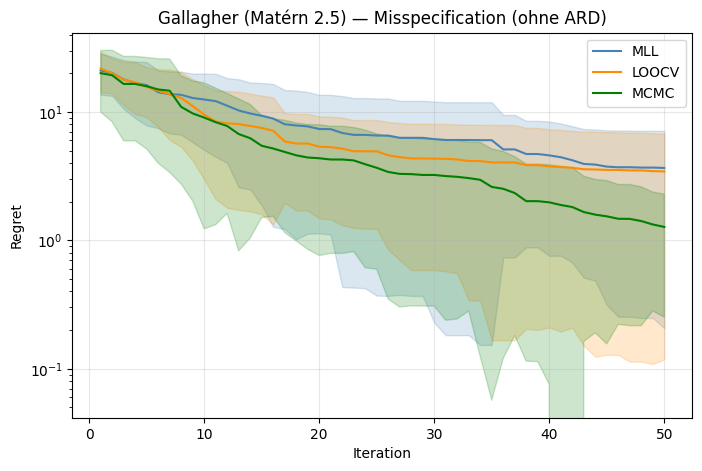

MLL vs LOOCV:
  Median MLL: 6.6918
  Median LOOCV: 6.7632
  p-value: 0.4922
  p-corrected: 0.4922
  Signifikant: Nein


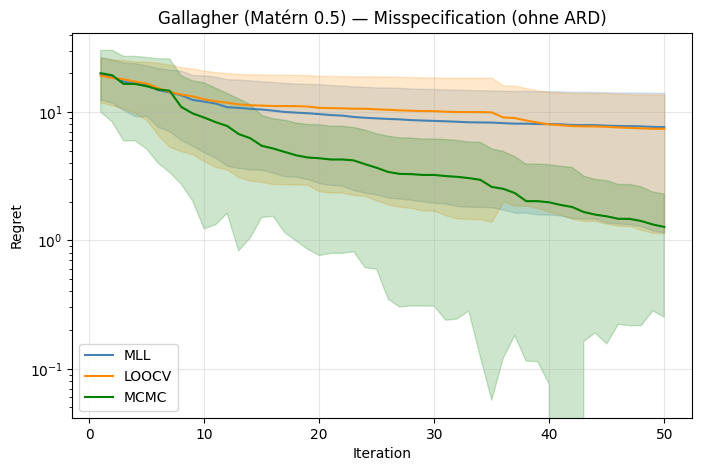

MLL vs LOOCV:
  Median MLL: 1.4910
  Median LOOCV: 1.9079
  p-value: 0.0371
  p-corrected: 0.0371
  Signifikant: Ja


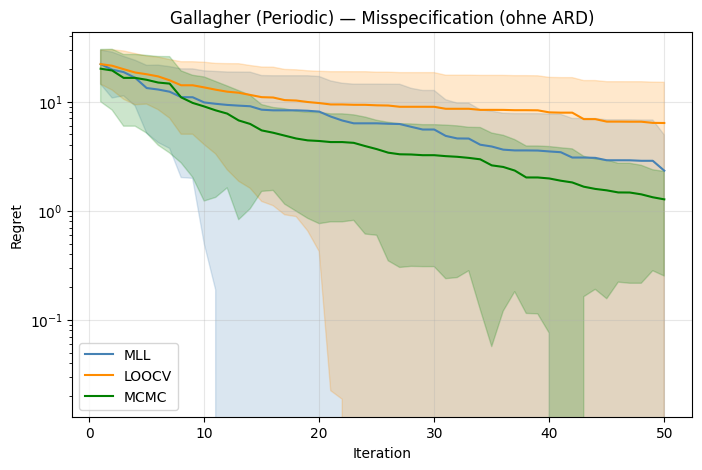

             Experiment Method A   Median A Method B   Median B  p-value Signifikant?
    Sphere (Matérn 2.5)      MLL     0.0049    LOOCV     0.0282   0.0410           Ja
    Sphere (Matérn 2.5)      MLL     0.0049     MCMC     0.0071   1.0000         Nein
    Sphere (Matérn 2.5)    LOOCV     0.0282     MCMC     0.0071   0.0820         Nein
    Sphere (Matérn 0.5)      MLL     0.1021    LOOCV     0.0475   0.6973         Nein
    Sphere (Matérn 0.5)      MLL     0.1021     MCMC     0.0071   0.0059           Ja
    Sphere (Matérn 0.5)    LOOCV     0.0475     MCMC     0.0071   0.0059           Ja
      Sphere (Periodic)      MLL     0.0142    LOOCV     0.0101   1.0000         Nein
      Sphere (Periodic)      MLL     0.0142     MCMC     0.0071   0.0293           Ja
      Sphere (Periodic)    LOOCV     0.0101     MCMC     0.0071   1.0000         Nein
Rosenbrock (Matérn 2.5)      MLL   118.5814    LOOCV   129.6375   0.9668         Nein
Rosenbrock (Matérn 2.5)      MLL   118.5814     MCMC  

In [ ]:
#Experiment 2: Misspecification auf BBOB (MCMC kernel nicht veränderbar):
#Version 1: without ARD without Priors

test_experiment = []

with open("backups/mcmc_regrets_backup_temp.pkl", "rb") as f:
    mcmc_regrets = pickle.load(f)

with open("backups/mcmc_fit_times_backup_temp.pkl", "rb") as f:
    mcmc_fit_times = pickle.load(f)

bbob_suite = [
    (1,  "Sphere"),
    (8,  "Rosenbrock"),
    (10, "Ellipsoid"),
    (15, "Rastrigin"),
    (21, "Gallagher"),
]


misspec_configs = [
    ("Matérn 2.5", lambda: MaternKernel(nu=2.5)),
    ("Matérn 0.5", lambda: MaternKernel(nu=0.5)),
    ("Periodic",   lambda: PeriodicKernel()),
]

for fid, name in bbob_suite:
    f = get_bbob_wrapper(fid=fid, instance=1, dimension=5, seed = 1)
    for misspec_name, misspec_kernel in misspec_configs:
        results = bo_experiment_parallel(
            f=f, n_runs=10, num_loop=50,
            kernel=misspec_kernel(),
            bo_loops=[
                ("MLL",   bo_loop_mll),
                ("LOOCV", bo_loop_loocv),
            ])
        title = f"{name} ({misspec_name}) — Misspecification (ohne ARD)"

        if name in mcmc_regrets:
            results["regrets"]["MCMC"] = mcmc_regrets[name]
            results["fit_times"]["MCMC"] = mcmc_fit_times[name]

        plot_regret_with_std(results["regrets"], title=title)
        save_experiment(results, title = title, save_path= f"../experiments/experiment_2_v1/{name}")

        experiments.append((f"{name} ({misspec_name})", results["regrets"]))
        test_experiment.append((f"{name} ({misspec_name})", results))
    
table = build_summary_table(test_experiment)
print(table.to_string(index = False))

### Version 2

MLL vs LOOCV:
  Median MLL: 3.7071
  Median LOOCV: 0.0004
  p-value: 0.0020
  p-corrected: 0.0020
  Signifikant: Ja


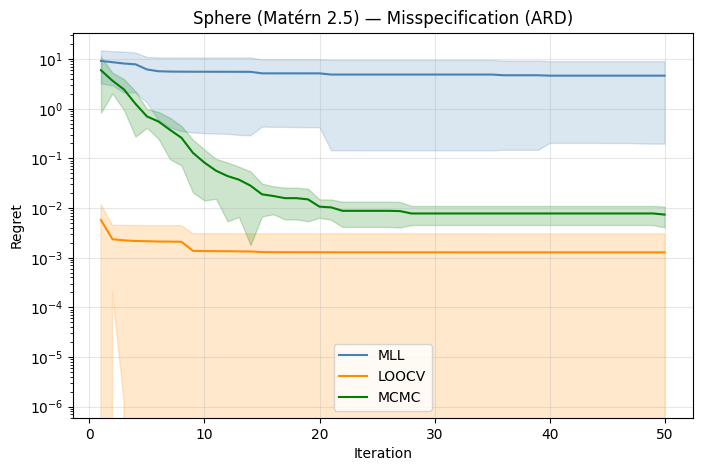

MLL vs LOOCV:
  Median MLL: 3.5856
  Median LOOCV: 0.0724
  p-value: 0.0039
  p-corrected: 0.0039
  Signifikant: Ja


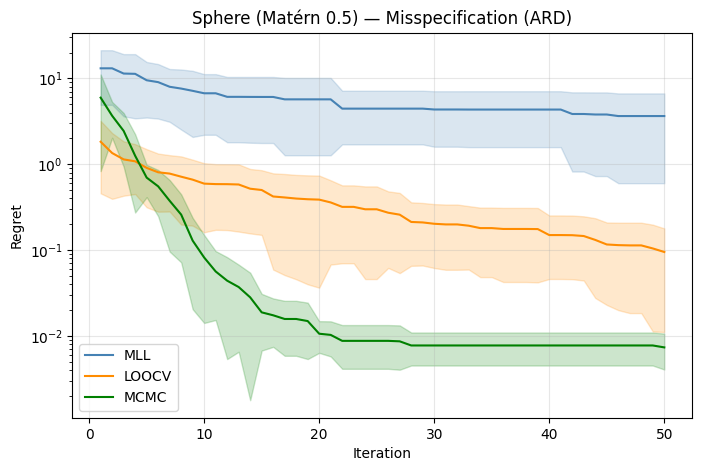

MLL vs LOOCV:
  Median MLL: 4.0746
  Median LOOCV: 6.9786
  p-value: 0.4961
  p-corrected: 0.4961
  Signifikant: Nein


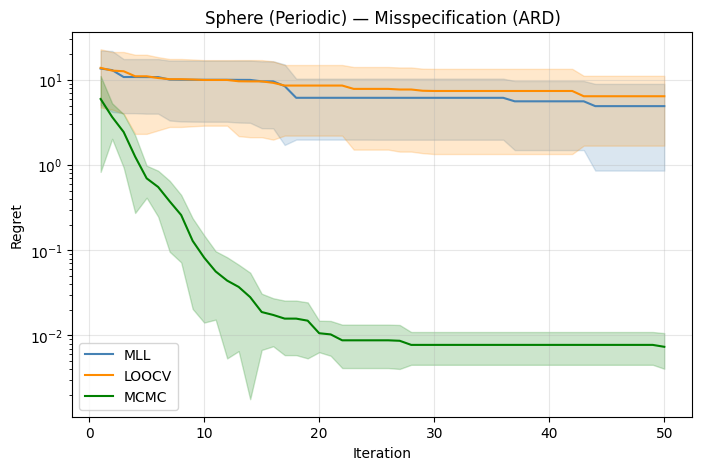

MLL vs LOOCV:
  Median MLL: 494.1745
  Median LOOCV: 557.3061
  p-value: 0.9102
  p-corrected: 0.9102
  Signifikant: Nein


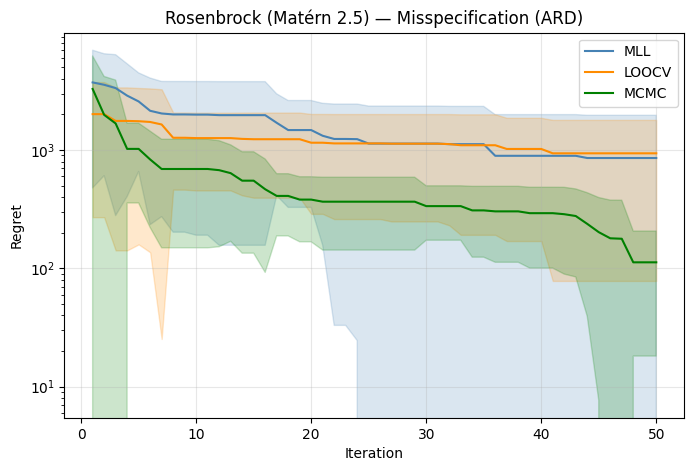

MLL vs LOOCV:
  Median MLL: 306.2468
  Median LOOCV: 313.6357
  p-value: 0.3594
  p-corrected: 0.3594
  Signifikant: Nein


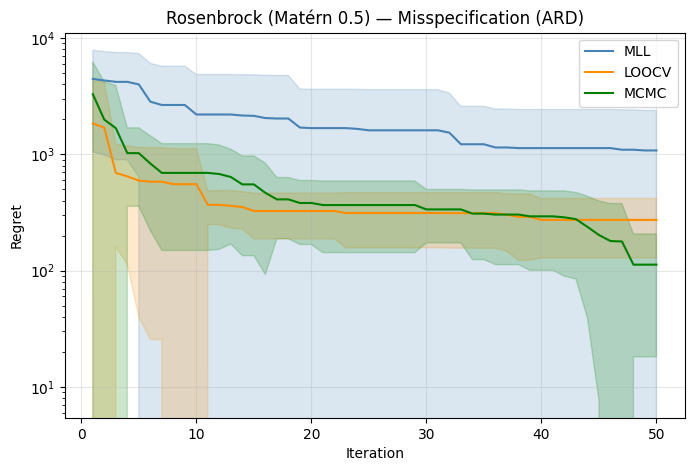

MLL vs LOOCV:
  Median MLL: 956.5156
  Median LOOCV: 944.0112
  p-value: 0.3125
  p-corrected: 0.3125
  Signifikant: Nein


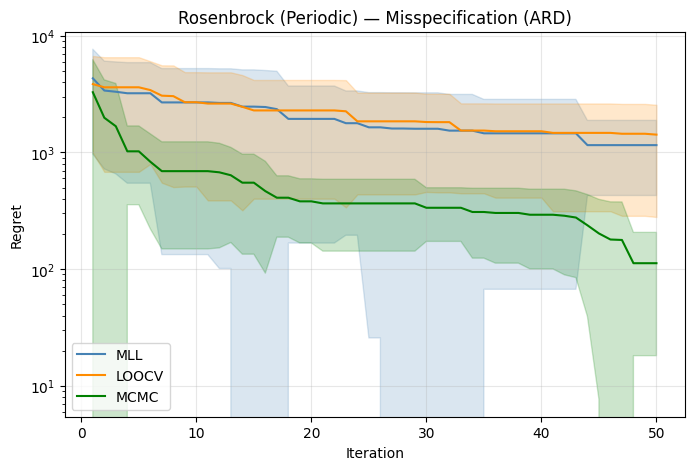

MLL vs LOOCV:
  Median MLL: 18435.0408
  Median LOOCV: 12047.8876
  p-value: 0.3750
  p-corrected: 0.3750
  Signifikant: Nein


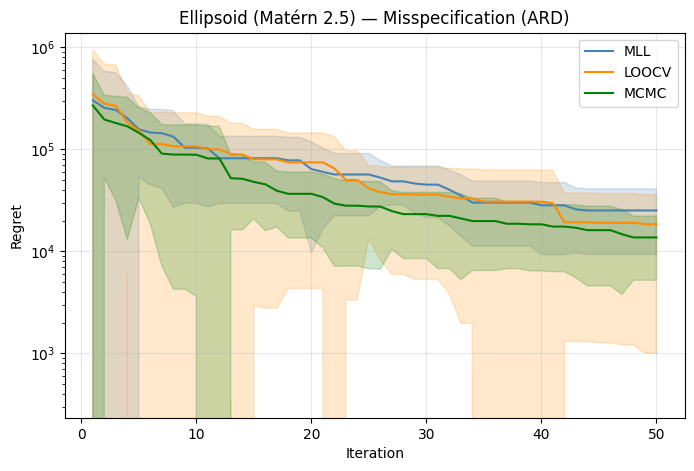

MLL vs LOOCV:
  Median MLL: 42957.2464
  Median LOOCV: 10543.2527
  p-value: 0.1055
  p-corrected: 0.1055
  Signifikant: Nein


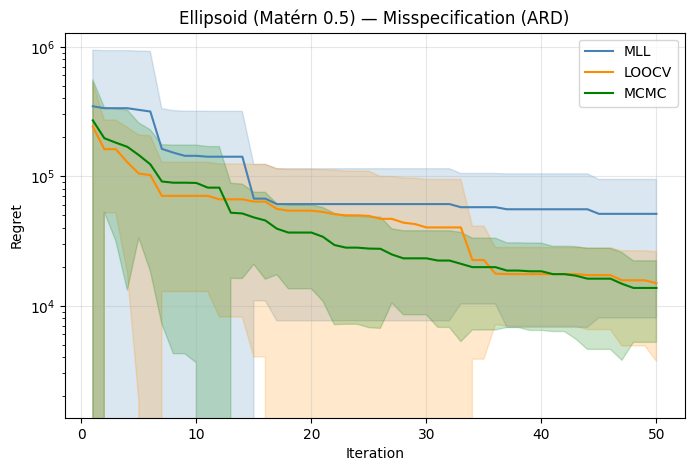

MLL vs LOOCV:
  Median MLL: 58865.5691
  Median LOOCV: 82252.8961
  p-value: 0.1094
  p-corrected: 0.1094
  Signifikant: Nein


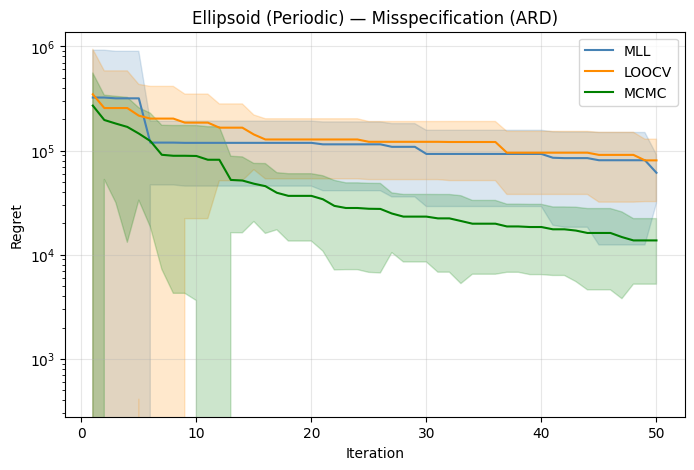

MLL vs LOOCV:
  Median MLL: 51.4980
  Median LOOCV: 49.3893
  p-value: 0.8457
  p-corrected: 0.8457
  Signifikant: Nein


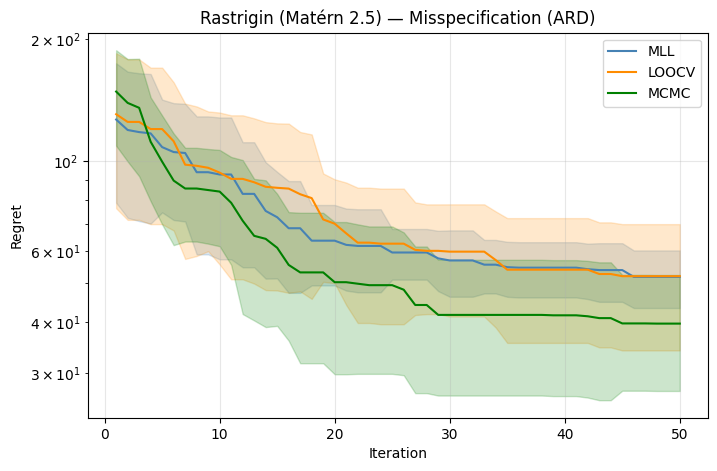

MLL vs LOOCV:
  Median MLL: 49.0273
  Median LOOCV: 62.4129
  p-value: 0.9219
  p-corrected: 0.9219
  Signifikant: Nein


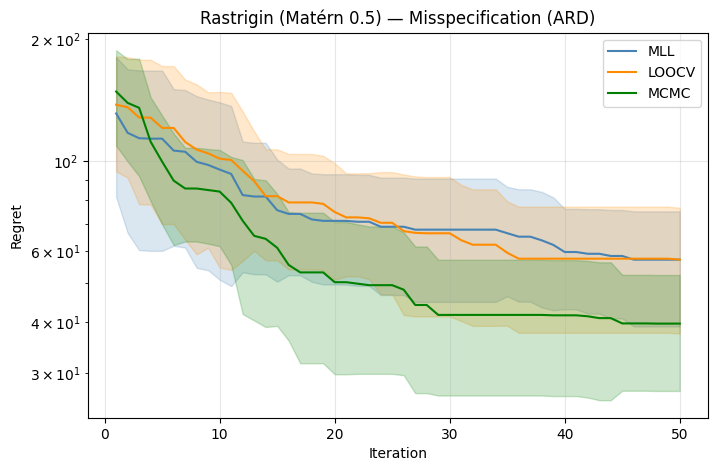

MLL vs LOOCV:
  Median MLL: 55.8541
  Median LOOCV: 88.0380
  p-value: 0.0488
  p-corrected: 0.0488
  Signifikant: Ja


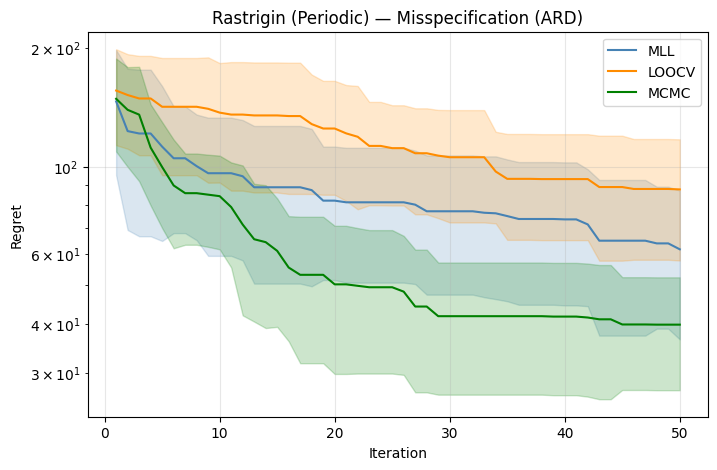

MLL vs LOOCV:
  Median MLL: 12.0864
  Median LOOCV: 15.6259
  p-value: 0.9102
  p-corrected: 0.9102
  Signifikant: Nein


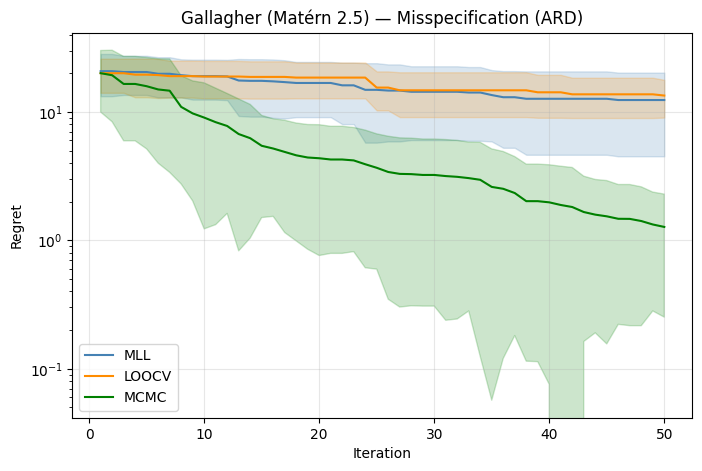

MLL vs LOOCV:
  Median MLL: 7.5599
  Median LOOCV: 11.4031
  p-value: 0.3008
  p-corrected: 0.3008
  Signifikant: Nein


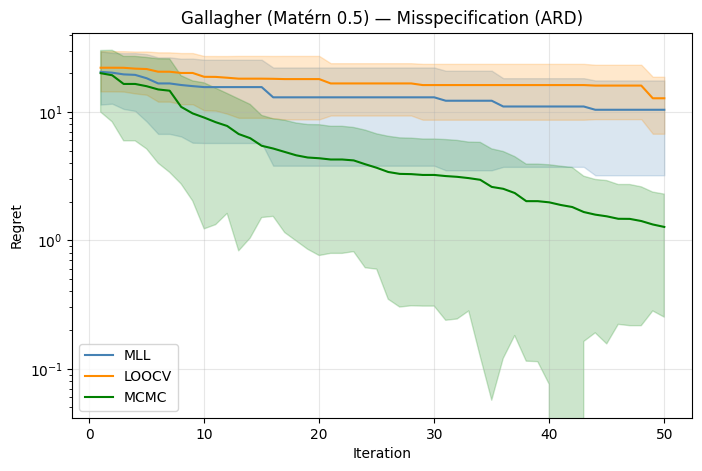

MLL vs LOOCV:
  Median MLL: 15.9747
  Median LOOCV: 10.7097
  p-value: 0.1289
  p-corrected: 0.1289
  Signifikant: Nein


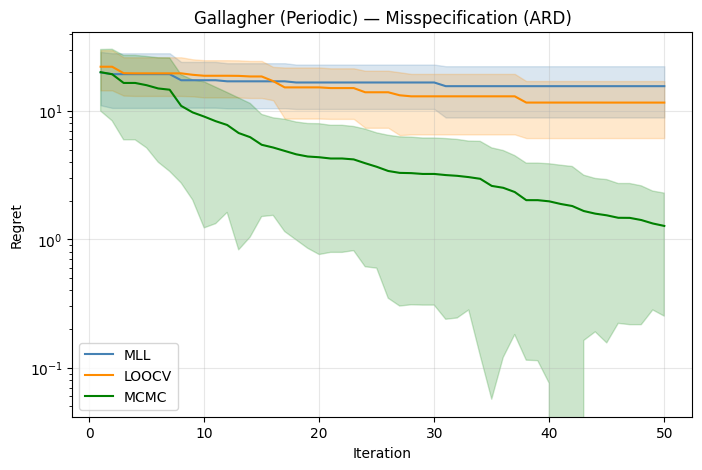

             Experiment Method A   Median A Method B   Median B  p-value Signifikant?
    Sphere (Matérn 2.5)      MLL     3.7071    LOOCV     0.0004   0.0059           Ja
    Sphere (Matérn 2.5)      MLL     3.7071     MCMC     0.0071   0.0820         Nein
    Sphere (Matérn 2.5)    LOOCV     0.0004     MCMC     0.0071   0.0293           Ja
    Sphere (Matérn 0.5)      MLL     3.5856    LOOCV     0.0724   0.0117           Ja
    Sphere (Matérn 0.5)      MLL     3.5856     MCMC     0.0071   0.0117           Ja
    Sphere (Matérn 0.5)    LOOCV     0.0724     MCMC     0.0071   0.0059           Ja
      Sphere (Periodic)      MLL     4.0746    LOOCV     6.9786   1.0000         Nein
      Sphere (Periodic)      MLL     4.0746     MCMC     0.0071   0.0117           Ja
      Sphere (Periodic)    LOOCV     6.9786     MCMC     0.0071   0.0293           Ja
Rosenbrock (Matérn 2.5)      MLL   494.1745    LOOCV   557.3061   1.0000         Nein
Rosenbrock (Matérn 2.5)      MLL   494.1745     MCMC  

In [ ]:
#Experiment 2: Misspecification auf BBOB (MCMC kernel nicht veränderbar):
#Version 2: with ARD without Priors

test_experiment = []

misspec_configs = [
    ("Matérn 2.5", lambda: MaternKernel(nu=2.5, ard_num_dims = 5)),
    ("Matérn 0.5", lambda: MaternKernel(nu=0.5, ard_num_dims = 5)),
    ("Periodic",   lambda: PeriodicKernel(ard_num_dims = 5)),
]

for fid, name in bbob_suite:
    f = get_bbob_wrapper(fid=fid, instance=1, dimension=5, seed = 1)
    for misspec_name, misspec_kernel in misspec_configs:
        results = bo_experiment_parallel(
            f=f, n_runs=10, num_loop=50,
            kernel=misspec_kernel(),
            bo_loops=[
                ("MLL",   bo_loop_mll),
                ("LOOCV", bo_loop_loocv),
            ])
        title = f"{name} ({misspec_name}) — Misspecification (ARD)"

        if name in mcmc_regrets:
            results["regrets"]["MCMC"] = mcmc_regrets[name]
            results["fit_times"]["MCMC"] = mcmc_fit_times[name]

        plot_regret_with_std(results["regrets"], title=title)
        save_experiment(results["regrets"], title = title, save_path= f"../experiments/experiment_2_v2/{name}")

        experiments.append((f"{name} ({misspec_name})", results))
        test_experiment.append((f"{name} ({misspec_name})", results))
    
table = build_summary_table(test_experiment)
print(table.to_string(index = False))

### Version 3

MLL vs LOOCV:
  Median MLL: 0.0078
  Median LOOCV: 0.0004
  p-value: 0.0020
  p-corrected: 0.0020
  Signifikant: Ja


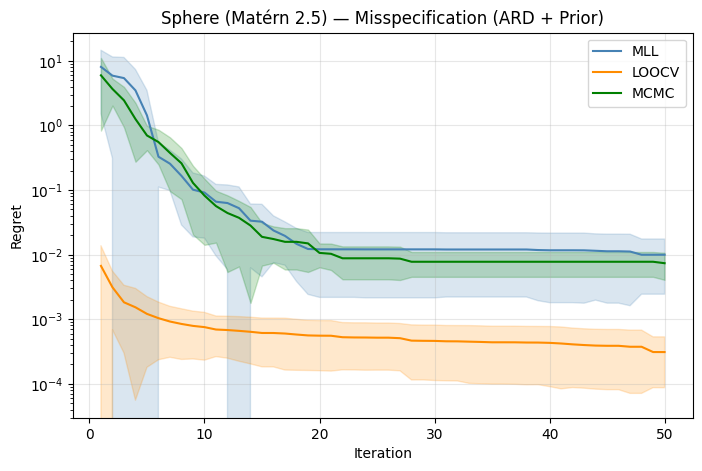

MLL vs LOOCV:
  Median MLL: 0.2329
  Median LOOCV: 0.0476
  p-value: 0.0059
  p-corrected: 0.0059
  Signifikant: Ja


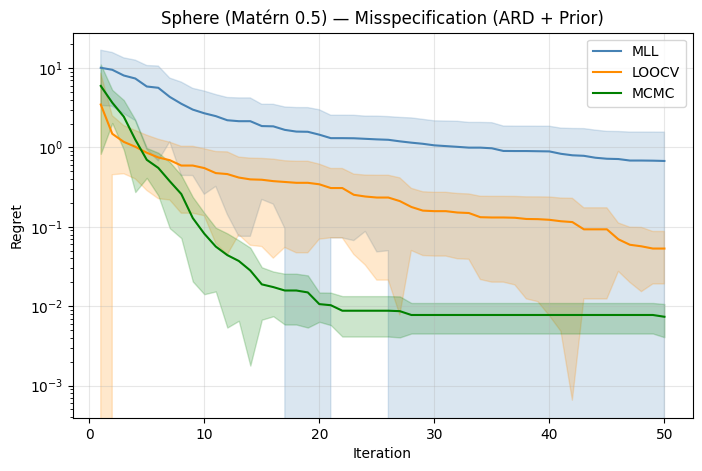

MLL vs LOOCV:
  Median MLL: 240.0251
  Median LOOCV: 48.8704
  p-value: 0.0020
  p-corrected: 0.0020
  Signifikant: Ja


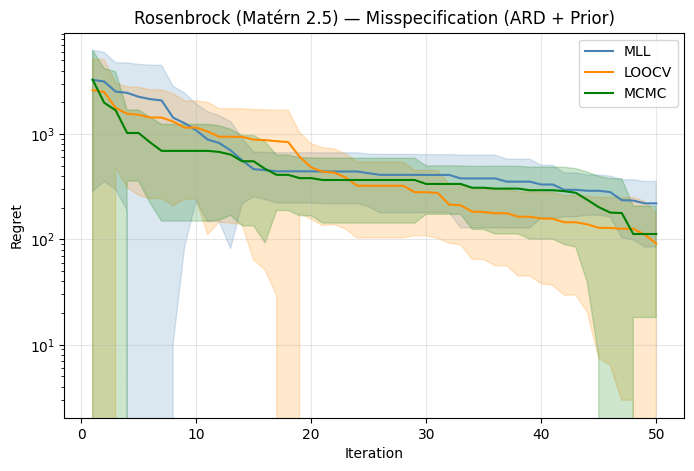

MLL vs LOOCV:
  Median MLL: 201.9248
  Median LOOCV: 161.4619
  p-value: 0.7695
  p-corrected: 0.7695
  Signifikant: Nein


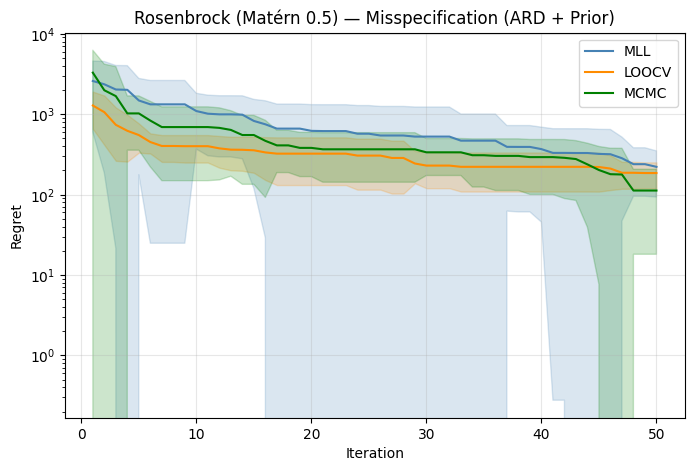

MLL vs LOOCV:
  Median MLL: 9041.7500
  Median LOOCV: 12005.5687
  p-value: 0.8457
  p-corrected: 0.8457
  Signifikant: Nein


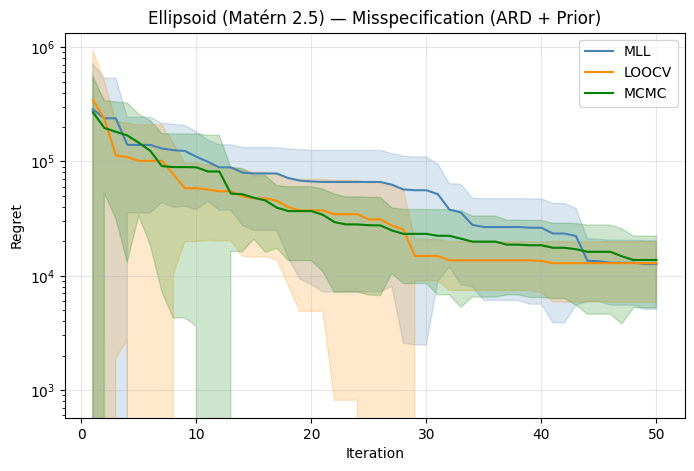

MLL vs LOOCV:
  Median MLL: 29808.4259
  Median LOOCV: 7957.2127
  p-value: 0.0273
  p-corrected: 0.0273
  Signifikant: Ja


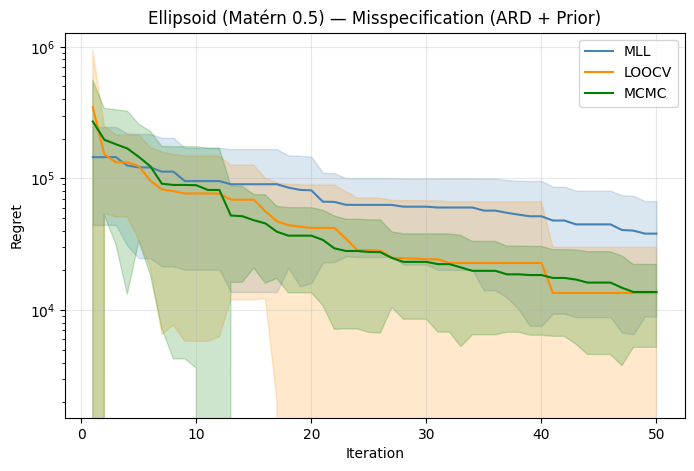

MLL vs LOOCV:
  Median MLL: 41.0300
  Median LOOCV: 35.9655
  p-value: 0.5566
  p-corrected: 0.5566
  Signifikant: Nein


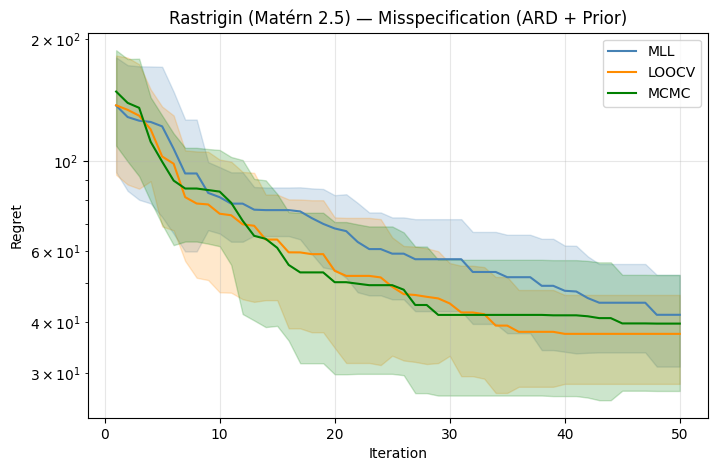

MLL vs LOOCV:
  Median MLL: 39.8327
  Median LOOCV: 51.6426
  p-value: 0.5566
  p-corrected: 0.5566
  Signifikant: Nein


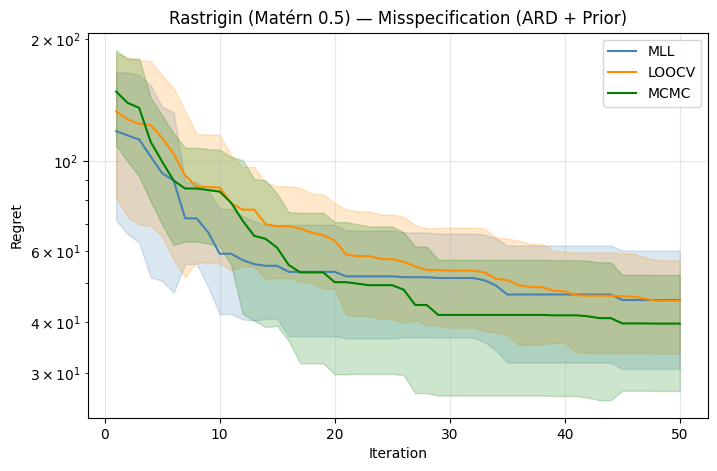

MLL vs LOOCV:
  Median MLL: 1.9026
  Median LOOCV: 1.5025
  p-value: 0.7695
  p-corrected: 0.7695
  Signifikant: Nein


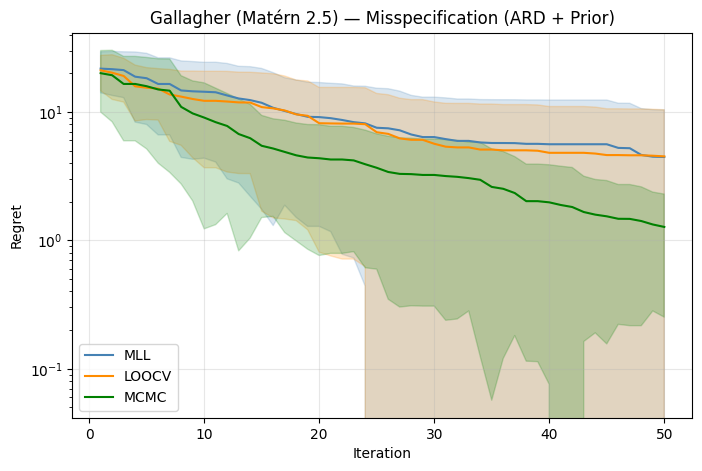

MLL vs LOOCV:
  Median MLL: 7.3173
  Median LOOCV: 7.9187
  p-value: 0.2324
  p-corrected: 0.2324
  Signifikant: Nein


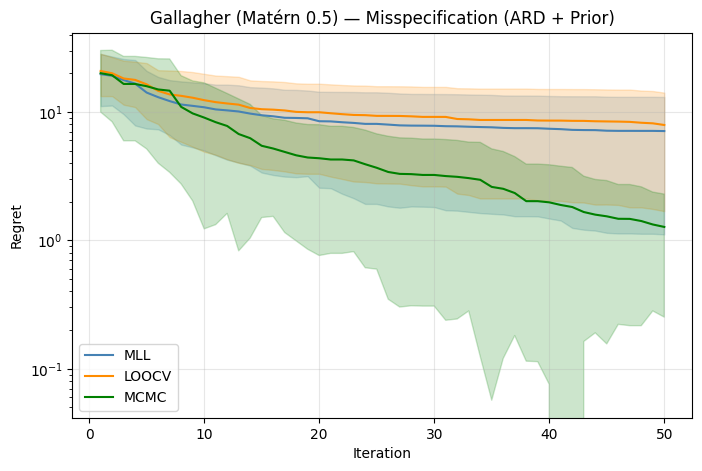

             Experiment Method A   Median A Method B   Median B  p-value Signifikant?
    Sphere (Matérn 2.5)      MLL     0.0078    LOOCV     0.0004   0.0059           Ja
    Sphere (Matérn 2.5)      MLL     0.0078     MCMC     0.0071   1.0000         Nein
    Sphere (Matérn 2.5)    LOOCV     0.0004     MCMC     0.0071   0.0059           Ja
    Sphere (Matérn 0.5)      MLL     0.2329    LOOCV     0.0476   0.0176           Ja
    Sphere (Matérn 0.5)      MLL     0.2329     MCMC     0.0071   0.0059           Ja
    Sphere (Matérn 0.5)    LOOCV     0.0476     MCMC     0.0071   0.0059           Ja
Rosenbrock (Matérn 2.5)      MLL   240.0251    LOOCV    48.8704   0.0059           Ja
Rosenbrock (Matérn 2.5)      MLL   240.0251     MCMC    95.4039   0.1934         Nein
Rosenbrock (Matérn 2.5)    LOOCV    48.8704     MCMC    95.4039   1.0000         Nein
Rosenbrock (Matérn 0.5)      MLL   201.9248    LOOCV   161.4619   1.0000         Nein
Rosenbrock (Matérn 0.5)      MLL   201.9248     MCMC  

In [ ]:
from math import sqrt, log
from gpytorch.priors import LogNormalPrior
from gpytorch.constraints import GreaterThan

#prior mit drin behalten
def make_misspecified_kernel(d, nu=0.5):
    lengthscale_prior = LogNormalPrior(
        loc=sqrt(2) + log(d) * 0.5,
        scale=sqrt(3)
    )
    
    return MaternKernel(
        nu=nu,
        ard_num_dims=d,
        lengthscale_prior=lengthscale_prior,
        lengthscale_constraint=GreaterThan(
            0.025,
            transform=None,
            initial_value=lengthscale_prior.mode,
        ),
    )

#Experiment 2: Misspecification auf BBOB (MCMC kernel nicht veränderbar):
#Version 3: with ARD with Priors

test_experiment = []
misspec_configs = [
    ("Matérn 2.5", lambda: make_misspecified_kernel(nu=2.5, d = 5)),
    ("Matérn 0.5", lambda: make_misspecified_kernel(nu=0.5, d = 5)),
]

for fid, name in bbob_suite:
    f = get_bbob_wrapper(fid=fid, instance=1, dimension=5, seed = 1)
    for misspec_name, misspec_kernel in misspec_configs:
        results = bo_experiment_parallel(
            f=f, n_runs=10, num_loop=50,
            kernel=misspec_kernel(),
            bo_loops=[
                ("MLL",   bo_loop_mll),
                ("LOOCV", bo_loop_loocv),
                ("MCMC", bo_loop_mcmc),
            ])
        title = f"{name} ({misspec_name}) — Misspecification (ARD + Prior)"

        if name in mcmc_regrets:
            results["regrets"]["MCMC"] = mcmc_regrets[name]
            results["fit_times"]["MCMC"] = mcmc_fit_times[name]

        plot_regret_with_std(results["regrets"], title=title)
        save_experiment(results, title = title, save_path= f"../experiments/experiment_2_v3/{name}")

        test_experiment.append((f"{name} ({misspec_name})", results))
    
table = build_summary_table(test_experiment)
print(table.to_string(index = False))


## Experiment 3

MLL vs LOOCV:
  Median MLL: 1.2397
  Median LOOCV: 1.1298
  p-value: 0.8457
  p-corrected: 0.8457
  Signifikant: Nein


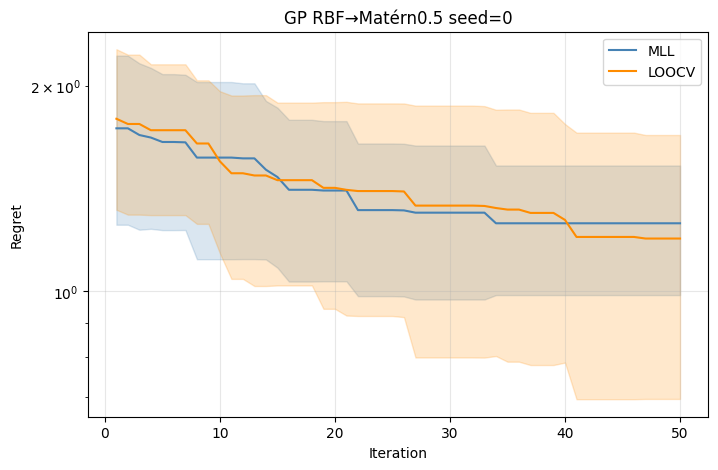

MLL vs LOOCV:
  Median MLL: 1.6501
  Median LOOCV: 1.8002
  p-value: 0.4922
  p-corrected: 0.4922
  Signifikant: Nein


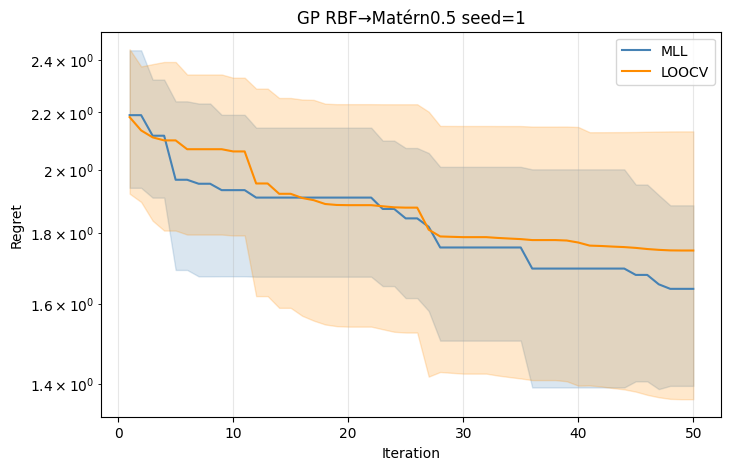

MLL vs LOOCV:
  Median MLL: 0.9181
  Median LOOCV: 1.1995
  p-value: 0.1934
  p-corrected: 0.1934
  Signifikant: Nein


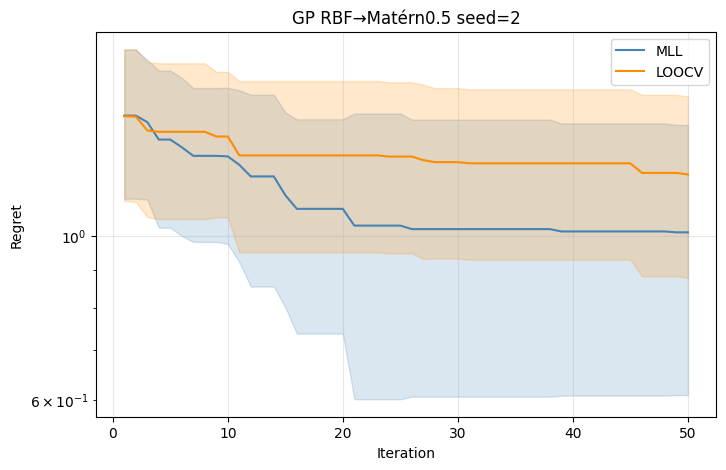

MLL vs LOOCV:
  Median MLL: 1.2765
  Median LOOCV: 1.1898
  p-value: 0.8457
  p-corrected: 0.8457
  Signifikant: Nein


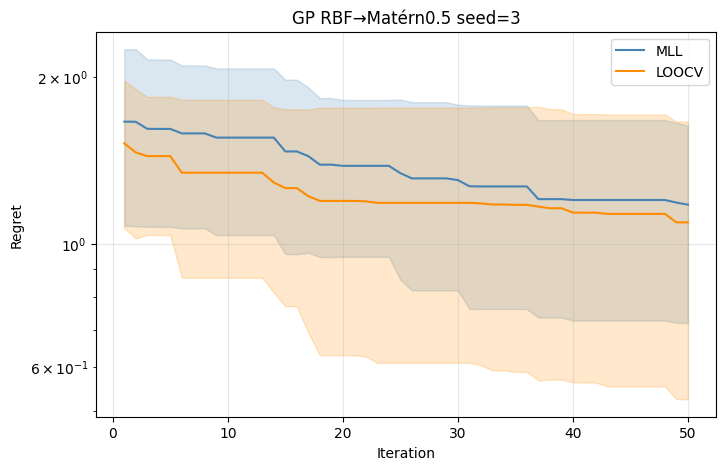

MLL vs LOOCV:
  Median MLL: 2.8247
  Median LOOCV: 2.6659
  p-value: 0.0488
  p-corrected: 0.0488
  Signifikant: Ja


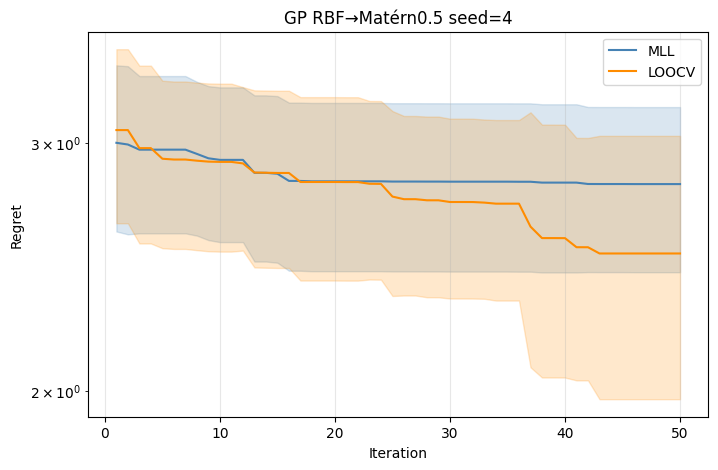

MLL vs LOOCV:
  Median MLL: 1.4769
  Median LOOCV: 1.5071
  p-value: 0.4609
  p-corrected: 0.4609
  Signifikant: Nein


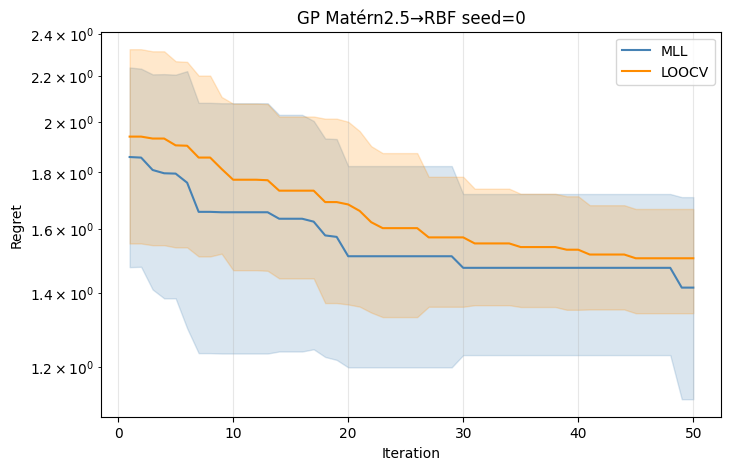

MLL vs LOOCV:
  Median MLL: 2.1080
  Median LOOCV: 1.8934
  p-value: 0.0059
  p-corrected: 0.0059
  Signifikant: Ja


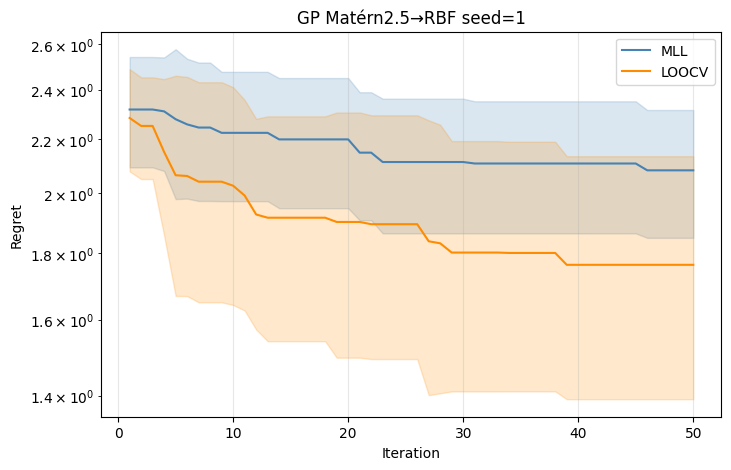

MLL vs LOOCV:
  Median MLL: 1.1599
  Median LOOCV: 1.1881
  p-value: 0.8203
  p-corrected: 0.8203
  Signifikant: Nein


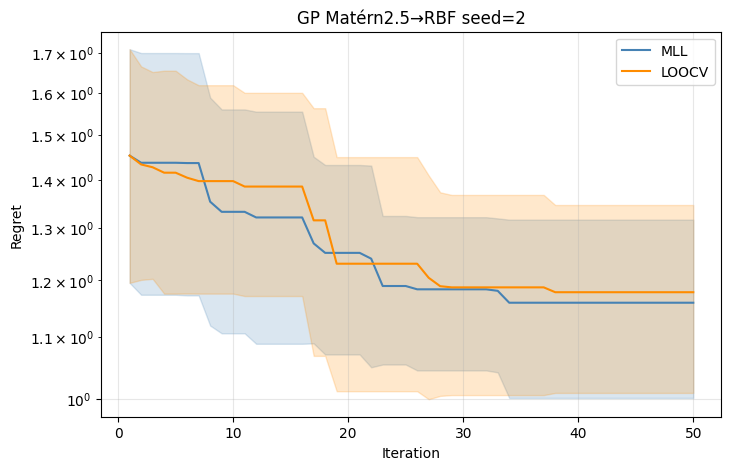

MLL vs LOOCV:
  Median MLL: 1.6932
  Median LOOCV: 1.4375
  p-value: 0.9102
  p-corrected: 0.9102
  Signifikant: Nein


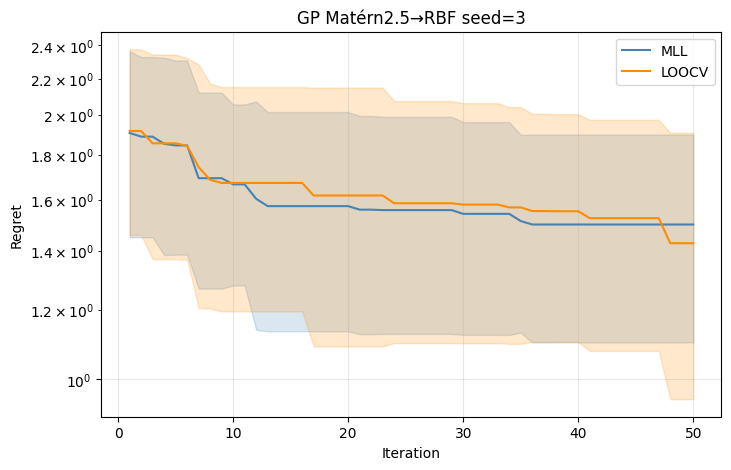

MLL vs LOOCV:
  Median MLL: 2.7113
  Median LOOCV: 2.8291
  p-value: 0.3008
  p-corrected: 0.3008
  Signifikant: Nein


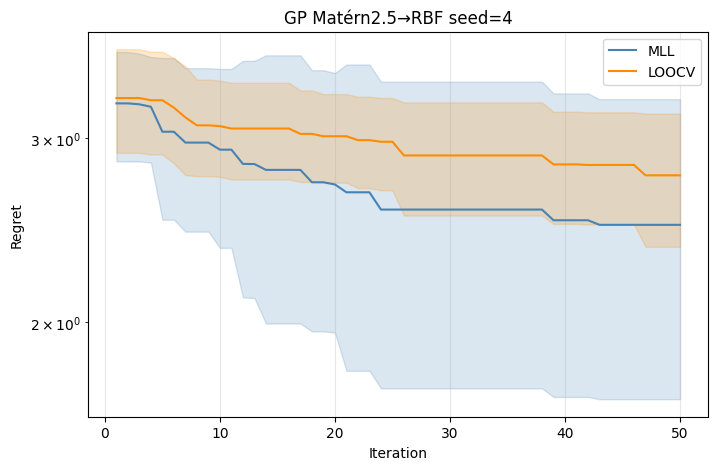

MLL vs LOOCV:
  Median MLL: 1.1547
  Median LOOCV: 1.0895
  p-value: 1.0000
  p-corrected: 1.0000
  Signifikant: Nein


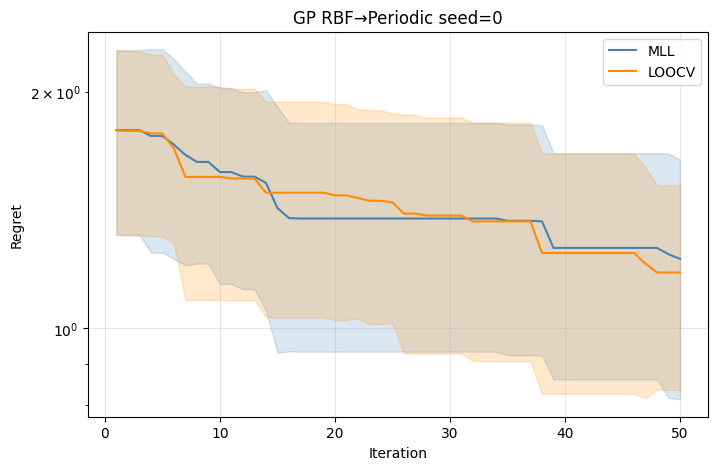

MLL vs LOOCV:
  Median MLL: 1.5230
  Median LOOCV: 1.6258
  p-value: 0.6250
  p-corrected: 0.6250
  Signifikant: Nein


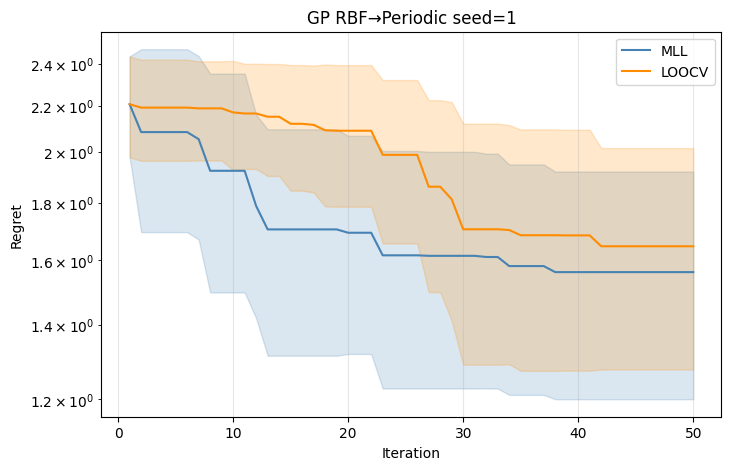

MLL vs LOOCV:
  Median MLL: 1.1427
  Median LOOCV: 1.2827
  p-value: 0.0391
  p-corrected: 0.0391
  Signifikant: Ja


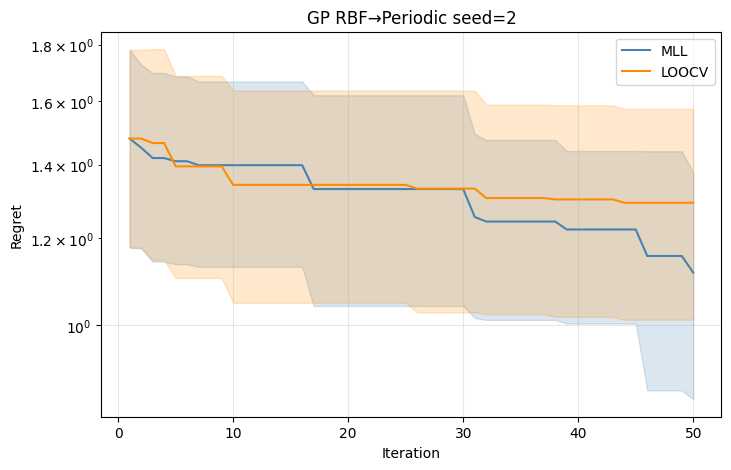

MLL vs LOOCV:
  Median MLL: 1.4112
  Median LOOCV: 1.5866
  p-value: 0.1094
  p-corrected: 0.1094
  Signifikant: Nein


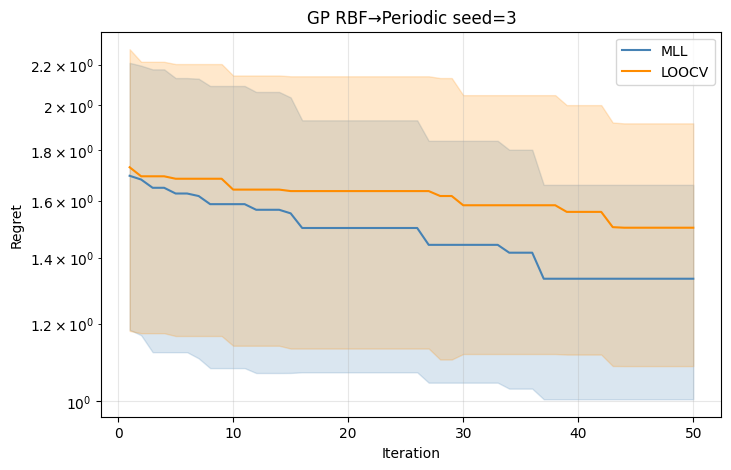

MLL vs LOOCV:
  Median MLL: 2.8720
  Median LOOCV: 2.8347
  p-value: 0.8438
  p-corrected: 0.8438
  Signifikant: Nein


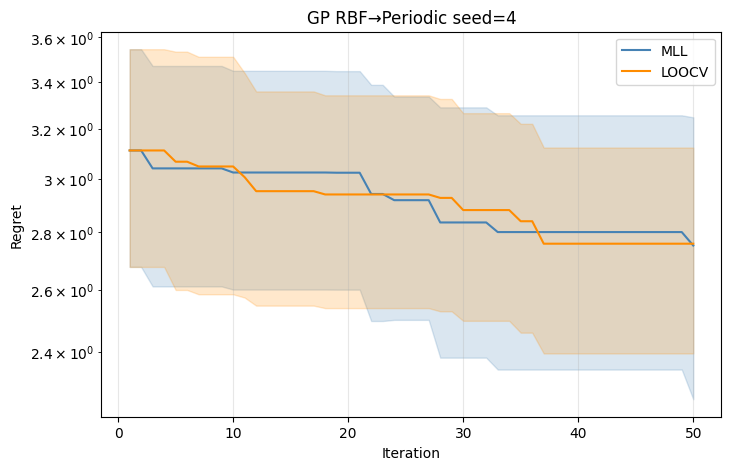

In [ ]:
#Experiment 3: GP-Sampled Misspecification:

#Boolean am ende um zu sagen ob MCMC hier genutzt werden kann oder nicht
gp_configs = [
    ("RBF→Matérn0.5",  lambda: RBFKernel(ard_num_dims= 5).double(),            lambda: MaternKernel(nu=0.5, ard_num_dims = 5), True),
    ("Matérn2.5→RBF",  lambda: MaternKernel(nu=2.5,ard_num_dims = 5).double(), lambda: RBFKernel(ard_num_dims= 5), True),
    ("RBF→Periodic",   lambda: RBFKernel(ard_num_dims= 5).double(),            lambda: PeriodicKernel(ard_num_dims= 5), False),
]
for config_name, true_kernel, misspec_kernel, include_mcmc in gp_configs:
    for seed in range(5):
        kernel = true_kernel()
        kernel.lengthscale = 0.3

        f = make_gp_function(d=5, true_kernel = kernel, seed=seed)

        bo_loops = [
            ("MLL",   bo_loop_mll),
            ("LOOCV", bo_loop_loocv),
        ]
        if include_mcmc:
            bo_loops = [
            ("MLL",   bo_loop_mll),
            ("LOOCV", bo_loop_loocv),
            ("MCMC", bo_loop_mcmc),
            ]

        results = bo_experiment_parallel(
            f=f, n_runs=10, num_loop=50,
            kernel=misspec_kernel(),
            bo_loops= bo_loops
        )
        
        title = f"GP {config_name} seed={seed}"
        plot_regret_with_std(results["regrets"], title=title)
        save_experiment(results, title = title, save_path= f"experiments/experiment_3/{name}")
        experiments.append((f"{config_name} s{seed}", results))


## Auswertung

In [42]:
with open("backups/experiments_backup.pkl", "wb") as f:
    pickle.dump(experiments,f)

In [43]:
#Auswertung
table = build_summary_table(experiments)
print(table.to_string(index=False))

             Experiment Method A   Median A Method B   Median B  p-value Signifikant?
                 Sphere      MLL     0.0108    LOOCV     0.0000   0.0059           Ja
                 Sphere      MLL     0.0108     MCMC     0.0071   0.5801         Nein
                 Sphere    LOOCV     0.0000     MCMC     0.0071   0.0059           Ja
             Rosenbrock      MLL   158.6685    LOOCV   183.0139   1.0000         Nein
             Rosenbrock      MLL   158.6685     MCMC    95.4039   0.5801         Nein
             Rosenbrock    LOOCV   183.0139     MCMC    95.4039   0.4805         Nein
              Ellipsoid      MLL 13653.6628    LOOCV  7423.6536   0.1934         Nein
              Ellipsoid      MLL 13653.6628     MCMC 11866.0958   1.0000         Nein
              Ellipsoid    LOOCV  7423.6536     MCMC 11866.0958   0.4805         Nein
              Rastrigin      MLL    44.2664    LOOCV    38.5163   0.8262         Nein
              Rastrigin      MLL    44.2664     MCMC  

## Extra Noiseless Tests 

Run No. 1
Run No. 5
Run No. 3
Run No. 6
Run No. 2
Run No. 7
Run No. 4
Run No. 0


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done
Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done
Run No. 8


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done
Run No. 9


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(


Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(


Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(
/Users/oemerkar/Documents/Universität/6.Semester/Bachelor

Done
Done
MLL vs LOOCV:
  Median MLL: 0.2800
  Median LOOCV: 0.4815
  p-value: 0.0195
  p-corrected: 0.0195
  Signifikant: Ja


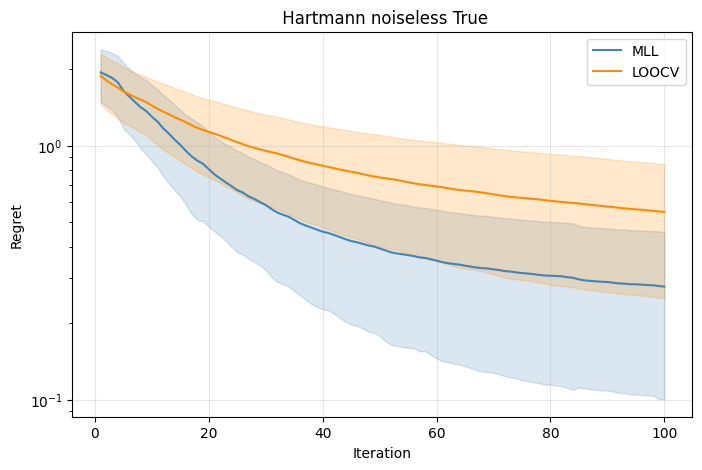

Run No. 0
Run No. 1
Run No. 2
Run No. 3
Run No. 4
Run No. 5
Run No. 6
Run No. 7


/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/botorch/fit.py:212: OptimizationWarning: `scipy_minimize` terminated with status OptimizationStatus.FAILURE, displaying original message from `scipy.optimize.minimize`: ABNORMAL: 
  result = optimizer(mll, closure=closure, **optimizer_kwargs)


Done
Done
Done
Done
Done
Done
Done
Done
Done
Run No. 8
Done
Run No. 9
Done
Done
Done
Done
Done
Done
Done
Done
Done
Done
MLL vs LOOCV:
  Median MLL: 0.2812
  Median LOOCV: 0.3462
  p-value: 0.0488
  p-corrected: 0.0488
  Signifikant: Ja


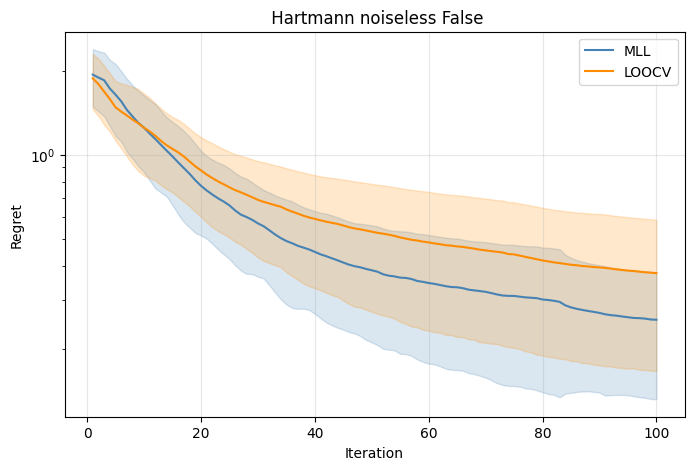

In [ ]:
# Experiment: Noise als Kompensation?
for noiseless in [True, False]:
    results = bo_experiment_parallel(
        f=Hartmann(), kernel=MaternKernel(nu=0.5),
        noiseless=noiseless,
        bo_loops=[
                ("MLL",   bo_loop_mll),
                ("LOOCV", bo_loop_loocv),
        ])
    title = f" Hartmann noiseless {noiseless}"
    plot_regret_with_std(results["regrets"], title=title)


Run No. 0
Done
Done
fit failures: 0
Run No. 1
Done
Done
fit failures: 0
Run No. 2
Done
Done
fit failures: 0
Run No. 3
Done
Done
fit failures: 1
Run No. 4
Done
Done
fit failures: 1
Run No. 5
Done
Done
fit failures: 1
Run No. 6
Done
Done
fit failures: 0
Run No. 7
Done
Done
fit failures: 0
Run No. 8
Done
Done
fit failures: 1
Run No. 9
Done
Done
fit failures: 0
MLL vs LOOCV:
  Median MLL: 0.4253
  Median LOOCV: 0.6993
  p-value: 0.3750
  p-corrected: 0.3750
  Signifikant: Nein


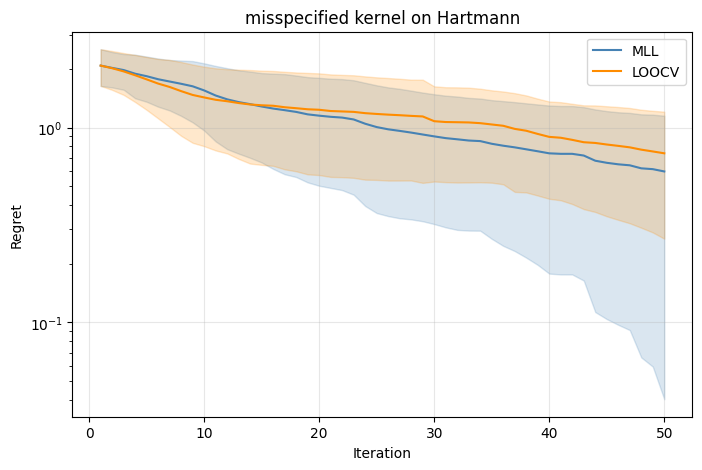

In [ ]:

#prior mit drin behalten
def make_misspecified_kernel(d, nu=0.5):
    lengthscale_prior = LogNormalPrior(
        loc=sqrt(2) + log(d) * 0.5,
        scale=sqrt(3)
    )
    
    return MaternKernel(
        nu=nu,
        ard_num_dims=d,
        lengthscale_prior=lengthscale_prior,
        lengthscale_constraint=GreaterThan(
            0.025,
            transform=None,
            initial_value=lengthscale_prior.mode,
        ),
    )

d = Hartmann().bounds.shape[-1]
results = bo_experiment(
    f=Hartmann(),
    kernel=make_misspecified_kernel(d, nu=0.5),
    bo_loops=[("MLL", bo_loop_mll), ("LOOCV", bo_loop_loocv)],
    n_runs=10, num_loop=50,
)
plot_regret_with_std(results["regrets"], title = "misspecified kernel on Hartmann")

# Analysis
Analysis Pipeline for the Data, for the Evaluations done in Chapter Experiments. 

Three Stages:
1. **BBOB Experiments**: BBOB results anomaly outlier checks, regret, lengthscale, noise curves per seed; Test for Seed Significance (Bootstrap Resampling) and Iteration Sensitivity
2. **CARPS Experiments**: CARPS results, ranked per autorank, seperate pairwise comparisons and cd diagram for the 5 seed aswell as the 10 seed version (with the 10 seed Version being the standard of this thesis)
3. **Experiment Analysis**: goes through each of the experiments and repeats the same analysis steps:
    - shows all significant results of each experiment sorted by p-value
    - plots the significant result distribution
    - computes win counts, (sig. and insig.) per method, sometimes compared to the win counts of the baseline experiments 
    - further analysis of some experiments

## Setup

In [7]:
import json, gzip, os
from pathlib import Path

from functions.analyze import compute_all_wins, compute_all_filtered

## BBOB Experiments

### Seeds

In [208]:
from functions.evaluations import argument_for_path, plot_all_seeds_with_median, load_all_seeds, plot_overview, plot_significant_cases

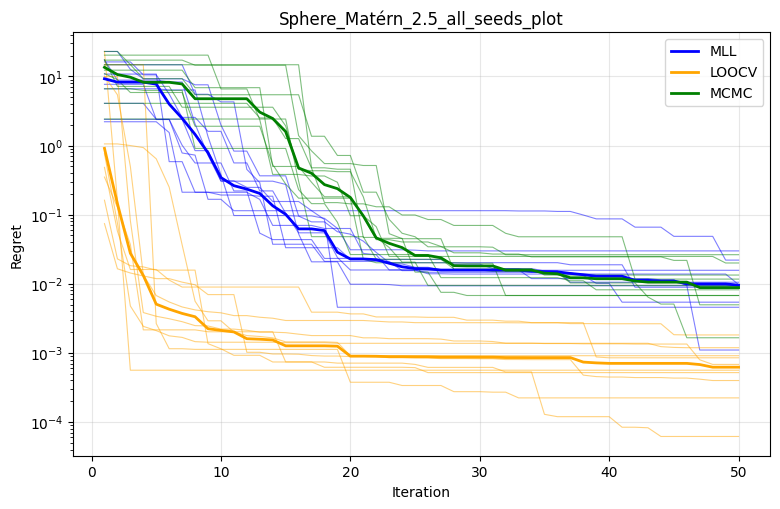

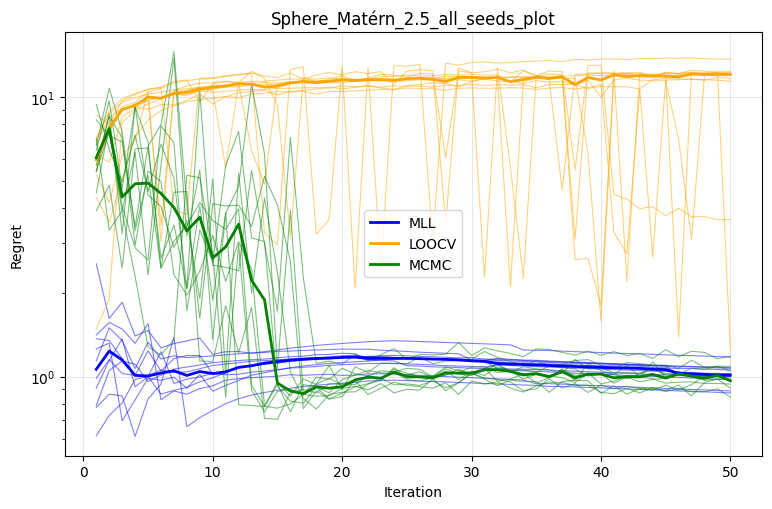

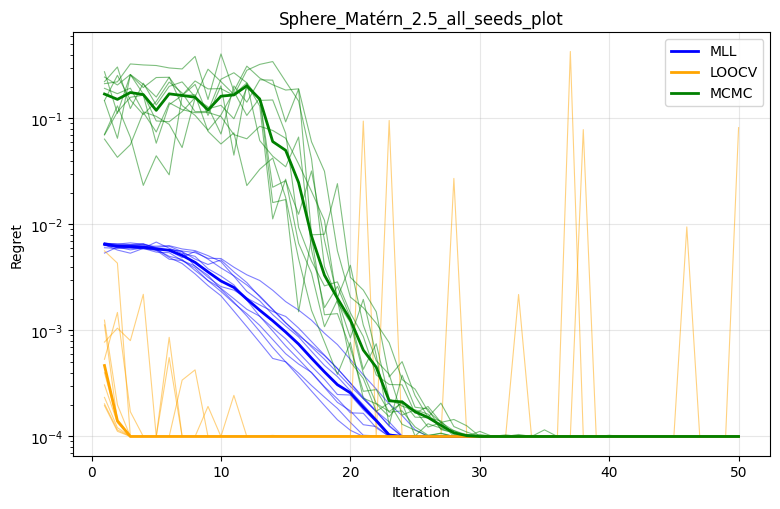

In [209]:
regrets = argument_for_path("functions/experiments/experiment_2_v3/Sphere_Matérn 2.5")
plot_all_seeds_with_median(regrets, title = "Sphere_Matérn_2.5_all_seeds_plot", save_path= "functions/experiments/experiment_2_v3/Sphere_Matérn 2.5")

lengthscales = argument_for_path("functions/experiments/experiment_2_v3/Sphere_Matérn 2.5", arg = "lengthscales")
plot_all_seeds_with_median(lengthscales, title = "Sphere_Matérn_2.5_all_seeds_plot", save_path= "functions/experiments/experiment_2_v3/Sphere_Matérn 2.5")

noises = argument_for_path("functions/experiments/experiment_2_v3/Sphere_Matérn 2.5", arg = "noises")
plot_all_seeds_with_median(noises, title = "Sphere_Matérn_2.5_all_seeds_plot", save_path= "functions/experiments/experiment_2_v3/Sphere_Matérn 2.5")

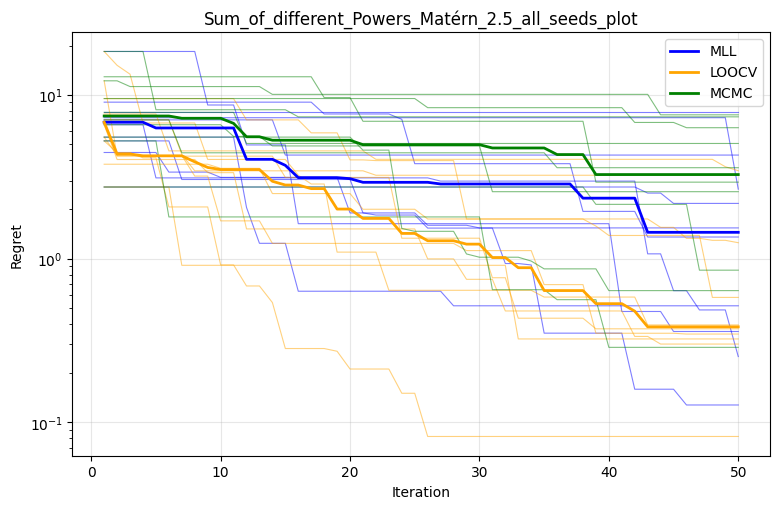

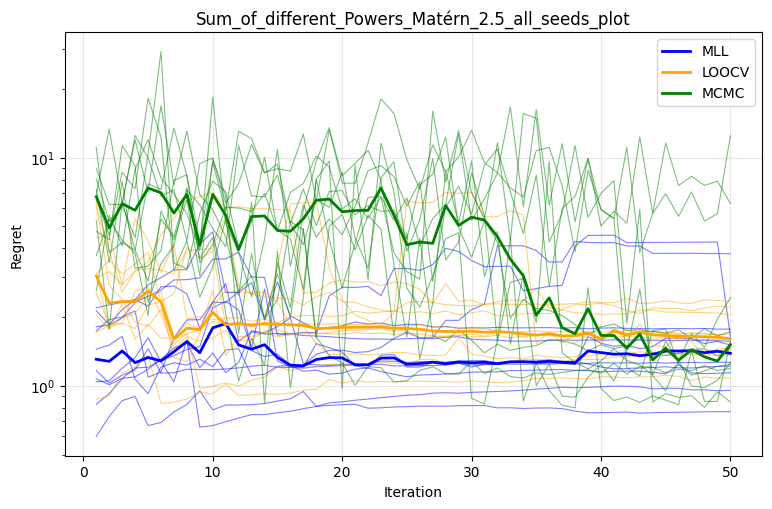

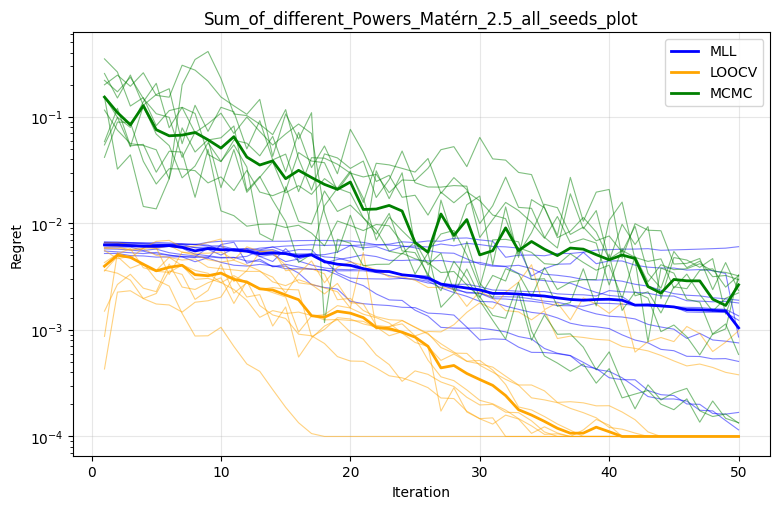

In [210]:
regrets = argument_for_path("functions/experiments/experiment_2_v3/Sum_of_different_Powers_Matérn 2.5")
plot_all_seeds_with_median(regrets, title = "Sum_of_different_Powers_Matérn_2.5_all_seeds_plot", save_path="functions/experiments/experiment_2_v3/Sum_of_different_Powers_Matérn 2.5")

lengthscales = argument_for_path("functions/experiments/experiment_2_v3/Sum_of_different_Powers_Matérn 2.5", arg ="lengthscales")
plot_all_seeds_with_median(lengthscales, title = "Sum_of_different_Powers_Matérn_2.5_all_seeds_plot", save_path="functions/experiments/experiment_2_v3/Sum_of_different_Powers_Matérn 2.5")

noises = argument_for_path("functions/experiments/experiment_2_v3/Sum_of_different_Powers_Matérn 2.5", arg ="noises")
plot_all_seeds_with_median(noises, title = "Sum_of_different_Powers_Matérn_2.5_all_seeds_plot", save_path="functions/experiments/experiment_2_v3/Sum_of_different_Powers_Matérn 2.5")

In [211]:
seeds = load_all_seeds(Path("functions/experiments/experiment_2_v2/Sharp_Ridge_Matérn 2.5"))
plot_overview(seeds = seeds, title = "Sphere Matern 2.5", save_path= "functions/experiments/experiment_2_v2/Sharp_Ridge_Matérn 2.5/plot_overview.pdf")

### Significant

In [ ]:
from functions.analyze import analyze_experiment, summarize_issues
from functions.evaluations import show_significant

for experiment in ("experiment_1", "experiment_2_v1","experiment_2_v2","experiment_2_v3","experiment_3","experiment_4"):
    summary = show_significant(f"functions/experiments/{experiment}/summary_table.csv")

    print(experiment)
    display(summary)

experiment_1


,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Schaffer_F7_Cond10,LOOCV,0.5587,0.3153,MCMC,0.9820,0.0876,1.50,55.40,0.0059,LOOCV
1,Skew Rastrigin-Bueche,LOOCV,1.8975,0.0906,MCMC,2.1251,0.1095,1.72,57.24,0.0059,LOOCV
2,Sphere,LOOCV,-3.2089,0.3933,MCMC,-2.0565,0.3190,5.56,43.52,0.0059,LOOCV
3,Sum_of_different_Powers,LOOCV,-0.4161,0.4740,MCMC,0.5118,0.4677,1.87,48.34,0.0059,LOOCV
4,Ellipsoid,MLL,4.0444,0.4127,LOOCV,3.5315,0.2795,1.00,1.94,0.0117,LOOCV
5,Skew Rastrigin-Bueche,MLL,2.0406,0.0991,LOOCV,1.8975,0.0906,1.00,1.72,0.0117,LOOCV
6,Sphere,MLL,-2.0205,0.3811,LOOCV,-3.2089,0.3933,1.00,5.56,0.0117,LOOCV
7,Rosenbrock,MLL,1.6717,0.4568,MCMC,2.3808,0.3977,1.00,46.09,0.0176,MLL
8,Schaffer_F7_Cond10,MLL,0.7943,0.3434,MCMC,0.9820,0.0876,1.00,55.40,0.0234,MLL
9,Ellipsoid,LOOCV,3.5315,0.2795,MCMC,3.9802,0.4525,1.94,50.09,0.0293,LOOCV


experiment_2_v1


,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Schaffer_F7_Cond1000_Matérn 2.5,MLL,0.8299,0.2657,MCMC,1.1038,0.2607,1.00,189.80,0.0059,MLL
1,Discus_Matérn 2.5,LOOCV,1.9001,0.4655,MCMC,2.2352,0.4870,1.40,186.06,0.0059,LOOCV
2,Rastrigin_Matérn 0.5,MLL,1.6377,0.2198,LOOCV,1.8609,0.1705,1.00,1.53,0.0059,MLL
3,Rosenbrock rotated_Matérn 0.5,MLL,2.7101,0.4115,LOOCV,2.0154,0.6074,1.00,1.55,0.0059,LOOCV
4,Schwefel_Matérn 0.5,LOOCV,0.5325,0.6606,MCMC,1.4364,0.8388,1.56,162.59,0.0059,LOOCV
5,Sum_of_different_Powers_Matérn 0.5,MLL,0.3634,0.2347,LOOCV,0.2398,0.2485,1.00,1.49,0.0117,LOOCV
6,Linear Slope_Matérn 0.5,MLL,-10.0000,2.9912,LOOCV,0.8243,3.2897,1.00,1.06,0.0117,MLL
7,Linear Slope_Matérn 0.5,LOOCV,0.8243,3.2897,MCMC,-10.0000,0.0000,1.06,152.64,0.0117,MCMC
8,Schwefel_Periodic,LOOCV,0.5600,0.6942,MCMC,0.3949,0.0962,1.23,113.89,0.0117,MCMC
9,Sphere_Periodic,LOOCV,-1.4354,0.4683,MCMC,-2.0021,0.2666,2.10,144.39,0.0176,MCMC


experiment_2_v2


,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Rastrigin_Separable_Matérn 0.5,MLL,1.7864,0.1224,MCMC,1.3572,0.2631,1.00,89.06,0.0059,MCMC
1,Rastrigin_Periodic,LOOCV,1.8183,0.2117,MCMC,1.5012,0.0710,1.40,78.72,0.0059,MCMC
2,Step_Ellipsoid_Periodic,LOOCV,1.5649,0.2081,MCMC,0.7204,0.4069,1.39,76.64,0.0059,MCMC
3,Rastrigin_Separable_Matérn 2.5,LOOCV,1.7204,0.1104,MCMC,1.5231,0.0865,1.82,130.61,0.0059,MCMC
4,Rastrigin_Separable_Periodic,MLL,1.8686,0.1161,MCMC,1.5231,0.0865,1.00,86.49,0.0059,MCMC
...,...,...,...,...,...,...,...,...,...,...,...
67,Ellipsoid_Separable_Periodic,MLL,5.1435,0.5934,LOOCV,4.4991,0.5023,1.00,1.58,0.0293,LOOCV
68,Schaffer_F7_Cond10_Periodic,LOOCV,0.7014,0.2098,MCMC,0.8335,0.1185,1.37,71.51,0.0293,LOOCV
69,Gallagher_101_Matérn 0.5,MLL,1.0581,0.3209,MCMC,0.6971,0.4231,1.00,184.71,0.0410,MCMC
70,Rosenbrock rotated_Periodic,MLL,2.9534,0.3708,MCMC,2.3730,0.3862,1.00,85.58,0.0410,MCMC


experiment_2_v3


,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Sum_of_different_Powers_Matérn 0.5,LOOCV,0.1326,0.2787,MCMC,0.5243,0.2765,1.56,59.20,0.0059,LOOCV
1,Griewank_Rosenbrock_Matérn 0.5,LOOCV,0.4960,0.2195,MCMC,0.6933,0.1128,1.55,53.93,0.0059,LOOCV
2,Step_Ellipsoid_Matérn 0.5,LOOCV,0.8327,0.2993,MCMC,1.3010,0.2205,1.60,54.69,0.0059,LOOCV
3,Sphere_Matérn 2.5,LOOCV,-3.2089,0.3933,MCMC,-2.0565,0.3190,5.56,43.07,0.0059,LOOCV
4,Schaffer_F7_Cond10_Matérn 2.5,LOOCV,0.5587,0.3153,MCMC,0.9820,0.0876,1.53,56.12,0.0059,LOOCV
5,Skew Rastrigin-Bueche_Matérn 2.5,LOOCV,1.8975,0.0906,MCMC,2.1251,0.1095,1.73,58.47,0.0059,LOOCV
6,Sum_of_different_Powers_Matérn 2.5,LOOCV,-0.4161,0.4740,MCMC,0.5118,0.4677,1.88,48.54,0.0059,LOOCV
7,Ellipsoid_Matérn 2.5,MLL,4.0444,0.4127,LOOCV,3.5315,0.2795,1.00,1.94,0.0117,LOOCV
8,Sphere_Matérn 2.5,MLL,-2.0205,0.3811,LOOCV,-3.2089,0.3933,1.00,5.56,0.0117,LOOCV
9,Skew Rastrigin-Bueche_Matérn 2.5,MLL,2.0406,0.0991,LOOCV,1.8975,0.0906,1.00,1.73,0.0117,LOOCV


experiment_3


,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Matérn2.5→RBF,MLL,0.0010,0.3295,MCMC,0.2205,2.2364,1.00,87.21,0.0008,MLL
1,Matérn0.5→Matérn2.5,MLL,0.0523,3.0201,MCMC,0.2884,0.1155,1.00,86.99,0.0014,MLL
2,Matérn0.5→Matérn2.5,LOOCV,0.1058,2.2128,MCMC,0.2884,0.1155,1.43,86.99,0.0030,LOOCV
3,Matérn2.5→Matérn0.5,LOOCV,0.1965,2.2260,MCMC,0.0501,2.1928,1.67,39.54,0.0051,MCMC
4,Matérn2.5→RBF,MLL,0.0010,0.3295,LOOCV,0.1418,2.2183,1.00,1.47,0.0167,MLL
5,RBF→Matérn2.5,LOOCV,-0.2303,2.1609,MCMC,0.0443,0.3323,1.49,65.62,0.0192,LOOCV
6,RBF→Matérn2.5,MLL,-0.1223,2.9650,MCMC,0.0443,0.3323,1.00,65.62,0.0219,MLL


experiment_4


,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,d20/Ellipsoid,LOOCV,5.9633,0.2095,MCMC,6.3690,0.1175,3.18,13.71,0.0059,LOOCV
1,d20/Rosenbrock,LOOCV,3.7357,0.2380,MCMC,4.9879,0.1487,2.85,16.07,0.0059,LOOCV
2,d20/Rosenbrock,MLL,4.1471,0.2518,MCMC,4.9879,0.1487,1.00,16.07,0.0059,MLL
3,d20/Rastrigin,LOOCV,2.4944,0.0809,MCMC,2.8206,0.0940,2.90,15.71,0.0059,LOOCV
4,d20/Rastrigin,MLL,2.5090,0.0716,MCMC,2.8206,0.0940,1.00,15.71,0.0059,MLL
5,d20/Gallagher,MLL,1.5099,0.1208,MCMC,1.8698,0.0930,1.00,13.16,0.0059,MLL
6,d20/Sphere,MLL,1.0659,0.3075,MCMC,1.9494,0.1197,1.00,20.68,0.0059,MLL
7,d20/Ellipsoid,MLL,5.9348,0.1408,MCMC,6.3690,0.1175,1.00,13.71,0.0059,MLL
8,d20/Sphere,LOOCV,-1.1281,0.9111,MCMC,1.9494,0.1197,2.94,20.68,0.0059,LOOCV
9,d10/Sphere,MLL,-1.0967,0.1951,LOOCV,-2.4055,0.3170,1.00,6.47,0.0059,LOOCV


### Outlier Analysis

In [47]:
from functions.analyze import analyze_experiment, summarize_issues
import pandas as pd

for experiment in ("experiment_1", "experiment_2_v1","experiment_2_v2","experiment_2_v3","experiment_3","experiment_4"):
    df = analyze_experiment(f"functions/experiments/{experiment}")

    summary = summarize_issues(df)

    print(experiment)
    with pd.option_context('display.max_rows', None, 'display.max_columns', None):
        display(summary[summary["any_issue"]])


experiment_1


,folder,method,stagnant_regret,no_improvement,regret_increases,has_nan_inf,lengthscale_extreme,noise_extreme,lengthscale_no_variation,fit_time_outlier,cross_seed_outlier,n_seeds,any_issue,median_convergence_iter,pct_near_optimal
3,Bent_Cigar,LOOCV,2,2,0,0,0,0,0,0,0,10,True,30.0,0.2
4,Bent_Cigar,MCMC,3,3,0,0,0,0,0,0,1,10,True,43.0,0.1
5,Bent_Cigar,MLL,3,3,0,0,0,0,0,0,1,10,True,38.0,0.1
7,Discus,MCMC,0,0,0,0,0,0,0,0,3,10,True,16.0,0.5
12,Ellipsoid_Separable,LOOCV,0,0,0,0,0,0,0,1,3,10,True,10.0,0.2
21,Katsuura,LOOCV,3,3,0,0,0,0,0,0,0,10,True,NaN,0.0
22,Katsuura,MCMC,4,4,0,0,0,0,0,0,0,10,True,NaN,0.0
23,Katsuura,MLL,2,2,0,0,0,0,0,0,0,10,True,NaN,0.0
24,Linear Slope,LOOCV,0,0,0,0,0,0,0,7,0,10,True,0.0,1.0
38,Rosenbrock,MLL,0,0,0,0,0,0,0,0,3,10,True,20.0,0.3


experiment_2_v1


,folder,method,stagnant_regret,no_improvement,regret_increases,has_nan_inf,lengthscale_extreme,noise_extreme,lengthscale_no_variation,fit_time_outlier,cross_seed_outlier,n_seeds,any_issue,median_convergence_iter,pct_near_optimal
2,Attractive_Sector_Matérn 0.5,MLL,2,2,0,0,0,0,0,0,0,10,True,4.5,0.2
5,Attractive_Sector_Matérn 2.5,MLL,2,2,0,0,0,0,0,0,0,10,True,1.0,0.3
6,Attractive_Sector_Periodic,LOOCV,0,0,0,0,0,0,0,5,0,10,True,2.0,0.5
8,Attractive_Sector_Periodic,MLL,1,1,0,0,0,0,0,1,0,10,True,17.0,0.5
12,Bent_Cigar_Matérn 2.5,LOOCV,1,1,0,0,0,0,0,0,1,10,True,23.0,0.2
15,Bent_Cigar_Periodic,LOOCV,0,0,0,0,0,0,0,3,0,10,True,25.5,0.2
17,Bent_Cigar_Periodic,MLL,1,1,0,0,0,0,0,2,1,10,True,33.0,0.1
20,Discus_Matérn 0.5,MLL,1,1,0,0,0,0,0,0,1,10,True,31.0,0.7
23,Discus_Matérn 2.5,MLL,0,0,0,0,0,0,0,0,4,10,True,19.0,0.4
24,Discus_Periodic,LOOCV,0,0,0,0,0,0,0,4,1,10,True,22.0,0.7


experiment_2_v2


,folder,method,stagnant_regret,no_improvement,regret_increases,has_nan_inf,lengthscale_extreme,noise_extreme,lengthscale_no_variation,fit_time_outlier,cross_seed_outlier,n_seeds,any_issue,median_convergence_iter,pct_near_optimal
0,Attractive_Sector_Matérn 0.5,LOOCV,1,1,0,0,9,0,0,0,2,10,True,6.0,0.1
2,Attractive_Sector_Matérn 0.5,MLL,1,1,0,0,7,0,0,0,2,10,True,6.0,0.5
3,Attractive_Sector_Matérn 2.5,LOOCV,1,1,0,0,9,0,0,0,0,10,True,13.0,0.2
5,Attractive_Sector_Matérn 2.5,MLL,2,2,0,0,4,0,0,1,0,10,True,5.0,0.3
6,Attractive_Sector_Periodic,LOOCV,1,1,0,0,4,0,0,4,2,10,True,8.5,0.2
8,Attractive_Sector_Periodic,MLL,1,1,0,0,5,0,0,5,2,10,True,28.0,0.3
9,Bent_Cigar_Matérn 0.5,LOOCV,1,1,0,0,10,0,0,1,0,10,True,NaN,0.0
11,Bent_Cigar_Matérn 0.5,MLL,1,1,0,0,8,0,0,1,0,10,True,NaN,0.0
12,Bent_Cigar_Matérn 2.5,LOOCV,2,2,0,0,6,0,0,0,0,10,True,20.0,0.1
13,Bent_Cigar_Matérn 2.5,MCMC,1,1,0,0,0,0,0,0,1,10,True,NaN,0.0


experiment_2_v3


,folder,method,stagnant_regret,no_improvement,regret_increases,has_nan_inf,lengthscale_extreme,noise_extreme,lengthscale_no_variation,fit_time_outlier,cross_seed_outlier,n_seeds,any_issue,median_convergence_iter,pct_near_optimal
2,Attractive_Sector_Matérn 0.5,MLL,1,1,0,0,0,0,0,1,0,10,True,2.0,0.2
7,Bent_Cigar_Matérn 0.5,MCMC,2,2,0,0,0,0,0,0,0,10,True,NaN,0.0
8,Bent_Cigar_Matérn 0.5,MLL,1,1,0,0,0,0,0,1,1,10,True,NaN,0.0
9,Bent_Cigar_Matérn 2.5,LOOCV,2,2,0,0,0,0,0,0,0,10,True,30.0,0.2
10,Bent_Cigar_Matérn 2.5,MCMC,3,3,0,0,0,0,0,0,1,10,True,43.0,0.1
11,Bent_Cigar_Matérn 2.5,MLL,3,3,0,0,0,0,0,0,1,10,True,38.0,0.1
12,Discus_Matérn 0.5,LOOCV,1,1,0,0,0,0,0,0,1,10,True,17.0,0.3
14,Discus_Matérn 0.5,MLL,0,0,0,0,0,0,0,2,4,10,True,24.5,0.4
16,Discus_Matérn 2.5,MCMC,0,0,0,0,0,0,0,0,3,10,True,16.0,0.5
20,Ellipsoid_Matérn 0.5,MLL,1,1,0,0,0,0,0,1,0,10,True,27.0,0.3


experiment_3


,folder,method,stagnant_regret,no_improvement,regret_increases,has_nan_inf,lengthscale_extreme,noise_extreme,lengthscale_no_variation,fit_time_outlier,cross_seed_outlier,n_seeds,any_issue,median_convergence_iter,pct_near_optimal
0,Matérn0.5→RBF,LOOCV,1,1,0,0,5,0,0,1,0,10,True,NaN,0.0
1,Matérn0.5→RBF,MCMC,2,2,0,0,0,0,0,0,0,10,True,NaN,0.0
2,Matérn0.5→RBF,MLL,3,3,0,0,3,0,0,1,0,10,True,NaN,0.0
3,Matérn2.5→Matérn0.5,LOOCV,3,3,0,0,10,0,0,4,0,10,True,NaN,0.0
5,Matérn2.5→Matérn0.5,MLL,2,2,0,0,7,0,0,4,0,10,True,NaN,0.0
6,Matérn2.5→RBF,LOOCV,4,4,0,0,3,0,0,2,0,10,True,NaN,0.0
7,Matérn2.5→RBF,MCMC,1,1,0,0,0,0,0,0,2,10,True,39.0,0.1
8,Matérn2.5→RBF,MLL,3,3,0,0,6,0,0,2,0,10,True,NaN,0.0
9,RBF→Matérn0.5,LOOCV,6,6,0,0,7,0,0,3,0,10,True,NaN,0.0
11,RBF→Matérn0.5,MLL,2,2,0,0,6,0,0,4,0,10,True,NaN,0.0


experiment_4


,folder,method,stagnant_regret,no_improvement,regret_increases,has_nan_inf,lengthscale_extreme,noise_extreme,lengthscale_no_variation,fit_time_outlier,cross_seed_outlier,n_seeds,any_issue,median_convergence_iter,pct_near_optimal
4,d10/Gallagher,MCMC,2,2,0,0,0,0,0,0,0,10,True,NaN,0.0
16,d20/Ellipsoid,MCMC,1,1,0,0,0,0,0,0,1,10,True,NaN,0.0


In [48]:
for experiment in ("experiment_2_v1","experiment_2_v2"):
    df = analyze_experiment(f"functions/experiments/{experiment}")

    summary = summarize_issues(df)

    print(experiment)
    display(summary[summary["any_issue"]])

experiment_2_v1


,folder,method,stagnant_regret,no_improvement,regret_increases,has_nan_inf,lengthscale_extreme,noise_extreme,lengthscale_no_variation,fit_time_outlier,cross_seed_outlier,n_seeds,any_issue,median_convergence_iter,pct_near_optimal
2,Attractive_Sector_Matérn 0.5,MLL,2,2,0,0,0,0,0,0,0,10,True,4.5,0.2
5,Attractive_Sector_Matérn 2.5,MLL,2,2,0,0,0,0,0,0,0,10,True,1.0,0.3
6,Attractive_Sector_Periodic,LOOCV,0,0,0,0,0,0,0,5,0,10,True,2.0,0.5
8,Attractive_Sector_Periodic,MLL,1,1,0,0,0,0,0,1,0,10,True,17.0,0.5
12,Bent_Cigar_Matérn 2.5,LOOCV,1,1,0,0,0,0,0,0,1,10,True,23.0,0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,Sum_of_different_Powers_Periodic,LOOCV,1,1,0,0,0,0,0,3,1,10,True,NaN,0.0
197,Sum_of_different_Powers_Periodic,MLL,1,1,0,0,0,0,0,3,0,10,True,NaN,0.0
202,Weierstrass_Matérn 2.5,MCMC,1,1,0,0,0,0,0,0,3,10,True,NaN,0.0
204,Weierstrass_Periodic,LOOCV,2,2,0,0,2,0,0,2,0,10,True,NaN,0.0


experiment_2_v2


,folder,method,stagnant_regret,no_improvement,regret_increases,has_nan_inf,lengthscale_extreme,noise_extreme,lengthscale_no_variation,fit_time_outlier,cross_seed_outlier,n_seeds,any_issue,median_convergence_iter,pct_near_optimal
0,Attractive_Sector_Matérn 0.5,LOOCV,1,1,0,0,9,0,0,0,2,10,True,6.0,0.1
2,Attractive_Sector_Matérn 0.5,MLL,1,1,0,0,7,0,0,0,2,10,True,6.0,0.5
3,Attractive_Sector_Matérn 2.5,LOOCV,1,1,0,0,9,0,0,0,0,10,True,13.0,0.2
5,Attractive_Sector_Matérn 2.5,MLL,2,2,0,0,4,0,0,1,0,10,True,5.0,0.3
6,Attractive_Sector_Periodic,LOOCV,1,1,0,0,4,0,0,4,2,10,True,8.5,0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,Weierstrass_Matérn 0.5,MLL,0,0,0,0,2,0,0,1,0,10,True,NaN,0.0
201,Weierstrass_Matérn 2.5,LOOCV,2,2,0,0,9,0,0,1,0,10,True,NaN,0.0
203,Weierstrass_Matérn 2.5,MLL,1,1,0,0,4,0,1,2,2,10,True,NaN,0.0
204,Weierstrass_Periodic,LOOCV,1,1,0,0,8,0,1,4,0,10,True,NaN,0.0


In [49]:
# for the lengthscale degeneration point in Experiment 2
from functions.analyze import summarize_lengthscale_extreme

for experiment in ("experiment_2_v1", "experiment_2_v2", "experiment_2_v3"):
    print(experiment)
    df = analyze_experiment(f"functions/experiments/{experiment}")
    summary = summarize_issues(df)
    summary = summarize_lengthscale_extreme(summary)
    display(summary)

experiment_2_v1


{'MLL/LOOCV median seeds affected': np.float64(0.0),
 'MLL/LOOCV mean seeds affected': np.float64(0.057971014492753624),
 'MLL/LOOCV % of rows with ≥6/10 affected': np.float64(0.0),
 'MCMC median seeds affected': np.float64(0.0),
 'MCMC mean seeds affected': np.float64(0.0),
 'MCMC % of rows with 0/10 affected': np.float64(100.0)}

experiment_2_v2


{'MLL/LOOCV median seeds affected': np.float64(7.0),
 'MLL/LOOCV mean seeds affected': np.float64(6.630434782608695),
 'MLL/LOOCV % of rows with ≥6/10 affected': np.float64(76.81159420289855),
 'MCMC median seeds affected': np.float64(0.0),
 'MCMC mean seeds affected': np.float64(0.11594202898550725),
 'MCMC % of rows with 0/10 affected': np.float64(98.55072463768117)}

experiment_2_v3


{'MLL/LOOCV median seeds affected': np.float64(0.0),
 'MLL/LOOCV mean seeds affected': np.float64(0.07608695652173914),
 'MLL/LOOCV % of rows with ≥6/10 affected': np.float64(0.0),
 'MCMC median seeds affected': np.float64(0.0),
 'MCMC mean seeds affected': np.float64(0.0),
 'MCMC % of rows with 0/10 affected': np.float64(100.0)}

### Test Seed Significance

In [50]:
from functions.analyze import test_significance

df = test_significance(Path("functions/experiments/experiment_2_v3/Sphere_Matérn 2.5"))

display(df)

,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere_Matérn 2.5,MLL,LOOCV,0.0046,0.0183,0.001
1,Sphere_Matérn 2.5,MLL,MCMC,-0.0034,0.0046,0.339
2,Sphere_Matérn 2.5,LOOCV,MCMC,-0.0149,-0.0057,1.000


In [51]:
df = test_significance(Path("functions/experiments/experiment_2_v3/Sum_of_different_Powers_Matérn 2.5"))

display(df)

,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sum_of_different_Powers_Matérn 2.5,MLL,LOOCV,-0.0243,2.0803,0.048
1,Sum_of_different_Powers_Matérn 2.5,MLL,MCMC,-5.3762,0.4677,0.950
2,Sum_of_different_Powers_Matérn 2.5,LOOCV,MCMC,-5.9290,-0.5046,1.000


In [ ]:
df = test_significance(Path("functions/experiments/experiment_init_sensitivity/Ellipsoid"))

display(df)

/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/oemerkar/Documents/Universität/6.Semester/Bachelorarbeit/Projekt/venv/venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Ellipsoid,MLL,LOOCV,NaN,NaN,0.0
1,Ellipsoid,MLL,MCMC,NaN,NaN,0.0
2,Ellipsoid,LOOCV,MCMC,NaN,NaN,0.0


### Test Iteration Sensitivity

In [53]:
from functions.analyze import test_sensitivity_over_iterations
test_sensitivity_over_iterations(results_path="functions/experiments/experiment_2_v3/Sphere_Matérn 2.5")

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,0.343262,0.002113,0.001953,True
1,MLL vs. LOOCV,20,0.022833,0.000897,0.001953,True
2,MLL vs. LOOCV,30,0.015773,0.000866,0.001953,True
3,MLL vs. LOOCV,40,0.012844,0.000705,0.001953,True
4,MLL vs. LOOCV,50,0.009542,0.000621,0.003906,True
5,MLL vs. MCMC,10,0.343262,4.748770,0.001953,True
6,MLL vs. MCMC,20,0.022833,0.177090,0.005859,True
7,MLL vs. MCMC,30,0.015773,0.018109,0.695312,False
8,MLL vs. MCMC,40,0.012844,0.011819,0.769531,False
9,MLL vs. MCMC,50,0.009542,0.008802,1.000000,False


In [54]:
df = test_sensitivity_over_iterations("functions/experiments/experiment_2_v3/Sum_of_different_Powers_Matérn 2.5")

display(df)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,6.289550,3.503952,0.048828,True
1,MLL vs. LOOCV,20,3.082039,2.010467,0.019531,True
2,MLL vs. LOOCV,30,2.860444,1.227813,0.009766,True
3,MLL vs. LOOCV,40,2.343842,0.531499,0.005859,True
4,MLL vs. LOOCV,50,1.449854,0.383749,0.013672,True
5,MLL vs. MCMC,10,6.289550,7.208875,0.375000,False
6,MLL vs. MCMC,20,3.082039,5.294010,0.097656,False
7,MLL vs. MCMC,30,2.860444,4.971548,0.054688,False
8,MLL vs. MCMC,40,2.343842,3.266197,0.556641,False
9,MLL vs. MCMC,50,1.449854,3.266197,0.193359,False


## CARPS Experiments

### 5 Seeds
Old Version, is kept for comparison with 10 Seed Version

In [14]:
import pandas as pd

df = pd.read_csv("functions/combined_logs.csv")
best_per_run = (
    df.groupby(["optimizer_id", "task_id", "seed"])["trial_value__cost"]
    .min()
    .reset_index()
    .rename(columns={"trial_value__cost": "best_cost"})
)


In [15]:
pivot_mean = best_per_run.pivot_table(
    index="task_id", columns="optimizer_id", values="best_cost", aggfunc="mean"
)
ranks = pivot_mean.rank(axis=1, method="average")

print("Durchschnittlicher bester Cost pro Task:")
display(pivot_mean)

print("Ränge pro Task (1 = am besten):")
display(ranks)

print("Durchschnittsrang über alle Tasks:")
display(ranks.mean(axis=0).sort_values())

Durchschnittlicher bester Cost pro Task:


optimizer_id,loocv,mcmc,mll
task_id,,,
bbob_f12_i0_d2,419.049471,498.672212,729.541380
bbob_f12_i1_d2,-350.960727,-235.503048,-328.035458
bbob_f20_i0_d2,184.214431,184.205641,184.701237
bbob_f6_i1_d4,80.761799,61.155975,86.642853
hpobench_lr_146818,0.173659,0.173463,0.174439
hpobench_rf_146212,0.000137,0.000035,0.000042
hpobench_xgboost_146212,0.000002,0.000000,0.000012
yahpo_lcbench_168335,-98.984392,-98.944707,-99.275275
yahpo_rbv2_aknn_1462,-0.999969,-0.999968,-0.999969


Ränge pro Task (1 = am besten):


optimizer_id,loocv,mcmc,mll
task_id,,,
bbob_f12_i0_d2,1.0,2.0,3.0
bbob_f12_i1_d2,1.0,3.0,2.0
bbob_f20_i0_d2,2.0,1.0,3.0
bbob_f6_i1_d4,2.0,1.0,3.0
hpobench_lr_146818,2.0,1.0,3.0
hpobench_rf_146212,3.0,1.0,2.0
hpobench_xgboost_146212,2.0,1.0,3.0
yahpo_lcbench_168335,2.0,3.0,1.0
yahpo_rbv2_aknn_1462,1.0,3.0,2.0


Durchschnittsrang über alle Tasks:


optimizer_id
mcmc     1.694444
loocv    1.888889
mll      2.416667
dtype: float64

       meanrank    median       mad ci_lower     ci_upper effect_size  \
mcmc   1.583333 -0.891834  0.128208     -1.0    58.498355         0.0   
loocv  2.138889 -0.891645  0.130484     -1.0  3341.861679   -0.000986   
mll    2.277778 -0.698392  0.301608     -1.0   212.773927   -0.563028   

        magnitude effect_size_above magnitude_above  
mcmc   negligible               0.0      negligible  
loocv  negligible         -0.000986      negligible  
mll        medium         -0.560942          medium  
Friedman: p = 0.0368
       meanrank effect_size_above magnitude_above
mcmc   1.583333               0.0      negligible
loocv  2.138889         -0.000986      negligible
mll    2.277778         -0.560942          medium


/var/folders/fb/1zjmvd791gx5pp626gsbffpm0000gn/T/ipykernel_53370/2016077352.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


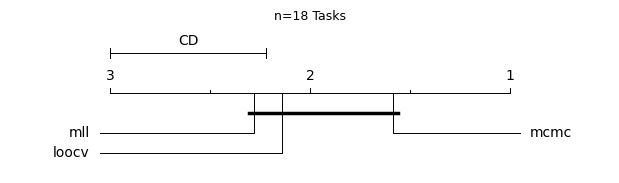

In [22]:
import pandas as pd
from autorank import autorank, plot_stats
import matplotlib.pyplot as plt

wide = pd.read_csv("functions/autorank_matrix.csv", index_col="task_id")

result = autorank(wide, alpha=0.05, verbose=False, order='ascending')
print(f"Friedman: p = {result.pvalue:.4f}")
print(result.rankdf[['meanrank', 'effect_size_above', 'magnitude_above']])

plot_stats(result, allow_insignificant=True)
plt.title(f"n={wide.shape[0]} Tasks", fontsize=9)
plt.tight_layout()
plt.savefig('functions/cd_diagram_carps_tasks.png', dpi=150, bbox_inches='tight')

In [12]:
from scipy.stats import wilcoxon
from itertools import combinations

def best_per_runs(df):
    """
    Reduced trials to one column per run to the best one trial per run
    """
    return(
        df.groupby(["task_id", "optimizer_id", "seed"])["trial_value__cost"].min().reset_index()
    )

def pairwise_comparison(df, methods = ("mll", "loocv", "mcmc")):
    """
    builds a table in the form of the summary_tables used in the rest of this thesis
    """
    runs = best_per_runs(df)
    rows = []

    for task in sorted(runs["task_id"].unique()):
        sub = runs[runs["task_id"] == task]
        for method_a, method_b in combinations(methods,2):
            a = sub[sub["optimizer_id"] == method_a].sort_values("seed")["trial_value__cost"].values
            b = sub[sub["optimizer_id"] == method_b].sort_values("seed")["trial_value__cost"].values

            if len(a) != len(b) or len(a) == 0:
                print(f"Missing Seeds, skipping {task}")
                continue
            try:
                stat, p = wilcoxon(a,b, mode ="exact")
            except ValueError:
                p = 1.0
                #if no diff
            
            med_a, med_b = np.median(a), np.median(b)
            if np.isclose(med_a, med_b, rtol=1e-4, atol=1e-8):
                winner = "tie"
            else:
                winner = method_a if med_a < med_b else method_b

            difference = med_a - med_b

            rows.append({
                "Experiment": task,
                "Method A": method_a, "Median A": med_a,
                "Method B": method_b, "Median B": med_b,
                "p-value": p,
                "difference": difference,
                "Winner": winner,
                "Signifikant?": "Ja" if p < 0.05 else "Nein",
            })
    return pd.DataFrame(rows)

In [296]:
df = pd.read_csv("functions/combined_logs.csv")
result = pairwise_comparison(df)
display(result)

# Pairwise comparisons of all methods and counts of the results printed
for method in ("mll", "loocv", "mcmc"):
    wins = len(result[result["Winner"] == method])
    print(f"Wins count of {method}: {wins}")


ties = result[result["Winner"] == "tie"]
mll_ties = ties[ties["Method A"] == "mll"]
against_loocv = len(mll_ties[mll_ties["Method B"] == "loocv"])
print(f"Ties between MLL and LOOCV: {against_loocv}")

against_mcmc = len(mll_ties[mll_ties["Method B"] == "mcmc"])
print(f"Ties between MLL and MCMC: {against_mcmc}")

loocv_ties = len(ties[ties["Method A"] == "loocv"])

print(f"Ties between LOOCV and MMCC: {loocv_ties}")

,Experiment,Method A,Median A,Method B,Median B,p-value,difference,Winner,Signifikant?
0,bbob_f12_i0_d2,mll,314.369144,loocv,301.567586,1.0000,1.280156e+01,loocv,Nein
1,bbob_f12_i0_d2,mll,314.369144,mcmc,300.691502,0.6250,1.367764e+01,mcmc,Nein
2,bbob_f12_i0_d2,loocv,301.567586,mcmc,300.691502,1.0000,8.760835e-01,mcmc,Nein
3,bbob_f12_i1_d2,mll,-429.211226,loocv,-418.191605,1.0000,-1.101962e+01,mll,Nein
4,bbob_f12_i1_d2,mll,-429.211226,mcmc,-499.462224,1.0000,7.025100e+01,mcmc,Nein
5,bbob_f12_i1_d2,loocv,-418.191605,mcmc,-499.462224,0.6250,8.127062e+01,mcmc,Nein
6,bbob_f20_i0_d2,mll,184.647194,loocv,184.031296,0.1250,6.158983e-01,loocv,Nein
7,bbob_f20_i0_d2,mll,184.647194,mcmc,184.234219,0.1250,4.129753e-01,mcmc,Nein
8,bbob_f20_i0_d2,loocv,184.031296,mcmc,184.234219,0.6250,-2.029230e-01,loocv,Nein
9,bbob_f6_i1_d4,mll,80.922399,loocv,80.552311,0.6250,3.700877e-01,loocv,Nein


Wins count of mll: 7
Wins count of loocv: 11
Wins count of mcmc: 17
Ties between MLL and LOOCV: 4
Ties between MLL and MCMC: 8
Ties between LOOCV and MMCC: 7


In [ ]:
""""Computes median and mean difference between the methods"""
#when loocv is method a, method b is necessarly mcmc

loocv_mcmc = result[result["Method A"] == "loocv"]
median_diff_loocv_mcmc = np.median(loocv_mcmc["difference"])
mean_diff_loocv_mcmc = np.mean(loocv_mcmc["difference"])
print(f"Median difference between MCMC and LOOCV {median_diff_loocv_mcmc}, Mean Difference: {mean_diff_loocv_mcmc}")


mll = result[result["Method A"] == "mll"]
mll_loocv = mll[mll["Method B"] == "loocv"]
mll_mcmc = mll[mll["Method B"] == "mcmc"]

median_diff_mll_loocv = np.median(mll_loocv["difference"])
mean_diff_mll_loocv = np.mean(mll_loocv["difference"])
print(f"Median difference between MLL and LOOCV {median_diff_mll_loocv}, Mean Difference: {mean_diff_mll_loocv}")


median_diff_mll_mcmc = np.median(mll_mcmc["difference"])
mean_diff_mll_mcmc = np.mean(mll_mcmc["difference"])
print(f"Median difference between MCMC and MLL {median_diff_mll_mcmc}, Mean Difference: {mean_diff_mll_mcmc}")


Median difference between MCMC and LOOCV 1.2516975402832031e-06, Mean Difference: 5.869931183447093
Median difference between MLL and LOOCV 2.86102294921875e-06, Mean Difference: 0.14452896367177986
Median difference between MCMC and MLL 2.7709885173987648e-05, Mean Difference: 6.014460147118873


### Carps 10 Seeds
Does the same thing as above only for 10 Seeds (Standard in this Thesis)

In [28]:
import pandas as pd

df = pd.read_csv("functions/combined_logs_10.csv")
best_per_run = (
    df.groupby(["optimizer_id", "task_id", "seed"])["trial_value__cost"]
    .min()
    .reset_index()
    .rename(columns={"trial_value__cost": "best_cost"})
)

In [29]:
pivot_mean = best_per_run.pivot_table(
    index="task_id", columns="optimizer_id", values="best_cost", aggfunc="mean"
)
ranks = pivot_mean.rank(axis=1, method="average")

print("Durchschnittlicher bester Cost pro Task:")
display(pivot_mean)

print("Ränge pro Task (1 = am besten):")
display(ranks)

print("Durchschnittsrang über alle Tasks:")
display(ranks.mean(axis=0).sort_values())

Durchschnittlicher bester Cost pro Task:


optimizer_id,loocv,mcmc,mll
task_id,,,
bbob_f12_i0_d2,369.781524,4902.227823,1191.729727
bbob_f12_i1_d2,161.275251,-362.617682,-220.560222
bbob_f20_i0_d2,184.219974,184.133069,184.549164
bbob_f6_i1_d4,80.143309,67.861912,77.270380
hpobench_lr_146818,0.177073,0.173171,0.176488
hpobench_rf_146212,0.000096,0.000057,0.000085
hpobench_xgboost_146212,0.000005,0.000001,0.000006
yahpo_lcbench_168335,-98.651439,-99.073480,-98.769051
yahpo_rbv2_aknn_1462,-0.999968,-0.999973,-0.999966


Ränge pro Task (1 = am besten):


optimizer_id,loocv,mcmc,mll
task_id,,,
bbob_f12_i0_d2,1.0,3.0,2.0
bbob_f12_i1_d2,3.0,1.0,2.0
bbob_f20_i0_d2,2.0,1.0,3.0
bbob_f6_i1_d4,3.0,1.0,2.0
hpobench_lr_146818,3.0,1.0,2.0
hpobench_rf_146212,3.0,1.0,2.0
hpobench_xgboost_146212,2.0,1.0,3.0
yahpo_lcbench_168335,3.0,1.0,2.0
yahpo_rbv2_aknn_1462,2.0,1.0,3.0


Durchschnittsrang über alle Tasks:


optimizer_id
mcmc     1.388889
loocv    2.277778
mll      2.333333
dtype: float64

       meanrank    median       mad  ci_lower    ci_upper effect_size  \
mcmc   1.666667 -0.890867  0.128208      -1.0  120.398072         0.0   
loocv  2.055556 -0.879553  0.168173 -0.999998   396.01203   -0.051032   
mll    2.277778 -0.872703  0.174498      -1.0  331.245526   -0.080014   

        magnitude effect_size_above magnitude_above  
mcmc   negligible               0.0      negligible  
loocv  negligible         -0.051032      negligible  
mll    negligible         -0.026961      negligible  
Friedman: p = 0.1136
       meanrank effect_size_above magnitude_above
mcmc   1.666667               0.0      negligible
loocv  2.055556         -0.051032      negligible
mll    2.277778         -0.026961      negligible


/var/folders/fb/1zjmvd791gx5pp626gsbffpm0000gn/T/ipykernel_3646/2951245978.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


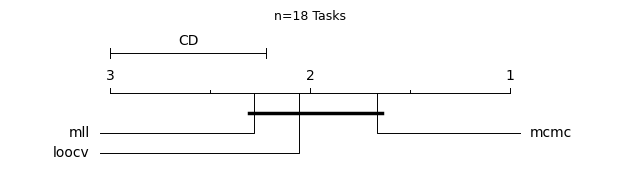

In [30]:
import pandas as pd
from autorank import autorank, plot_stats
import matplotlib.pyplot as plt

wide = pd.read_csv("functions/autorank_matrix_10.csv", index_col="task_id")

result = autorank(wide, alpha=0.05, verbose=False, order='ascending')
print(f"Friedman: p = {result.pvalue:.4f}")
print(result.rankdf[['meanrank', 'effect_size_above', 'magnitude_above']])

plot_stats(result, allow_insignificant=True)
plt.title(f"n={wide.shape[0]} Tasks", fontsize=9)
plt.tight_layout()
plt.savefig('functions/cd_diagram_carps_tasks_10.png', dpi=150, bbox_inches='tight')

In [31]:
df = pd.read_csv("functions/combined_logs_10.csv")
result = pairwise_comparison(df)
display(result)

# Pairwise comparisons of all methods and counts of the results printed
for method in ("mll", "loocv", "mcmc"):
    wins = len(result[result["Winner"] == method])
    print(f"Wins count of {method}: {wins}")


ties = result[result["Winner"] == "tie"]
mll_ties = ties[ties["Method A"] == "mll"]
against_loocv = len(mll_ties[mll_ties["Method B"] == "loocv"])
print(f"Ties between MLL and LOOCV: {against_loocv}")

against_mcmc = len(mll_ties[mll_ties["Method B"] == "mcmc"])
print(f"Ties between MLL and MCMC: {against_mcmc}")

loocv_ties = len(ties[ties["Method A"] == "loocv"])

print(f"Ties between LOOCV and MMCC: {loocv_ties}")

,Experiment,Method A,Median A,Method B,Median B,p-value,difference,Winner,Signifikant?
0,bbob_f12_i0_d2,mll,321.711893,loocv,313.698017,0.375000,8.013876e+00,loocv,Nein
1,bbob_f12_i0_d2,mll,321.711893,mcmc,387.986105,0.769531,-6.627421e+01,mll,Nein
2,bbob_f12_i0_d2,loocv,313.698017,mcmc,387.986105,0.193359,-7.428809e+01,loocv,Nein
3,bbob_f12_i1_d2,mll,-289.864474,loocv,-225.097970,0.492188,-6.476650e+01,mll,Nein
4,bbob_f12_i1_d2,mll,-289.864474,mcmc,-500.711928,0.322266,2.108475e+02,mcmc,Nein
5,bbob_f12_i1_d2,loocv,-225.097970,mcmc,-500.711928,0.375000,2.756140e+02,mcmc,Nein
6,bbob_f20_i0_d2,mll,184.418710,loocv,184.127047,0.130859,2.916638e-01,loocv,Nein
7,bbob_f20_i0_d2,mll,184.418710,mcmc,184.169837,0.027344,2.488737e-01,mcmc,Ja
8,bbob_f20_i0_d2,loocv,184.127047,mcmc,184.169837,0.695312,-4.279013e-02,loocv,Nein
9,bbob_f6_i1_d4,mll,80.434006,loocv,83.341663,0.845703,-2.907657e+00,mll,Nein


Wins count of mll: 7
Wins count of loocv: 10
Wins count of mcmc: 15
Ties between MLL and LOOCV: 9
Ties between MLL and MCMC: 6
Ties between LOOCV and MMCC: 7


In [32]:
#when loocv is method a, method b is necessarly mcmc
loocv_mcmc = result[result["Method A"] == "loocv"]
median_diff_loocv_mcmc = np.median(loocv_mcmc["difference"])
mean_diff_loocv_mcmc = np.mean(loocv_mcmc["difference"])
print(f"Median difference between MCMC and LOOCV {median_diff_loocv_mcmc}, Mean Difference: {mean_diff_loocv_mcmc}")


mll = result[result["Method A"] == "mll"]
mll_loocv = mll[mll["Method B"] == "loocv"]
mll_mcmc = mll[mll["Method B"] == "mcmc"]

median_diff_mll_loocv = np.median(mll_loocv["difference"])
mean_diff_mll_loocv = np.mean(mll_loocv["difference"])
print(f"Median difference between MLL and LOOCV {median_diff_mll_loocv}, Mean Difference: {mean_diff_mll_loocv}")


median_diff_mll_mcmc = np.median(mll_mcmc["difference"])
mean_diff_mll_mcmc = np.mean(mll_mcmc["difference"])
print(f"Median difference between MCMC and MLL {median_diff_mll_mcmc}, Mean Difference: {mean_diff_mll_mcmc}")


Median difference between MCMC and LOOCV 1.7732381821233822e-06, Mean Difference: 12.510552366226534
Median difference between MLL and LOOCV 9.5367431640625e-07, Mean Difference: -3.302157113139258
Median difference between MCMC and MLL 2.4586915969848633e-06, Mean Difference: 9.208395253087275


In [ ]:
df = pd.read_csv('functions/combined_logs_10.csv')

# Compute mean and standard deviation and Cross seed Variability across all seeds to see how stable each method is
df = df.sort_values(['run_dir', 'n_trials'])
df['cum_best'] = df.groupby('run_dir')['trial_value__cost'].cummin()
final = df.groupby(['optimizer_id', 'task_id', 'seed'])['cum_best'].last().reset_index()

# add mean and std
stats = final.groupby(['optimizer_id', 'task_id'])['cum_best'].agg(['mean', 'std']).reset_index()

# Cross seed variability evaluated by with std/|mean| so that the results are comparable (as some functions have way higher means than others)
stats['cv'] = stats['std'] / (stats['mean'].abs() + 1e-9)

# Print sorted
pd.set_option('display.width', 200)
print(stats.sort_values(['task_id', 'optimizer_id']).to_string())

   optimizer_id                   task_id         mean           std            cv
0         loocv            bbob_f12_i0_d2   369.781524  1.528256e+02  4.132862e-01
18         mcmc            bbob_f12_i0_d2  4902.227823  1.375610e+04  2.806092e+00
36          mll            bbob_f12_i0_d2  1191.729727  1.698849e+03  1.425532e+00
1         loocv            bbob_f12_i1_d2   161.275251  1.112941e+03  6.900881e+00
19         mcmc            bbob_f12_i1_d2  -362.617682  4.172959e+02  1.150787e+00
37          mll            bbob_f12_i1_d2  -220.560222  3.892560e+02  1.764851e+00
2         loocv            bbob_f20_i0_d2   184.219974  4.699298e-01  2.550916e-03
20         mcmc            bbob_f20_i0_d2   184.133069  1.987909e-01  1.079605e-03
38          mll            bbob_f20_i0_d2   184.549164  4.917148e-01  2.664411e-03
3         loocv             bbob_f6_i1_d4    80.143309  1.643224e+01  2.050356e-01
21         mcmc             bbob_f6_i1_d4    67.861912  1.642530e+01  2.420400e-01
39  

In [98]:
# Check the Cross Seed Variability between the methods and the task groups to confirm whether 
# BBOB functions are less stable than the other groups results, to indicate a possible structural benefit of the other 
# carps task groups regarding MCMC

# task_category for each function
cat_map = df.drop_duplicates('task_id').set_index('task_id')['task_category'].to_dict()
stats['task_category'] = stats['task_id'].map(cat_map)

# Aggregation pro Kategorie x Methode
pd.set_option('display.width', 200)

print("Mean CV per category per method:")
print(stats.groupby(['task_category', 'optimizer_id'])['cv'].mean().unstack().to_string())

print()
print("Median CV per category per method:")
print(stats.groupby(['task_category', 'optimizer_id'])['cv'].median().unstack().to_string())

print()
print("Amount of tasks per category")
print(stats.groupby('task_category')['task_id'].nunique())

Mean CV per category per method:
optimizer_id      loocv      mcmc       mll
task_category                              
bbob           1.880438  1.050000  0.868428
hpobench       1.114290  1.369057  1.202471
yahpo          0.041547  0.016439  0.050158

Median CV per category per method:
optimizer_id      loocv      mcmc       mll
task_category                              
bbob           0.309161  0.696414  0.853097
hpobench       1.548175  0.904772  1.626026
yahpo          0.002287  0.001356  0.002977

Amount of tasks per category
task_category
bbob         4
hpobench     3
yahpo       11
Name: task_id, dtype: int64


#### Is there a diff between Carps and get_bbob_wrapper?

In [ ]:
import ioh

p1 = ioh.get_problem(fid=12, instance=1, dimension=2, problem_class=ioh.ProblemClass.BBOB) #how get_bbob_wrapper uses it
p2 = ioh.get_problem(fid=12, instance=1, dimension=2)  # without problem_class, like CARPS uses it

print(p1.meta_data.name, p1.optimum.y)
print(p2.meta_data.name, p2.optimum.y)
print(p1([1.0, 1.0]), p2([1.0, 1.0]))  # the same for both

BentCigar -621.11
BentCigar -621.11
60030573.94802358 60030573.94802358


In [99]:
import ioh

problem = ioh.get_problem(fid=12, instance=1, dimension=2, problem_class=ioh.ProblemClass.BBOB)

# Test 1: one isolated call
val_isolated = problem([0.3, -0.7])

# Test 2: same, but after a few other calls, to ensure that the loop does not change the results
problem2 = ioh.get_problem(fid=12, instance=1, dimension=2, problem_class=ioh.ProblemClass.BBOB)
for _ in range(5):
    problem2([1.0, 1.0]) 
val_after_others = problem2([0.3, -0.7])

print(f"Isolated: {val_isolated}")
print(f"After others: {val_after_others}")
print(f"Same? {val_isolated == val_after_others}")

Isolated: 628355612.9875278
After others: 628355612.9875278
Same? True


also tested via debug script to ensure that there is not a problem based on the conversion in configspace

## Experiment Analysis

### Experiment 1

In [55]:
#New Version
summary = show_significant("functions/experiments/experiment_1/summary_table.csv")
display(summary)

,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Schaffer_F7_Cond10,LOOCV,0.5587,0.3153,MCMC,0.9820,0.0876,1.50,55.40,0.0059,LOOCV
1,Skew Rastrigin-Bueche,LOOCV,1.8975,0.0906,MCMC,2.1251,0.1095,1.72,57.24,0.0059,LOOCV
2,Sphere,LOOCV,-3.2089,0.3933,MCMC,-2.0565,0.3190,5.56,43.52,0.0059,LOOCV
3,Sum_of_different_Powers,LOOCV,-0.4161,0.4740,MCMC,0.5118,0.4677,1.87,48.34,0.0059,LOOCV
4,Ellipsoid,MLL,4.0444,0.4127,LOOCV,3.5315,0.2795,1.00,1.94,0.0117,LOOCV
5,Skew Rastrigin-Bueche,MLL,2.0406,0.0991,LOOCV,1.8975,0.0906,1.00,1.72,0.0117,LOOCV
6,Sphere,MLL,-2.0205,0.3811,LOOCV,-3.2089,0.3933,1.00,5.56,0.0117,LOOCV
7,Rosenbrock,MLL,1.6717,0.4568,MCMC,2.3808,0.3977,1.00,46.09,0.0176,MLL
8,Schaffer_F7_Cond10,MLL,0.7943,0.3434,MCMC,0.9820,0.0876,1.00,55.40,0.0234,MLL
9,Ellipsoid,LOOCV,3.5315,0.2795,MCMC,3.9802,0.4525,1.94,50.09,0.0293,LOOCV


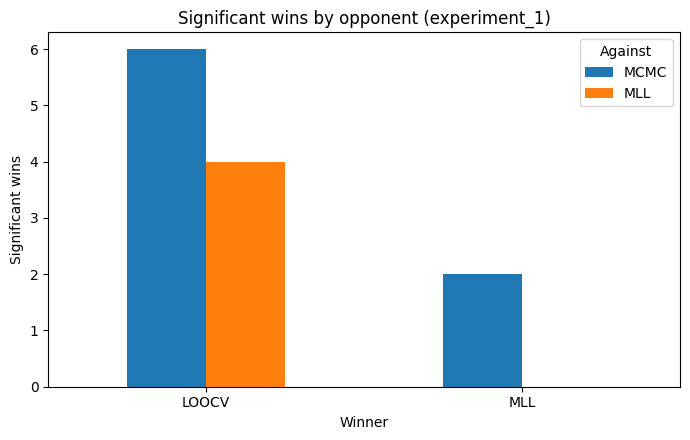

In [56]:
#New Version
from functions.evaluations import plot_significant_distribution
plot_significant_cases("functions/experiments/experiment_1")
plot_significant_distribution(exp_path= Path("functions/experiments/experiment_1"))

In [57]:
all_wins = compute_all_wins("functions/experiments/experiment_1/summary_table.csv")
display(all_wins)
df = summary[summary["Winner"] == "LOOCV"]

for experiment in df["Experiment"]:
    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_1/{experiment}")
    display(sig)
    sig = test_significance(Path(f"functions/experiments/experiment_1/{experiment}"))
    display(sig)

,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,33,10,23,46,0,19,14,30.3
MLL,25,2,23,46,9,16,0,8.0
MCMC,11,0,11,46,4,0,7,0.0


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,7.444280,7.249777,0.546875,False
1,MLL vs. LOOCV,20,7.226983,6.492301,0.300781,False
2,MLL vs. LOOCV,30,6.264943,5.877408,0.625000,False
3,MLL vs. LOOCV,40,6.264943,4.201083,0.431641,False
4,MLL vs. LOOCV,50,6.264943,3.659397,0.492188,False
5,MLL vs. MCMC,10,7.444280,10.282872,0.015625,True
6,MLL vs. MCMC,20,7.226983,10.282872,0.015625,True
7,MLL vs. MCMC,30,6.264943,9.836772,0.003906,True
8,MLL vs. MCMC,40,6.264943,9.596067,0.007812,True
9,MLL vs. MCMC,50,6.264943,9.596067,0.007812,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Schaffer_F7_Cond10,MLL,LOOCV,-2.1041,5.3721,0.209
1,Schaffer_F7_Cond10,MLL,MCMC,-7.1656,-0.9055,0.995
2,Schaffer_F7_Cond10,LOOCV,MCMC,-7.8791,-2.8654,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,139.583460,140.156597,0.382812,False
1,MLL vs. LOOCV,20,126.136068,104.797911,0.078125,False
2,MLL vs. LOOCV,30,109.898614,94.948079,0.027344,True
3,MLL vs. LOOCV,40,109.898614,81.837777,0.003906,True
4,MLL vs. LOOCV,50,109.898614,78.996703,0.003906,True
5,MLL vs. MCMC,10,139.583460,164.979696,0.109375,False
6,MLL vs. MCMC,20,126.136068,164.979696,0.078125,False
7,MLL vs. MCMC,30,109.898614,148.763132,0.054688,False
8,MLL vs. MCMC,40,109.898614,133.458410,0.203125,False
9,MLL vs. MCMC,50,109.898614,133.458410,0.164062,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Skew Rastrigin-Bueche,MLL,LOOCV,14.3098,61.6419,0.000
1,Skew Rastrigin-Bueche,MLL,MCMC,-72.2313,7.0672,0.866
2,Skew Rastrigin-Bueche,LOOCV,MCMC,-119.5485,-24.0143,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,0.343262,0.002113,0.001953,True
1,MLL vs. LOOCV,20,0.022833,0.000897,0.001953,True
2,MLL vs. LOOCV,30,0.015773,0.000866,0.001953,True
3,MLL vs. LOOCV,40,0.012844,0.000705,0.001953,True
4,MLL vs. LOOCV,50,0.009542,0.000621,0.003906,True
5,MLL vs. MCMC,10,0.343262,4.748770,0.001953,True
6,MLL vs. MCMC,20,0.022833,0.177090,0.005859,True
7,MLL vs. MCMC,30,0.015773,0.018109,0.695312,False
8,MLL vs. MCMC,40,0.012844,0.011819,0.769531,False
9,MLL vs. MCMC,50,0.009542,0.008802,1.000000,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere,MLL,LOOCV,0.0048,0.0151,0.000
1,Sphere,MLL,MCMC,-0.0034,0.0040,0.356
2,Sphere,LOOCV,MCMC,-0.0149,-0.0056,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,6.289550,3.503952,0.048828,True
1,MLL vs. LOOCV,20,3.082039,2.010467,0.019531,True
2,MLL vs. LOOCV,30,2.860444,1.227813,0.009766,True
3,MLL vs. LOOCV,40,2.343842,0.531499,0.005859,True
4,MLL vs. LOOCV,50,1.449854,0.383749,0.013672,True
5,MLL vs. MCMC,10,6.289550,7.208875,0.375000,False
6,MLL vs. MCMC,20,3.082039,5.294010,0.097656,False
7,MLL vs. MCMC,30,2.860444,4.971548,0.054688,False
8,MLL vs. MCMC,40,2.343842,3.266197,0.556641,False
9,MLL vs. MCMC,50,1.449854,3.266197,0.193359,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sum_of_different_Powers,MLL,LOOCV,-0.0180,1.9420,0.038
1,Sum_of_different_Powers,MLL,MCMC,-4.8520,0.4677,0.957
2,Sum_of_different_Powers,LOOCV,MCMC,-5.8333,-0.5161,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,90749.239428,101252.845707,0.640625,False
1,MLL vs. LOOCV,20,35434.708145,37887.673673,1.000000,False
2,MLL vs. LOOCV,30,24129.428587,15253.745022,0.130859,False
3,MLL vs. LOOCV,40,11150.912264,4967.116612,0.556641,False
4,MLL vs. LOOCV,50,11150.912264,3418.947049,0.003906,True
5,MLL vs. MCMC,10,90749.239428,329757.357949,0.195312,False
6,MLL vs. MCMC,20,35434.708145,60655.120402,0.300781,False
7,MLL vs. MCMC,30,24129.428587,43940.385901,0.300781,False
8,MLL vs. MCMC,40,11150.912264,18639.498420,0.375000,False
9,MLL vs. MCMC,50,11150.912264,9659.790239,1.000000,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Ellipsoid,MLL,LOOCV,988.5547,11783.4663,0.008
1,Ellipsoid,MLL,MCMC,-7720.9459,6888.4658,0.304
2,Ellipsoid,LOOCV,MCMC,-12976.3071,-1561.8950,0.997


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,139.583460,140.156597,0.382812,False
1,MLL vs. LOOCV,20,126.136068,104.797911,0.078125,False
2,MLL vs. LOOCV,30,109.898614,94.948079,0.027344,True
3,MLL vs. LOOCV,40,109.898614,81.837777,0.003906,True
4,MLL vs. LOOCV,50,109.898614,78.996703,0.003906,True
5,MLL vs. MCMC,10,139.583460,164.979696,0.109375,False
6,MLL vs. MCMC,20,126.136068,164.979696,0.078125,False
7,MLL vs. MCMC,30,109.898614,148.763132,0.054688,False
8,MLL vs. MCMC,40,109.898614,133.458410,0.203125,False
9,MLL vs. MCMC,50,109.898614,133.458410,0.164062,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Skew Rastrigin-Bueche,MLL,LOOCV,13.1239,63.0348,0.001
1,Skew Rastrigin-Bueche,MLL,MCMC,-72.2326,9.4884,0.872
2,Skew Rastrigin-Bueche,LOOCV,MCMC,-114.5579,-22.4816,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,0.343262,0.002113,0.001953,True
1,MLL vs. LOOCV,20,0.022833,0.000897,0.001953,True
2,MLL vs. LOOCV,30,0.015773,0.000866,0.001953,True
3,MLL vs. LOOCV,40,0.012844,0.000705,0.001953,True
4,MLL vs. LOOCV,50,0.009542,0.000621,0.003906,True
5,MLL vs. MCMC,10,0.343262,4.748770,0.001953,True
6,MLL vs. MCMC,20,0.022833,0.177090,0.005859,True
7,MLL vs. MCMC,30,0.015773,0.018109,0.695312,False
8,MLL vs. MCMC,40,0.012844,0.011819,0.769531,False
9,MLL vs. MCMC,50,0.009542,0.008802,1.000000,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere,MLL,LOOCV,0.0048,0.0153,0.000
1,Sphere,MLL,MCMC,-0.0036,0.0046,0.339
2,Sphere,LOOCV,MCMC,-0.0153,-0.0055,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,90749.239428,101252.845707,0.640625,False
1,MLL vs. LOOCV,20,35434.708145,37887.673673,1.000000,False
2,MLL vs. LOOCV,30,24129.428587,15253.745022,0.130859,False
3,MLL vs. LOOCV,40,11150.912264,4967.116612,0.556641,False
4,MLL vs. LOOCV,50,11150.912264,3418.947049,0.003906,True
5,MLL vs. MCMC,10,90749.239428,329757.357949,0.195312,False
6,MLL vs. MCMC,20,35434.708145,60655.120402,0.300781,False
7,MLL vs. MCMC,30,24129.428587,43940.385901,0.300781,False
8,MLL vs. MCMC,40,11150.912264,18639.498420,0.375000,False
9,MLL vs. MCMC,50,11150.912264,9659.790239,1.000000,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Ellipsoid,MLL,LOOCV,570.9473,11836.7995,0.010
1,Ellipsoid,MLL,MCMC,-12118.5278,6356.5439,0.351
2,Ellipsoid,LOOCV,MCMC,-19623.8553,-1126.1802,0.999


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,492.830176,522.380127,0.921875,False
1,MLL vs. LOOCV,20,447.203991,295.815022,0.193359,False
2,MLL vs. LOOCV,30,193.639137,158.744152,0.375000,False
3,MLL vs. LOOCV,40,60.519827,103.267732,0.845703,False
4,MLL vs. LOOCV,50,46.972541,73.277477,1.000000,False
5,MLL vs. MCMC,10,492.830176,2464.075995,0.074219,False
6,MLL vs. MCMC,20,447.203991,820.088495,0.375000,False
7,MLL vs. MCMC,30,193.639137,348.850960,0.232422,False
8,MLL vs. MCMC,40,60.519827,302.947631,0.001953,True
9,MLL vs. MCMC,50,46.972541,241.485794,0.005859,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Rosenbrock,MLL,LOOCV,-69.6420,140.1873,0.788
1,Rosenbrock,MLL,MCMC,-332.3109,-70.9540,0.992
2,Rosenbrock,LOOCV,MCMC,-344.5528,-82.6191,0.998


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,6.289550,3.503952,0.048828,True
1,MLL vs. LOOCV,20,3.082039,2.010467,0.019531,True
2,MLL vs. LOOCV,30,2.860444,1.227813,0.009766,True
3,MLL vs. LOOCV,40,2.343842,0.531499,0.005859,True
4,MLL vs. LOOCV,50,1.449854,0.383749,0.013672,True
5,MLL vs. MCMC,10,6.289550,7.208875,0.375000,False
6,MLL vs. MCMC,20,3.082039,5.294010,0.097656,False
7,MLL vs. MCMC,30,2.860444,4.971548,0.054688,False
8,MLL vs. MCMC,40,2.343842,3.266197,0.556641,False
9,MLL vs. MCMC,50,1.449854,3.266197,0.193359,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sum_of_different_Powers,MLL,LOOCV,-0.0066,1.9420,0.028
1,Sum_of_different_Powers,MLL,MCMC,-5.2481,0.4953,0.954
2,Sum_of_different_Powers,LOOCV,MCMC,-5.9185,-0.5046,1.000


In [58]:
df = summary[summary["Winner"] == "MLL"]

for experiment in df["Experiment"]:
    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_1/{experiment}")
    display(sig)
    sig = test_significance(Path(f"functions/experiments/experiment_1/{experiment}"))
    display(sig)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,492.830176,522.380127,0.921875,False
1,MLL vs. LOOCV,20,447.203991,295.815022,0.193359,False
2,MLL vs. LOOCV,30,193.639137,158.744152,0.375000,False
3,MLL vs. LOOCV,40,60.519827,103.267732,0.845703,False
4,MLL vs. LOOCV,50,46.972541,73.277477,1.000000,False
5,MLL vs. MCMC,10,492.830176,2464.075995,0.074219,False
6,MLL vs. MCMC,20,447.203991,820.088495,0.375000,False
7,MLL vs. MCMC,30,193.639137,348.850960,0.232422,False
8,MLL vs. MCMC,40,60.519827,302.947631,0.001953,True
9,MLL vs. MCMC,50,46.972541,241.485794,0.005859,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Rosenbrock,MLL,LOOCV,-67.7791,147.0598,0.781
1,Rosenbrock,MLL,MCMC,-365.3982,-67.0162,0.989
2,Rosenbrock,LOOCV,MCMC,-383.1523,-85.8413,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,7.444280,7.249777,0.546875,False
1,MLL vs. LOOCV,20,7.226983,6.492301,0.300781,False
2,MLL vs. LOOCV,30,6.264943,5.877408,0.625000,False
3,MLL vs. LOOCV,40,6.264943,4.201083,0.431641,False
4,MLL vs. LOOCV,50,6.264943,3.659397,0.492188,False
5,MLL vs. MCMC,10,7.444280,10.282872,0.015625,True
6,MLL vs. MCMC,20,7.226983,10.282872,0.015625,True
7,MLL vs. MCMC,30,6.264943,9.836772,0.003906,True
8,MLL vs. MCMC,40,6.264943,9.596067,0.007812,True
9,MLL vs. MCMC,50,6.264943,9.596067,0.007812,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Schaffer_F7_Cond10,MLL,LOOCV,-2.0785,5.5536,0.216
1,Schaffer_F7_Cond10,MLL,MCMC,-7.1656,-0.9055,0.997
2,Schaffer_F7_Cond10,LOOCV,MCMC,-8.0532,-2.8248,1.000


### Experiment 2:

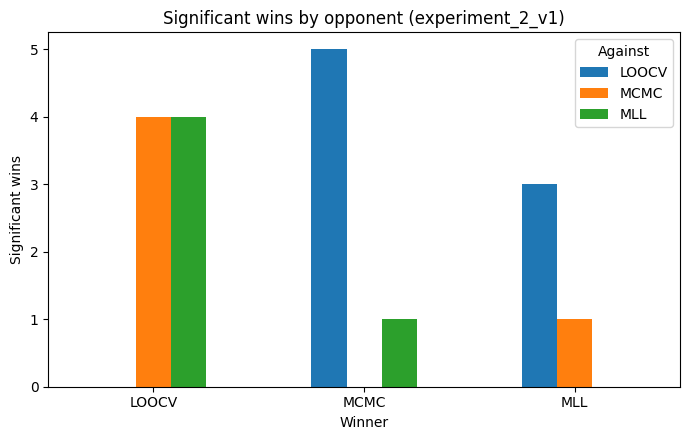

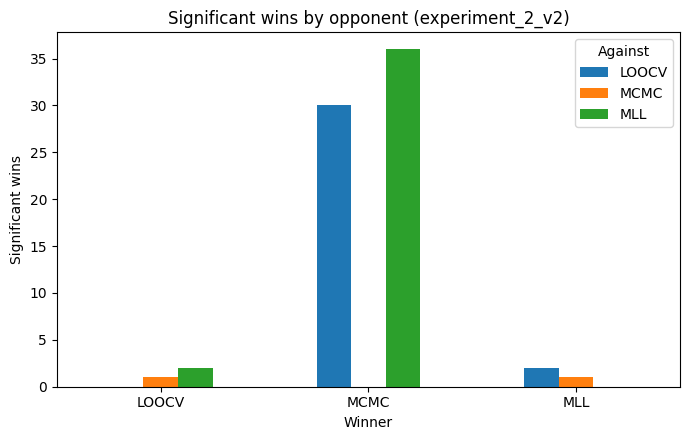

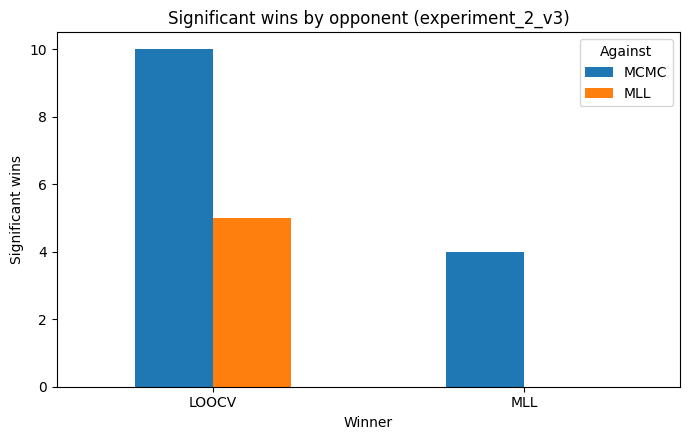

In [59]:
plot_significant_distribution(exp_path= Path("functions/experiments/experiment_2_v1"), save_path= Path("../../Schreiben/Option2/figures"), save_name="experiment_2v1_distr.png")
plot_significant_distribution(exp_path= Path("functions/experiments/experiment_2_v2"), save_path= Path("../../Schreiben/Option2/figures"), save_name="experiment_2v2_distr.png")
plot_significant_distribution(exp_path= Path("functions/experiments/experiment_2_v3"), save_path= Path("../../Schreiben/Option2/figures"), save_name="experiment_2v3_distr.png")

In [60]:
for experiment in ("experiment_2_v1", "experiment_2_v2", "experiment_2_v3"):
    print(experiment)
    df = show_significant(f"functions/experiments/{experiment}/summary_table.csv")
    plot_significant_cases(f"functions/experiments/{experiment}")
    display(df)

experiment_2_v1


,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Schaffer_F7_Cond1000_Matérn 2.5,MLL,0.8299,0.2657,MCMC,1.1038,0.2607,1.00,189.80,0.0059,MLL
1,Discus_Matérn 2.5,LOOCV,1.9001,0.4655,MCMC,2.2352,0.4870,1.40,186.06,0.0059,LOOCV
2,Rastrigin_Matérn 0.5,MLL,1.6377,0.2198,LOOCV,1.8609,0.1705,1.00,1.53,0.0059,MLL
3,Rosenbrock rotated_Matérn 0.5,MLL,2.7101,0.4115,LOOCV,2.0154,0.6074,1.00,1.55,0.0059,LOOCV
4,Schwefel_Matérn 0.5,LOOCV,0.5325,0.6606,MCMC,1.4364,0.8388,1.56,162.59,0.0059,LOOCV
5,Sum_of_different_Powers_Matérn 0.5,MLL,0.3634,0.2347,LOOCV,0.2398,0.2485,1.00,1.49,0.0117,LOOCV
6,Linear Slope_Matérn 0.5,MLL,-10.0000,2.9912,LOOCV,0.8243,3.2897,1.00,1.06,0.0117,MLL
7,Linear Slope_Matérn 0.5,LOOCV,0.8243,3.2897,MCMC,-10.0000,0.0000,1.06,152.64,0.0117,MCMC
8,Schwefel_Periodic,LOOCV,0.5600,0.6942,MCMC,0.3949,0.0962,1.23,113.89,0.0117,MCMC
9,Sphere_Periodic,LOOCV,-1.4354,0.4683,MCMC,-2.0021,0.2666,2.10,144.39,0.0176,MCMC


experiment_2_v2


,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Rastrigin_Separable_Matérn 0.5,MLL,1.7864,0.1224,MCMC,1.3572,0.2631,1.00,89.06,0.0059,MCMC
1,Rastrigin_Periodic,LOOCV,1.8183,0.2117,MCMC,1.5012,0.0710,1.40,78.72,0.0059,MCMC
2,Step_Ellipsoid_Periodic,LOOCV,1.5649,0.2081,MCMC,0.7204,0.4069,1.39,76.64,0.0059,MCMC
3,Rastrigin_Separable_Matérn 2.5,LOOCV,1.7204,0.1104,MCMC,1.5231,0.0865,1.82,130.61,0.0059,MCMC
4,Rastrigin_Separable_Periodic,MLL,1.8686,0.1161,MCMC,1.5231,0.0865,1.00,86.49,0.0059,MCMC
...,...,...,...,...,...,...,...,...,...,...,...
67,Ellipsoid_Separable_Periodic,MLL,5.1435,0.5934,LOOCV,4.4991,0.5023,1.00,1.58,0.0293,LOOCV
68,Schaffer_F7_Cond10_Periodic,LOOCV,0.7014,0.2098,MCMC,0.8335,0.1185,1.37,71.51,0.0293,LOOCV
69,Gallagher_101_Matérn 0.5,MLL,1.0581,0.3209,MCMC,0.6971,0.4231,1.00,184.71,0.0410,MCMC
70,Rosenbrock rotated_Periodic,MLL,2.9534,0.3708,MCMC,2.3730,0.3862,1.00,85.58,0.0410,MCMC


experiment_2_v3


,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Sum_of_different_Powers_Matérn 0.5,LOOCV,0.1326,0.2787,MCMC,0.5243,0.2765,1.56,59.20,0.0059,LOOCV
1,Griewank_Rosenbrock_Matérn 0.5,LOOCV,0.4960,0.2195,MCMC,0.6933,0.1128,1.55,53.93,0.0059,LOOCV
2,Step_Ellipsoid_Matérn 0.5,LOOCV,0.8327,0.2993,MCMC,1.3010,0.2205,1.60,54.69,0.0059,LOOCV
3,Sphere_Matérn 2.5,LOOCV,-3.2089,0.3933,MCMC,-2.0565,0.3190,5.56,43.07,0.0059,LOOCV
4,Schaffer_F7_Cond10_Matérn 2.5,LOOCV,0.5587,0.3153,MCMC,0.9820,0.0876,1.53,56.12,0.0059,LOOCV
5,Skew Rastrigin-Bueche_Matérn 2.5,LOOCV,1.8975,0.0906,MCMC,2.1251,0.1095,1.73,58.47,0.0059,LOOCV
6,Sum_of_different_Powers_Matérn 2.5,LOOCV,-0.4161,0.4740,MCMC,0.5118,0.4677,1.88,48.54,0.0059,LOOCV
7,Ellipsoid_Matérn 2.5,MLL,4.0444,0.4127,LOOCV,3.5315,0.2795,1.00,1.94,0.0117,LOOCV
8,Sphere_Matérn 2.5,MLL,-2.0205,0.3811,LOOCV,-3.2089,0.3933,1.00,5.56,0.0117,LOOCV
9,Skew Rastrigin-Bueche_Matérn 2.5,MLL,2.0406,0.0991,LOOCV,1.8975,0.0906,1.00,1.73,0.0117,LOOCV


In [61]:
plot_significant_cases("functions/experiments/experiment_2_v1")

#### Version 1

In [62]:
all_wins = compute_all_wins("functions/experiments/experiment_2_v1/summary_table.csv")
display(all_wins)

,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,71,8,63,138,0,37,34,11.3
MLL,70,4,66,138,35,35,0,5.7
MCMC,66,6,60,138,32,0,34,9.1


##### MLL Befund

In [63]:
#V1
for experiment in ("Linear Slope_Matérn 0.5", "Rastrigin_Matérn 0.5", "Bent_Cigar_Matérn 0.5", "Schaffer_F7_Cond1000_Matérn 2.5"):
    df = test_sensitivity_over_iterations(f"functions/experiments/experiment_2_v1/{experiment}")
    display(df)
    df = test_significance(Path(f"functions/experiments/experiment_2_v1/{experiment}"))
    display(df)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,9.274381,24.485216,0.001953,True
1,MLL vs. LOOCV,20,2.935670,19.400794,0.001953,True
2,MLL vs. LOOCV,30,0.000000,12.402136,0.001953,True
3,MLL vs. LOOCV,40,0.000000,8.108170,0.003906,True
4,MLL vs. LOOCV,50,0.000000,6.672751,0.003906,True
5,MLL vs. MCMC,10,9.274381,8.046072,0.322266,False
6,MLL vs. MCMC,20,2.935670,2.861339,0.625000,False
7,MLL vs. MCMC,30,0.000000,0.861527,0.812500,False
8,MLL vs. MCMC,40,0.000000,0.000000,0.500000,False
9,MLL vs. MCMC,50,0.000000,0.000000,1.000000,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Linear Slope_Matérn 0.5,MLL,LOOCV,-17.7339,-2.5287,1.0
1,Linear Slope_Matérn 0.5,MLL,MCMC,0.0000,0.0000,0.0
2,Linear Slope_Matérn 0.5,LOOCV,MCMC,2.5287,17.7339,0.0


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,76.881689,107.567960,0.083984,False
1,MLL vs. LOOCV,20,52.343853,100.077505,0.003906,True
2,MLL vs. LOOCV,30,48.478721,88.354742,0.001953,True
3,MLL vs. LOOCV,40,47.928679,84.469125,0.001953,True
4,MLL vs. LOOCV,50,44.123624,72.600292,0.001953,True
5,MLL vs. MCMC,10,76.881689,82.001265,0.556641,False
6,MLL vs. MCMC,20,52.343853,56.736536,0.769531,False
7,MLL vs. MCMC,30,48.478721,48.793463,0.695312,False
8,MLL vs. MCMC,40,47.928679,46.089127,0.625000,False
9,MLL vs. MCMC,50,44.123624,43.457072,0.556641,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Rastrigin_Matérn 0.5,MLL,LOOCV,-52.2536,-17.5278,1.000
1,Rastrigin_Matérn 0.5,MLL,MCMC,-17.6576,21.4063,0.566
2,Rastrigin_Matérn 0.5,LOOCV,MCMC,11.3070,66.3692,0.009


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,8.726909e+06,1.434112e+07,0.570312,False
1,MLL vs. LOOCV,20,5.076098e+06,1.122218e+07,0.013672,True
2,MLL vs. LOOCV,30,3.711427e+06,1.054160e+07,0.019531,True
3,MLL vs. LOOCV,40,2.200336e+06,8.633390e+06,0.003906,True
4,MLL vs. LOOCV,50,1.782473e+06,8.633390e+06,0.009766,True
5,MLL vs. MCMC,10,8.726909e+06,8.790117e+06,0.039062,True
6,MLL vs. MCMC,20,5.076098e+06,4.357646e+06,0.556641,False
7,MLL vs. MCMC,30,3.711427e+06,4.046166e+06,1.000000,False
8,MLL vs. MCMC,40,2.200336e+06,3.272757e+06,0.695312,False
9,MLL vs. MCMC,50,1.782473e+06,2.244624e+06,0.921875,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Bent_Cigar_Matérn 0.5,MLL,LOOCV,-1.051495e+07,-4.622547e+05,0.987
1,Bent_Cigar_Matérn 0.5,MLL,MCMC,-8.731519e+05,6.404469e+05,0.654
2,Bent_Cigar_Matérn 0.5,LOOCV,MCMC,5.275556e+05,1.115482e+07,0.017


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,29.937282,27.540174,0.570312,False
1,MLL vs. LOOCV,20,23.168757,16.488019,0.695312,False
2,MLL vs. LOOCV,30,13.614965,11.826731,0.556641,False
3,MLL vs. LOOCV,40,8.362979,9.437101,1.000000,False
4,MLL vs. LOOCV,50,6.780383,5.910842,0.556641,False
5,MLL vs. MCMC,10,29.937282,29.587349,1.000000,False
6,MLL vs. MCMC,20,23.168757,26.885461,0.027344,True
7,MLL vs. MCMC,30,13.614965,21.483352,0.037109,True
8,MLL vs. MCMC,40,8.362979,15.173337,0.232422,False
9,MLL vs. MCMC,50,6.780383,12.871406,0.001953,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Schaffer_F7_Cond1000_Matérn 2.5,MLL,LOOCV,-2.6440,7.4380,0.300
1,Schaffer_F7_Cond1000_Matérn 2.5,MLL,MCMC,-12.0255,-0.6178,1.000
2,Schaffer_F7_Cond1000_Matérn 2.5,LOOCV,MCMC,-12.2598,-0.6314,0.988


##### LOOCV Befund

In [64]:
# V1 : Wins against MLL
for experiment in ("Rosenbrock rotated_Matérn 0.5", "Sum_of_different_Powers_Matérn 0.5", "Schwefel_Matérn 0.5", "Step_Ellipsoid_Matérn 0.5"):
    df = test_sensitivity_over_iterations(f"functions/experiments/experiment_2_v1/{experiment}")
    display(df)
    df = test_significance(Path(f"functions/experiments/experiment_2_v1/{experiment}"))
    display(df)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,1269.143204,267.570488,0.001953,True
1,MLL vs. LOOCV,20,700.934748,153.241234,0.001953,True
2,MLL vs. LOOCV,30,537.252716,144.715964,0.001953,True
3,MLL vs. LOOCV,40,537.252716,115.053230,0.001953,True
4,MLL vs. LOOCV,50,519.851289,104.920595,0.001953,True
5,MLL vs. MCMC,10,1269.143204,1362.492053,0.845703,False
6,MLL vs. MCMC,20,700.934748,577.303567,0.160156,False
7,MLL vs. MCMC,30,537.252716,577.303567,0.625000,False
8,MLL vs. MCMC,40,537.252716,427.004178,0.921875,False
9,MLL vs. MCMC,50,519.851289,402.983765,0.769531,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Rosenbrock rotated_Matérn 0.5,MLL,LOOCV,145.7738,877.0845,0.000
1,Rosenbrock rotated_Matérn 0.5,MLL,MCMC,-165.7150,795.8110,0.269
2,Rosenbrock rotated_Matérn 0.5,LOOCV,MCMC,-818.8321,158.7884,0.936


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,3.983346,2.269512,0.009766,True
1,MLL vs. LOOCV,20,3.369465,1.941763,0.003906,True
2,MLL vs. LOOCV,30,2.606187,1.738897,0.001953,True
3,MLL vs. LOOCV,40,2.342175,1.738897,0.003906,True
4,MLL vs. LOOCV,50,2.334949,1.738897,0.003906,True
5,MLL vs. MCMC,10,3.983346,4.054369,0.820312,False
6,MLL vs. MCMC,20,3.369465,3.504836,0.492188,False
7,MLL vs. MCMC,30,2.606187,2.818541,0.556641,False
8,MLL vs. MCMC,40,2.342175,2.352820,0.845703,False
9,MLL vs. MCMC,50,2.334949,2.279196,0.845703,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sum_of_different_Powers_Matérn 0.5,MLL,LOOCV,0.1736,1.1590,0.006
1,Sum_of_different_Powers_Matérn 0.5,MLL,MCMC,-0.8528,0.6691,0.632
2,Sum_of_different_Powers_Matérn 0.5,LOOCV,MCMC,-1.4768,0.0171,0.963


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,1707.039141,159.712895,0.001953,True
1,MLL vs. LOOCV,20,379.687850,6.759421,0.001953,True
2,MLL vs. LOOCV,30,130.913762,3.437531,0.001953,True
3,MLL vs. LOOCV,40,43.855820,3.408654,0.003906,True
4,MLL vs. LOOCV,50,24.910249,3.408654,0.009766,True
5,MLL vs. MCMC,10,1707.039141,1625.679361,0.359375,False
6,MLL vs. MCMC,20,379.687850,528.825273,0.845703,False
7,MLL vs. MCMC,30,130.913762,125.240095,0.275391,False
8,MLL vs. MCMC,40,43.855820,106.101708,0.431641,False
9,MLL vs. MCMC,50,24.910249,27.881745,0.160156,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Schwefel_Matérn 0.5,MLL,LOOCV,1.3657,227.7308,0.006
1,Schwefel_Matérn 0.5,MLL,MCMC,-26.7458,82.1977,0.369
2,Schwefel_Matérn 0.5,LOOCV,MCMC,-167.7899,-1.0718,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,32.443418,16.294871,0.003906,True
1,MLL vs. LOOCV,20,25.518188,11.989372,0.001953,True
2,MLL vs. LOOCV,30,21.948083,10.058728,0.001953,True
3,MLL vs. LOOCV,40,18.860547,8.320370,0.003906,True
4,MLL vs. LOOCV,50,17.629659,7.927699,0.011719,True
5,MLL vs. MCMC,10,32.443418,33.461750,1.000000,False
6,MLL vs. MCMC,20,25.518188,20.903228,0.570312,False
7,MLL vs. MCMC,30,21.948083,20.903228,1.000000,False
8,MLL vs. MCMC,40,18.860547,18.478566,0.695312,False
9,MLL vs. MCMC,50,17.629659,17.135007,0.375000,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Step_Ellipsoid_Matérn 0.5,MLL,LOOCV,2.4652,13.9011,0.002
1,Step_Ellipsoid_Matérn 0.5,MLL,MCMC,-9.0769,6.7525,0.561
2,Step_Ellipsoid_Matérn 0.5,LOOCV,MCMC,-20.2484,0.3950,0.971


In [65]:
# V1 : Wins against MCMC
for experiment in ("Sum_of_different_Powers_Matérn 2.5", "Schwefel_Matérn 0.5", "Sum_of_different_Powers_Matérn 0.5", "Discus_Matérn 2.5"):
    df = test_sensitivity_over_iterations(f"functions/experiments/experiment_2_v1/{experiment}")
    display(df)
    df = test_significance(Path(f"functions/experiments/experiment_2_v1/{experiment}"))
    display(df)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,3.125964,2.963732,0.359375,False
1,MLL vs. LOOCV,20,2.555638,2.524880,0.130859,False
2,MLL vs. LOOCV,30,2.537198,1.509262,0.001953,True
3,MLL vs. LOOCV,40,2.398299,1.287276,0.001953,True
4,MLL vs. LOOCV,50,1.423421,0.983375,0.064453,False
5,MLL vs. MCMC,10,3.125964,4.436107,0.019531,True
6,MLL vs. MCMC,20,2.555638,3.585838,0.027344,True
7,MLL vs. MCMC,30,2.537198,3.072606,0.425781,False
8,MLL vs. MCMC,40,2.398299,2.385500,0.300781,False
9,MLL vs. MCMC,50,1.423421,1.767892,0.130859,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sum_of_different_Powers_Matérn 2.5,MLL,LOOCV,-0.3443,1.2823,0.195
1,Sum_of_different_Powers_Matérn 2.5,MLL,MCMC,-1.4099,0.5727,0.748
2,Sum_of_different_Powers_Matérn 2.5,LOOCV,MCMC,-1.9006,0.0336,0.964


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,1707.039141,159.712895,0.001953,True
1,MLL vs. LOOCV,20,379.687850,6.759421,0.001953,True
2,MLL vs. LOOCV,30,130.913762,3.437531,0.001953,True
3,MLL vs. LOOCV,40,43.855820,3.408654,0.003906,True
4,MLL vs. LOOCV,50,24.910249,3.408654,0.009766,True
5,MLL vs. MCMC,10,1707.039141,1625.679361,0.359375,False
6,MLL vs. MCMC,20,379.687850,528.825273,0.845703,False
7,MLL vs. MCMC,30,130.913762,125.240095,0.275391,False
8,MLL vs. MCMC,40,43.855820,106.101708,0.431641,False
9,MLL vs. MCMC,50,24.910249,27.881745,0.160156,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Schwefel_Matérn 0.5,MLL,LOOCV,1.4052,227.7308,0.006
1,Schwefel_Matérn 0.5,MLL,MCMC,-26.7458,82.1977,0.394
2,Schwefel_Matérn 0.5,LOOCV,MCMC,-167.7416,-1.1100,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,3.983346,2.269512,0.009766,True
1,MLL vs. LOOCV,20,3.369465,1.941763,0.003906,True
2,MLL vs. LOOCV,30,2.606187,1.738897,0.001953,True
3,MLL vs. LOOCV,40,2.342175,1.738897,0.003906,True
4,MLL vs. LOOCV,50,2.334949,1.738897,0.003906,True
5,MLL vs. MCMC,10,3.983346,4.054369,0.820312,False
6,MLL vs. MCMC,20,3.369465,3.504836,0.492188,False
7,MLL vs. MCMC,30,2.606187,2.818541,0.556641,False
8,MLL vs. MCMC,40,2.342175,2.352820,0.845703,False
9,MLL vs. MCMC,50,2.334949,2.279196,0.845703,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sum_of_different_Powers_Matérn 0.5,MLL,LOOCV,0.1736,1.1812,0.002
1,Sum_of_different_Powers_Matérn 0.5,MLL,MCMC,-0.8446,0.6691,0.623
2,Sum_of_different_Powers_Matérn 0.5,LOOCV,MCMC,-1.4768,0.1208,0.956


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,4827.685830,1437.562203,0.164062,False
1,MLL vs. LOOCV,20,2033.213553,116.964822,0.005859,True
2,MLL vs. LOOCV,30,1390.965265,116.964822,0.064453,False
3,MLL vs. LOOCV,40,462.389709,113.663707,0.105469,False
4,MLL vs. LOOCV,50,74.628629,83.994796,0.232422,False
5,MLL vs. MCMC,10,4827.685830,4998.784089,0.148438,False
6,MLL vs. MCMC,20,2033.213553,3802.036794,0.460938,False
7,MLL vs. MCMC,30,1390.965265,1469.381491,1.000000,False
8,MLL vs. MCMC,40,462.389709,509.676733,0.845703,False
9,MLL vs. MCMC,50,74.628629,172.235675,1.000000,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Discus_Matérn 2.5,MLL,LOOCV,-57.3782,620.7729,0.39
1,Discus_Matérn 2.5,MLL,MCMC,-337.5428,478.5328,0.68
2,Discus_Matérn 2.5,LOOCV,MCMC,-488.8941,-10.2310,1.00


#### Version 2:

In [66]:
#Show win count and whole sig table

df = show_significant(f"functions/experiments/experiment_2_v2/summary_table.csv")
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(df)
print(f"MCMC win count: {len(df[df["Winner"] == "MCMC"])}\nLOOCV win count: {len(df[df["Winner"] == "LOOCV"])}\nMLL win count: {len(df[df["Winner"] == "MLL"])}")

,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Rastrigin_Separable_Matérn 0.5,MLL,1.7864,0.1224,MCMC,1.3572,0.2631,1.00,89.06,0.0059,MCMC
1,Rastrigin_Periodic,LOOCV,1.8183,0.2117,MCMC,1.5012,0.0710,1.40,78.72,0.0059,MCMC
2,Step_Ellipsoid_Periodic,LOOCV,1.5649,0.2081,MCMC,0.7204,0.4069,1.39,76.64,0.0059,MCMC
3,Rastrigin_Separable_Matérn 2.5,LOOCV,1.7204,0.1104,MCMC,1.5231,0.0865,1.82,130.61,0.0059,MCMC
4,Rastrigin_Separable_Periodic,MLL,1.8686,0.1161,MCMC,1.5231,0.0865,1.00,86.49,0.0059,MCMC
5,Rastrigin_Separable_Periodic,LOOCV,1.7757,0.1026,MCMC,1.5231,0.0865,1.30,86.49,0.0059,MCMC
6,Rosenbrock rotated_Matérn 2.5,MLL,3.2835,0.3796,MCMC,2.3730,0.3862,1.00,133.97,0.0059,MCMC
7,Rosenbrock rotated_Periodic,LOOCV,3.0847,0.2321,MCMC,2.3730,0.3862,1.27,85.58,0.0059,MCMC
8,Rosenbrock_Matérn 0.5,LOOCV,2.7168,0.3189,MCMC,2.2705,0.3276,0.91,73.58,0.0059,MCMC
9,Rosenbrock_Matérn 2.5,MLL,2.9310,0.4088,MCMC,2.1716,0.4828,1.00,129.27,0.0059,MCMC


MCMC win count: 66
LOOCV win count: 3
MLL win count: 3


In [67]:
all_wins = compute_all_wins("functions/experiments/experiment_2_v2/summary_table.csv")
display(all_wins)

,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
MCMC,120,66,54,138,60,0,60,55.0
LOOCV,58,3,55,138,0,9,49,5.2
MLL,29,3,26,138,20,9,0,10.3


##### MCMC

In [68]:
#Shows 8 most and least distanced median values in sig. experiments for ones with the best p value und ones generally

df = show_significant(f"functions/experiments/experiment_2_v2/summary_table.csv")
df_p_val = df[df["p-value"] == 0.0059]

df["effect"] = (df["Log 10 Median A"] - df["Log 10 Median B"]).abs()
df_p_val["effect"] = (df_p_val["Log 10 Median A"] - df_p_val["Log 10 Median B"]).abs()

df_sorted = df.sort_values("effect", ascending=False)
df_p_val_sorted = df_p_val.sort_values("effect", ascending=False)

n = 8
top_and_bottom_all = pd.concat([df_sorted.head(n), df_sorted.tail(n)])
top_and_bottom_p_val= pd.concat([df_p_val_sorted.head(n), df_p_val_sorted.tail(n)])

print("highest dist. generally")
display(top_and_bottom_all)
print("highest dist. + lowest p")
display(top_and_bottom_p_val)

highest dist. generally


,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner,effect
63,Linear Slope_Periodic,MLL,1.4741,4.4878,MCMC,-10.0000,0.0000,1.00,82.66,0.0234,MCMC,11.4741
55,Linear Slope_Periodic,LOOCV,1.3755,3.4131,MCMC,-10.0000,0.0000,1.20,82.66,0.0117,MCMC,11.3755
71,Linear Slope_Matérn 0.5,MLL,0.1563,4.6767,MCMC,-10.0000,0.0000,1.00,74.51,0.0469,MCMC,10.1563
23,Sphere_Periodic,MLL,0.8257,0.2780,MCMC,-1.8005,0.4298,1.00,74.13,0.0059,MCMC,2.6262
15,Schwefel_Periodic,MLL,3.0506,0.8025,MCMC,0.4245,0.0952,1.00,70.65,0.0059,MCMC,2.6261
22,Sphere_Matérn 2.5,MLL,0.6591,0.2784,MCMC,-1.8005,0.4298,1.00,122.60,0.0059,MCMC,2.4596
24,Sphere_Periodic,LOOCV,0.6574,0.2828,MCMC,-1.8005,0.4298,1.27,74.13,0.0059,MCMC,2.4579
16,Schwefel_Periodic,LOOCV,2.8716,1.0101,MCMC,0.4245,0.0952,1.18,70.65,0.0059,MCMC,2.4471
31,Rastrigin_Matérn 0.5,MLL,1.7903,0.1385,MCMC,1.6085,0.1302,1.00,100.89,0.0059,MCMC,0.1818
33,Lunacek_biRastrigin_Periodic,MLL,1.7329,0.0691,MCMC,1.5728,0.1150,1.00,84.27,0.0059,MCMC,0.1601


highest dist. + lowest p


,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner,effect
23,Sphere_Periodic,MLL,0.8257,0.2780,MCMC,-1.8005,0.4298,1.00,74.13,0.0059,MCMC,2.6262
15,Schwefel_Periodic,MLL,3.0506,0.8025,MCMC,0.4245,0.0952,1.00,70.65,0.0059,MCMC,2.6261
22,Sphere_Matérn 2.5,MLL,0.6591,0.2784,MCMC,-1.8005,0.4298,1.00,122.60,0.0059,MCMC,2.4596
24,Sphere_Periodic,LOOCV,0.6574,0.2828,MCMC,-1.8005,0.4298,1.27,74.13,0.0059,MCMC,2.4579
16,Schwefel_Periodic,LOOCV,2.8716,1.0101,MCMC,0.4245,0.0952,1.18,70.65,0.0059,MCMC,2.4471
39,Ellipsoid_Separable_Periodic,MLL,5.1435,0.5934,MCMC,3.3659,0.0579,1.00,97.34,0.0059,MCMC,1.7776
13,Schwefel_Matérn 2.5,MLL,2.0673,1.0488,MCMC,0.4245,0.0952,1.00,104.94,0.0059,MCMC,1.6428
37,Ellipsoid_Separable_Matérn 2.5,MLL,4.9007,0.2650,MCMC,3.3659,0.0579,1.00,119.29,0.0059,MCMC,1.5348
5,Rastrigin_Separable_Periodic,LOOCV,1.7757,0.1026,MCMC,1.5231,0.0865,1.30,86.49,0.0059,MCMC,0.2526
29,Rastrigin_Matérn 2.5,LOOCV,1.7413,0.1884,MCMC,1.5012,0.0710,1.25,112.99,0.0059,MCMC,0.2401


In [69]:
#Top 5 most sig results with general highest diff
for experiment in ("Linear Slope_Periodic", "Linear Slope_Matérn 0.5", "Sphere_Periodic", "Sphere_Matérn 2.5"):
    df = test_sensitivity_over_iterations(f"functions/experiments/experiment_2_v2/{experiment}")
    display(df)
    df = test_significance(Path(f"functions/experiments/experiment_2_v2/{experiment}"))
    display(df)


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,44.687189,37.688667,0.556641,False
1,MLL vs. LOOCV,20,40.305675,35.614145,1.000000,False
2,MLL vs. LOOCV,30,29.793269,27.815928,0.910156,False
3,MLL vs. LOOCV,40,29.793269,25.353072,0.570312,False
4,MLL vs. LOOCV,50,29.793269,23.745118,1.000000,False
5,MLL vs. MCMC,10,44.687189,0.000000,0.001953,True
6,MLL vs. MCMC,20,40.305675,0.000000,0.001953,True
7,MLL vs. MCMC,30,29.793269,0.000000,0.007812,True
8,MLL vs. MCMC,40,29.793269,0.000000,0.007812,True
9,MLL vs. MCMC,50,29.793269,0.000000,0.007812,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Linear Slope_Periodic,MLL,LOOCV,-29.4472,17.1137,0.364
1,Linear Slope_Periodic,MLL,MCMC,0.0129,40.6606,0.000
2,Linear Slope_Periodic,LOOCV,MCMC,12.8712,35.2069,0.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,3.410120,0.119333,0.695312,False
1,MLL vs. LOOCV,20,2.391933,0.000000,0.128906,False
2,MLL vs. LOOCV,30,2.391933,0.000000,0.128906,False
3,MLL vs. LOOCV,40,1.650449,0.000000,0.425781,False
4,MLL vs. LOOCV,50,1.487337,0.000000,0.425781,False
5,MLL vs. MCMC,10,3.410120,0.000000,0.003906,True
6,MLL vs. MCMC,20,2.391933,0.000000,0.007812,True
7,MLL vs. MCMC,30,2.391933,0.000000,0.007812,True
8,MLL vs. MCMC,40,1.650449,0.000000,0.007812,True
9,MLL vs. MCMC,50,1.487337,0.000000,0.015625,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Linear Slope_Matérn 0.5,MLL,LOOCV,-1.6115,2.5211,0.032
1,Linear Slope_Matérn 0.5,MLL,MCMC,0.0000,2.5211,0.000
2,Linear Slope_Matérn 0.5,LOOCV,MCMC,0.0000,1.6436,0.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,9.926657,11.640108,0.375000,False
1,MLL vs. LOOCV,20,9.197362,6.480894,0.468750,False
2,MLL vs. LOOCV,30,9.197362,5.534775,0.359375,False
3,MLL vs. LOOCV,40,6.717085,4.571009,0.250000,False
4,MLL vs. LOOCV,50,6.717085,4.571009,0.128906,False
5,MLL vs. MCMC,10,9.926657,4.246373,0.078125,False
6,MLL vs. MCMC,20,9.197362,0.075608,0.001953,True
7,MLL vs. MCMC,30,9.197362,0.019904,0.001953,True
8,MLL vs. MCMC,40,6.717085,0.016816,0.001953,True
9,MLL vs. MCMC,50,6.717085,0.016633,0.001953,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere_Periodic,MLL,LOOCV,-1.3666,5.0162,0.126
1,Sphere_Periodic,MLL,MCMC,2.9635,11.2117,0.000
2,Sphere_Periodic,LOOCV,MCMC,2.4071,7.1473,0.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,12.755298,1.148520,0.011719,True
1,MLL vs. LOOCV,20,7.933960,1.148520,0.074219,False
2,MLL vs. LOOCV,30,7.933960,1.148520,0.074219,False
3,MLL vs. LOOCV,40,5.662027,1.148520,0.039062,True
4,MLL vs. LOOCV,50,4.567362,1.148520,0.039062,True
5,MLL vs. MCMC,10,12.755298,4.246373,0.023438,True
6,MLL vs. MCMC,20,7.933960,0.075608,0.001953,True
7,MLL vs. MCMC,30,7.933960,0.019904,0.001953,True
8,MLL vs. MCMC,40,5.662027,0.016816,0.001953,True
9,MLL vs. MCMC,50,4.567362,0.016633,0.001953,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere_Matérn 2.5,MLL,LOOCV,-1.7706,11.7515,0.052
1,Sphere_Matérn 2.5,MLL,MCMC,4.0310,13.0515,0.000
2,Sphere_Matérn 2.5,LOOCV,MCMC,-0.0186,7.7229,0.053


In [70]:
#Top 5 most sig results with highest diff within lowest p val
for experiment in ("Sphere_Periodic", "Sphere_Matérn 2.5", "Schwefel_Periodic"):
    df = test_sensitivity_over_iterations(f"functions/experiments/experiment_2_v2/{experiment}")
    display(df)
    df = test_significance(Path(f"functions/experiments/experiment_2_v2/{experiment}"))
    display(df)


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,9.926657,11.640108,0.375000,False
1,MLL vs. LOOCV,20,9.197362,6.480894,0.468750,False
2,MLL vs. LOOCV,30,9.197362,5.534775,0.359375,False
3,MLL vs. LOOCV,40,6.717085,4.571009,0.250000,False
4,MLL vs. LOOCV,50,6.717085,4.571009,0.128906,False
5,MLL vs. MCMC,10,9.926657,4.246373,0.078125,False
6,MLL vs. MCMC,20,9.197362,0.075608,0.001953,True
7,MLL vs. MCMC,30,9.197362,0.019904,0.001953,True
8,MLL vs. MCMC,40,6.717085,0.016816,0.001953,True
9,MLL vs. MCMC,50,6.717085,0.016633,0.001953,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere_Periodic,MLL,LOOCV,-1.3733,5.1167,0.116
1,Sphere_Periodic,MLL,MCMC,2.9635,11.2117,0.000
2,Sphere_Periodic,LOOCV,MCMC,2.3999,7.0414,0.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,12.755298,1.148520,0.011719,True
1,MLL vs. LOOCV,20,7.933960,1.148520,0.074219,False
2,MLL vs. LOOCV,30,7.933960,1.148520,0.074219,False
3,MLL vs. LOOCV,40,5.662027,1.148520,0.039062,True
4,MLL vs. LOOCV,50,4.567362,1.148520,0.039062,True
5,MLL vs. MCMC,10,12.755298,4.246373,0.023438,True
6,MLL vs. MCMC,20,7.933960,0.075608,0.001953,True
7,MLL vs. MCMC,30,7.933960,0.019904,0.001953,True
8,MLL vs. MCMC,40,5.662027,0.016816,0.001953,True
9,MLL vs. MCMC,50,4.567362,0.016633,0.001953,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere_Matérn 2.5,MLL,LOOCV,-1.6665,11.4891,0.042
1,Sphere_Matérn 2.5,MLL,MCMC,3.8914,12.2833,0.000
2,Sphere_Matérn 2.5,LOOCV,MCMC,-0.0215,7.7238,0.047


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,1797.043915,1685.451265,1.000000,False
1,MLL vs. LOOCV,20,1474.064351,1685.451265,0.425781,False
2,MLL vs. LOOCV,30,1474.064351,1000.961883,0.921875,False
3,MLL vs. LOOCV,40,1474.064351,788.321276,0.492188,False
4,MLL vs. LOOCV,50,1145.338621,745.171659,0.492188,False
5,MLL vs. MCMC,10,1797.043915,713.212708,0.019531,True
6,MLL vs. MCMC,20,1474.064351,3.829285,0.001953,True
7,MLL vs. MCMC,30,1474.064351,3.189679,0.001953,True
8,MLL vs. MCMC,40,1474.064351,3.018000,0.001953,True
9,MLL vs. MCMC,50,1145.338621,2.657592,0.001953,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Schwefel_Periodic,MLL,LOOCV,-394.7604,1670.6042,0.224
1,Schwefel_Periodic,MLL,MCMC,261.2322,2400.0879,0.000
2,Schwefel_Periodic,LOOCV,MCMC,73.6859,1213.5423,0.000


##### MLL

In [71]:
#MLL wins
for experiment in ("Attractive_Sector_Matérn 0.5", "Ellipsoid_Separable_Matérn 0.5", "Attractive_Sector_Matérn 0.5"):
    df = test_sensitivity_over_iterations(f"functions/experiments/experiment_2_v2/{experiment}")
    display(df)
    df = test_significance(Path(f"functions/experiments/experiment_2_v2/{experiment}"))
    display(df)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,116.748994,201.604735,0.496094,False
1,MLL vs. LOOCV,20,107.901384,201.373511,0.164062,False
2,MLL vs. LOOCV,30,87.392421,120.070303,0.054688,False
3,MLL vs. LOOCV,40,44.450644,119.536653,0.011719,True
4,MLL vs. LOOCV,50,40.501089,119.536653,0.003906,True
5,MLL vs. MCMC,10,116.748994,124.499067,0.820312,False
6,MLL vs. MCMC,20,107.901384,109.061267,0.820312,False
7,MLL vs. MCMC,30,87.392421,79.018448,1.000000,False
8,MLL vs. MCMC,40,44.450644,72.746795,0.359375,False
9,MLL vs. MCMC,50,40.501089,72.746795,0.039062,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Attractive_Sector_Matérn 0.5,MLL,LOOCV,-293.5764,-29.8070,1.000
1,Attractive_Sector_Matérn 0.5,MLL,MCMC,-75.2964,-4.0914,0.999
2,Attractive_Sector_Matérn 0.5,LOOCV,MCMC,-7.6803,264.8355,0.041


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,92412.448714,93162.457861,0.556641,False
1,MLL vs. LOOCV,20,42607.347549,93162.457861,0.019531,True
2,MLL vs. LOOCV,30,38431.476905,93162.457861,0.009766,True
3,MLL vs. LOOCV,40,20555.876521,75152.179260,0.027344,True
4,MLL vs. LOOCV,50,20555.876521,75152.179260,0.009766,True
5,MLL vs. MCMC,10,92412.448714,41750.382979,0.048828,True
6,MLL vs. MCMC,20,42607.347549,17218.406977,0.105469,False
7,MLL vs. MCMC,30,38431.476905,9343.904148,0.064453,False
8,MLL vs. MCMC,40,20555.876521,3632.490536,0.037109,True
9,MLL vs. MCMC,50,20555.876521,3632.490536,0.005859,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Ellipsoid_Separable_Matérn 0.5,MLL,LOOCV,-99336.6825,-293.1936,0.985
1,Ellipsoid_Separable_Matérn 0.5,MLL,MCMC,5753.8231,37905.5253,0.001
2,Ellipsoid_Separable_Matérn 0.5,LOOCV,MCMC,19313.9621,113834.7551,0.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,116.748994,201.604735,0.496094,False
1,MLL vs. LOOCV,20,107.901384,201.373511,0.164062,False
2,MLL vs. LOOCV,30,87.392421,120.070303,0.054688,False
3,MLL vs. LOOCV,40,44.450644,119.536653,0.011719,True
4,MLL vs. LOOCV,50,40.501089,119.536653,0.003906,True
5,MLL vs. MCMC,10,116.748994,124.499067,0.820312,False
6,MLL vs. MCMC,20,107.901384,109.061267,0.820312,False
7,MLL vs. MCMC,30,87.392421,79.018448,1.000000,False
8,MLL vs. MCMC,40,44.450644,72.746795,0.359375,False
9,MLL vs. MCMC,50,40.501089,72.746795,0.039062,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Attractive_Sector_Matérn 0.5,MLL,LOOCV,-306.0957,-29.8070,1.000
1,Attractive_Sector_Matérn 0.5,MLL,MCMC,-74.2243,-4.1394,0.998
2,Attractive_Sector_Matérn 0.5,LOOCV,MCMC,-17.4486,263.7497,0.053


##### LOOCV

In [72]:
#LOOCV wins
for experiment in ("Sharp_Ridge_Matérn 2.5","Ellipsoid_Separable_Periodic"):
    df = test_sensitivity_over_iterations(f"functions/experiments/experiment_2_v2/{experiment}")
    display(df)
    df = test_significance(Path(f"functions/experiments/experiment_2_v2/{experiment}"))
    display(df)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,443.525369,383.816996,0.820312,False
1,MLL vs. LOOCV,20,372.920889,368.933263,0.910156,False
2,MLL vs. LOOCV,30,362.555143,307.894311,0.300781,False
3,MLL vs. LOOCV,40,318.877927,268.101304,0.007812,True
4,MLL vs. LOOCV,50,318.783301,257.060914,0.003906,True
5,MLL vs. MCMC,10,443.525369,331.850399,0.845703,False
6,MLL vs. MCMC,20,372.920889,181.897925,0.001953,True
7,MLL vs. MCMC,30,362.555143,107.369290,0.001953,True
8,MLL vs. MCMC,40,318.877927,70.674985,0.001953,True
9,MLL vs. MCMC,50,318.783301,52.510569,0.001953,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sharp_Ridge_Matérn 2.5,MLL,LOOCV,12.7071,133.3584,0.0
1,Sharp_Ridge_Matérn 2.5,MLL,MCMC,217.0263,354.6314,0.0
2,Sharp_Ridge_Matérn 2.5,LOOCV,MCMC,121.8372,238.6039,0.0


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,240054.048744,143231.836669,0.820312,False
1,MLL vs. LOOCV,20,240054.048744,85648.026459,0.160156,False
2,MLL vs. LOOCV,30,195828.246134,41576.527669,0.027344,True
3,MLL vs. LOOCV,40,195828.246134,33580.137187,0.019531,True
4,MLL vs. LOOCV,50,141181.424557,33580.137187,0.009766,True
5,MLL vs. MCMC,10,240054.048744,10562.411062,0.013672,True
6,MLL vs. MCMC,20,240054.048744,3221.905464,0.001953,True
7,MLL vs. MCMC,30,195828.246134,2977.667880,0.001953,True
8,MLL vs. MCMC,40,195828.246134,2599.686534,0.001953,True
9,MLL vs. MCMC,50,141181.424557,2322.130607,0.001953,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Ellipsoid_Separable_Periodic,MLL,LOOCV,24693.5695,222471.1200,0.0
1,Ellipsoid_Separable_Periodic,MLL,MCMC,75621.9086,234362.0090,0.0
2,Ellipsoid_Separable_Periodic,LOOCV,MCMC,10514.2287,78722.2152,0.0


#### Version 3:

In [73]:
df = show_significant(f"functions/experiments/experiment_2_v3/summary_table.csv")
display(df)

,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Sum_of_different_Powers_Matérn 0.5,LOOCV,0.1326,0.2787,MCMC,0.5243,0.2765,1.56,59.20,0.0059,LOOCV
1,Griewank_Rosenbrock_Matérn 0.5,LOOCV,0.4960,0.2195,MCMC,0.6933,0.1128,1.55,53.93,0.0059,LOOCV
2,Step_Ellipsoid_Matérn 0.5,LOOCV,0.8327,0.2993,MCMC,1.3010,0.2205,1.60,54.69,0.0059,LOOCV
3,Sphere_Matérn 2.5,LOOCV,-3.2089,0.3933,MCMC,-2.0565,0.3190,5.56,43.07,0.0059,LOOCV
4,Schaffer_F7_Cond10_Matérn 2.5,LOOCV,0.5587,0.3153,MCMC,0.9820,0.0876,1.53,56.12,0.0059,LOOCV
5,Skew Rastrigin-Bueche_Matérn 2.5,LOOCV,1.8975,0.0906,MCMC,2.1251,0.1095,1.73,58.47,0.0059,LOOCV
6,Sum_of_different_Powers_Matérn 2.5,LOOCV,-0.4161,0.4740,MCMC,0.5118,0.4677,1.88,48.54,0.0059,LOOCV
7,Ellipsoid_Matérn 2.5,MLL,4.0444,0.4127,LOOCV,3.5315,0.2795,1.00,1.94,0.0117,LOOCV
8,Sphere_Matérn 2.5,MLL,-2.0205,0.3811,LOOCV,-3.2089,0.3933,1.00,5.56,0.0117,LOOCV
9,Skew Rastrigin-Bueche_Matérn 2.5,MLL,2.0406,0.0991,LOOCV,1.8975,0.0906,1.00,1.73,0.0117,LOOCV


In [74]:
all_wins = compute_all_wins("functions/experiments/experiment_2_v3/summary_table.csv")
display(all_wins)

,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,66,15,51,92,0,38,28,22.7
MLL,53,4,49,92,18,35,0,7.5
MCMC,19,0,19,92,8,0,11,0.0


In [75]:
df_without_mll = df[df["Winner"] == "LOOCV"]
for experiment in df_without_mll["Experiment"]:
    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_2_v3/{experiment}")
    display(sig)
    sig = test_significance(Path(f"functions/experiments/experiment_2_v3/{experiment}"))
    display(sig)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,3.192546,2.187023,0.009766,True
1,MLL vs. LOOCV,20,2.471718,1.737524,0.083984,False
2,MLL vs. LOOCV,30,2.382428,1.460369,0.064453,False
3,MLL vs. LOOCV,40,2.318553,1.414879,0.064453,False
4,MLL vs. LOOCV,50,2.318553,1.357386,0.083984,False
5,MLL vs. MCMC,10,3.192546,6.816203,0.003906,True
6,MLL vs. MCMC,20,2.471718,5.585994,0.011719,True
7,MLL vs. MCMC,30,2.382428,4.356660,0.027344,True
8,MLL vs. MCMC,40,2.318553,3.704906,0.128906,False
9,MLL vs. MCMC,50,2.318553,3.410375,0.128906,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sum_of_different_Powers_Matérn 0.5,MLL,LOOCV,-0.5703,1.4655,0.148
1,Sum_of_different_Powers_Matérn 0.5,MLL,MCMC,-2.6931,-0.0238,0.976
2,Sum_of_different_Powers_Matérn 0.5,LOOCV,MCMC,-3.7886,-0.4267,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,7.477307,6.004174,0.375000,False
1,MLL vs. LOOCV,20,6.271037,4.647575,0.027344,True
2,MLL vs. LOOCV,30,4.713174,4.406875,0.492188,False
3,MLL vs. LOOCV,40,4.235774,3.478461,0.556641,False
4,MLL vs. LOOCV,50,4.235774,3.144988,0.105469,False
5,MLL vs. MCMC,10,7.477307,8.416291,0.695312,False
6,MLL vs. MCMC,20,6.271037,6.096947,0.845703,False
7,MLL vs. MCMC,30,4.713174,5.751920,0.375000,False
8,MLL vs. MCMC,40,4.235774,5.384167,0.083984,False
9,MLL vs. MCMC,50,4.235774,4.937459,0.160156,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Griewank_Rosenbrock_Matérn 0.5,MLL,LOOCV,-0.1527,3.1096,0.061
1,Griewank_Rosenbrock_Matérn 0.5,MLL,MCMC,-2.3538,0.5461,0.878
2,Griewank_Rosenbrock_Matérn 0.5,LOOCV,MCMC,-3.5803,-0.7600,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,26.806101,18.509332,0.083984,False
1,MLL vs. LOOCV,20,14.580458,12.197728,0.232422,False
2,MLL vs. LOOCV,30,12.837873,9.813749,0.232422,False
3,MLL vs. LOOCV,40,11.922893,7.509045,0.193359,False
4,MLL vs. LOOCV,50,10.272676,6.944627,0.193359,False
5,MLL vs. MCMC,10,26.806101,51.711559,0.019531,True
6,MLL vs. MCMC,20,14.580458,38.052160,0.009766,True
7,MLL vs. MCMC,30,12.837873,27.249344,0.019531,True
8,MLL vs. MCMC,40,11.922893,20.025236,0.027344,True
9,MLL vs. MCMC,50,10.272676,20.025236,0.037109,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Step_Ellipsoid_Matérn 0.5,MLL,LOOCV,-3.9973,7.1440,0.127
1,Step_Ellipsoid_Matérn 0.5,MLL,MCMC,-14.1014,-1.1379,0.983
2,Step_Ellipsoid_Matérn 0.5,LOOCV,MCMC,-17.2472,-5.3797,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,0.343262,0.002113,0.001953,True
1,MLL vs. LOOCV,20,0.022833,0.000897,0.001953,True
2,MLL vs. LOOCV,30,0.015773,0.000866,0.001953,True
3,MLL vs. LOOCV,40,0.012844,0.000705,0.001953,True
4,MLL vs. LOOCV,50,0.009542,0.000621,0.003906,True
5,MLL vs. MCMC,10,0.343262,4.748770,0.001953,True
6,MLL vs. MCMC,20,0.022833,0.177090,0.005859,True
7,MLL vs. MCMC,30,0.015773,0.018109,0.695312,False
8,MLL vs. MCMC,40,0.012844,0.011819,0.769531,False
9,MLL vs. MCMC,50,0.009542,0.008802,1.000000,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere_Matérn 2.5,MLL,LOOCV,0.0048,0.0153,0.000
1,Sphere_Matérn 2.5,MLL,MCMC,-0.0034,0.0046,0.346
2,Sphere_Matérn 2.5,LOOCV,MCMC,-0.0153,-0.0056,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,7.444280,7.249777,0.546875,False
1,MLL vs. LOOCV,20,7.226983,6.492301,0.300781,False
2,MLL vs. LOOCV,30,6.264943,5.877408,0.625000,False
3,MLL vs. LOOCV,40,6.264943,4.201083,0.431641,False
4,MLL vs. LOOCV,50,6.264943,3.659397,0.492188,False
5,MLL vs. MCMC,10,7.444280,10.282872,0.015625,True
6,MLL vs. MCMC,20,7.226983,10.282872,0.015625,True
7,MLL vs. MCMC,30,6.264943,9.836772,0.003906,True
8,MLL vs. MCMC,40,6.264943,9.596067,0.007812,True
9,MLL vs. MCMC,50,6.264943,9.596067,0.007812,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Schaffer_F7_Cond10_Matérn 2.5,MLL,LOOCV,-2.2501,5.2595,0.198
1,Schaffer_F7_Cond10_Matérn 2.5,MLL,MCMC,-7.1656,-0.9055,0.992
2,Schaffer_F7_Cond10_Matérn 2.5,LOOCV,MCMC,-8.0267,-2.5661,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,139.583460,140.156597,0.382812,False
1,MLL vs. LOOCV,20,126.136068,104.797911,0.078125,False
2,MLL vs. LOOCV,30,109.898614,94.948079,0.027344,True
3,MLL vs. LOOCV,40,109.898614,81.837777,0.003906,True
4,MLL vs. LOOCV,50,109.898614,78.996703,0.003906,True
5,MLL vs. MCMC,10,139.583460,164.979696,0.109375,False
6,MLL vs. MCMC,20,126.136068,164.979696,0.078125,False
7,MLL vs. MCMC,30,109.898614,148.763132,0.054688,False
8,MLL vs. MCMC,40,109.898614,133.458410,0.203125,False
9,MLL vs. MCMC,50,109.898614,133.458410,0.164062,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Skew Rastrigin-Bueche_Matérn 2.5,MLL,LOOCV,13.9802,60.4318,0.000
1,Skew Rastrigin-Bueche_Matérn 2.5,MLL,MCMC,-72.1816,7.0672,0.857
2,Skew Rastrigin-Bueche_Matérn 2.5,LOOCV,MCMC,-112.0246,-23.5541,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,6.289550,3.503952,0.048828,True
1,MLL vs. LOOCV,20,3.082039,2.010467,0.019531,True
2,MLL vs. LOOCV,30,2.860444,1.227813,0.009766,True
3,MLL vs. LOOCV,40,2.343842,0.531499,0.005859,True
4,MLL vs. LOOCV,50,1.449854,0.383749,0.013672,True
5,MLL vs. MCMC,10,6.289550,7.208875,0.375000,False
6,MLL vs. MCMC,20,3.082039,5.294010,0.097656,False
7,MLL vs. MCMC,30,2.860444,4.971548,0.054688,False
8,MLL vs. MCMC,40,2.343842,3.266197,0.556641,False
9,MLL vs. MCMC,50,1.449854,3.266197,0.193359,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sum_of_different_Powers_Matérn 2.5,MLL,LOOCV,-0.0348,1.9552,0.045
1,Sum_of_different_Powers_Matérn 2.5,MLL,MCMC,-5.3865,0.2834,0.959
2,Sum_of_different_Powers_Matérn 2.5,LOOCV,MCMC,-5.9395,-0.5161,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,90749.239428,101252.845707,0.640625,False
1,MLL vs. LOOCV,20,35434.708145,37887.673673,1.000000,False
2,MLL vs. LOOCV,30,24129.428587,15253.745022,0.130859,False
3,MLL vs. LOOCV,40,11150.912264,4967.116612,0.556641,False
4,MLL vs. LOOCV,50,11150.912264,3418.947049,0.003906,True
5,MLL vs. MCMC,10,90749.239428,329757.357949,0.195312,False
6,MLL vs. MCMC,20,35434.708145,60655.120402,0.300781,False
7,MLL vs. MCMC,30,24129.428587,43940.385901,0.300781,False
8,MLL vs. MCMC,40,11150.912264,18639.498420,0.375000,False
9,MLL vs. MCMC,50,11150.912264,9659.790239,1.000000,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Ellipsoid_Matérn 2.5,MLL,LOOCV,990.1139,12021.8856,0.008
1,Ellipsoid_Matérn 2.5,MLL,MCMC,-11295.5370,6356.5439,0.339
2,Ellipsoid_Matérn 2.5,LOOCV,MCMC,-19716.2170,-1126.1802,0.996


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,0.343262,0.002113,0.001953,True
1,MLL vs. LOOCV,20,0.022833,0.000897,0.001953,True
2,MLL vs. LOOCV,30,0.015773,0.000866,0.001953,True
3,MLL vs. LOOCV,40,0.012844,0.000705,0.001953,True
4,MLL vs. LOOCV,50,0.009542,0.000621,0.003906,True
5,MLL vs. MCMC,10,0.343262,4.748770,0.001953,True
6,MLL vs. MCMC,20,0.022833,0.177090,0.005859,True
7,MLL vs. MCMC,30,0.015773,0.018109,0.695312,False
8,MLL vs. MCMC,40,0.012844,0.011819,0.769531,False
9,MLL vs. MCMC,50,0.009542,0.008802,1.000000,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere_Matérn 2.5,MLL,LOOCV,0.0049,0.0153,0.000
1,Sphere_Matérn 2.5,MLL,MCMC,-0.0034,0.0040,0.352
2,Sphere_Matérn 2.5,LOOCV,MCMC,-0.0140,-0.0057,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,139.583460,140.156597,0.382812,False
1,MLL vs. LOOCV,20,126.136068,104.797911,0.078125,False
2,MLL vs. LOOCV,30,109.898614,94.948079,0.027344,True
3,MLL vs. LOOCV,40,109.898614,81.837777,0.003906,True
4,MLL vs. LOOCV,50,109.898614,78.996703,0.003906,True
5,MLL vs. MCMC,10,139.583460,164.979696,0.109375,False
6,MLL vs. MCMC,20,126.136068,164.979696,0.078125,False
7,MLL vs. MCMC,30,109.898614,148.763132,0.054688,False
8,MLL vs. MCMC,40,109.898614,133.458410,0.203125,False
9,MLL vs. MCMC,50,109.898614,133.458410,0.164062,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Skew Rastrigin-Bueche_Matérn 2.5,MLL,LOOCV,13.1239,61.6419,0.001
1,Skew Rastrigin-Bueche_Matérn 2.5,MLL,MCMC,-72.2313,9.4884,0.856
2,Skew Rastrigin-Bueche_Matérn 2.5,LOOCV,MCMC,-114.6076,-24.0028,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,111.336543,133.072074,0.359375,False
1,MLL vs. LOOCV,20,110.644470,118.428897,0.625000,False
2,MLL vs. LOOCV,30,102.558647,92.645612,0.921875,False
3,MLL vs. LOOCV,40,102.558647,92.645612,0.769531,False
4,MLL vs. LOOCV,50,102.558647,84.099630,0.375000,False
5,MLL vs. MCMC,10,111.336543,167.555962,0.054688,False
6,MLL vs. MCMC,20,110.644470,151.405510,0.009766,True
7,MLL vs. MCMC,30,102.558647,124.956007,0.003906,True
8,MLL vs. MCMC,40,102.558647,123.098448,0.003906,True
9,MLL vs. MCMC,50,102.558647,121.129268,0.003906,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Skew Rastrigin-Bueche_Matérn 0.5,MLL,LOOCV,-16.7428,54.5891,0.134
1,Skew Rastrigin-Bueche_Matérn 0.5,MLL,MCMC,-44.7790,-3.7118,0.990
2,Skew Rastrigin-Bueche_Matérn 0.5,LOOCV,MCMC,-93.7410,-12.5091,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,1.617746,1.491883,0.625000,False
1,MLL vs. LOOCV,20,1.196888,0.774394,0.375000,False
2,MLL vs. LOOCV,30,0.997863,0.430148,0.019531,True
3,MLL vs. LOOCV,40,0.893900,0.137176,0.009766,True
4,MLL vs. LOOCV,50,0.769036,0.081984,0.009766,True
5,MLL vs. MCMC,10,1.617746,4.868342,0.013672,True
6,MLL vs. MCMC,20,1.196888,2.471751,0.375000,False
7,MLL vs. MCMC,30,0.997863,1.521272,0.625000,False
8,MLL vs. MCMC,40,0.893900,1.111877,0.695312,False
9,MLL vs. MCMC,50,0.769036,0.856666,0.695312,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere_Matérn 0.5,MLL,LOOCV,0.1050,1.8258,0.004
1,Sphere_Matérn 0.5,MLL,MCMC,-1.9572,1.2319,0.645
2,Sphere_Matérn 0.5,LOOCV,MCMC,-2.9177,-0.0569,0.992


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,492.830176,522.380127,0.921875,False
1,MLL vs. LOOCV,20,447.203991,295.815022,0.193359,False
2,MLL vs. LOOCV,30,193.639137,158.744152,0.375000,False
3,MLL vs. LOOCV,40,60.519827,103.267732,0.845703,False
4,MLL vs. LOOCV,50,46.972541,73.277477,1.000000,False
5,MLL vs. MCMC,10,492.830176,2464.075995,0.074219,False
6,MLL vs. MCMC,20,447.203991,820.088495,0.375000,False
7,MLL vs. MCMC,30,193.639137,348.850960,0.232422,False
8,MLL vs. MCMC,40,60.519827,302.947631,0.001953,True
9,MLL vs. MCMC,50,46.972541,241.485794,0.005859,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Rosenbrock_Matérn 2.5,MLL,LOOCV,-73.0003,149.4666,0.785
1,Rosenbrock_Matérn 2.5,MLL,MCMC,-331.4584,-70.9070,0.994
2,Rosenbrock_Matérn 2.5,LOOCV,MCMC,-377.8295,-82.6191,0.998


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,90749.239428,101252.845707,0.640625,False
1,MLL vs. LOOCV,20,35434.708145,37887.673673,1.000000,False
2,MLL vs. LOOCV,30,24129.428587,15253.745022,0.130859,False
3,MLL vs. LOOCV,40,11150.912264,4967.116612,0.556641,False
4,MLL vs. LOOCV,50,11150.912264,3418.947049,0.003906,True
5,MLL vs. MCMC,10,90749.239428,329757.357949,0.195312,False
6,MLL vs. MCMC,20,35434.708145,60655.120402,0.300781,False
7,MLL vs. MCMC,30,24129.428587,43940.385901,0.300781,False
8,MLL vs. MCMC,40,11150.912264,18639.498420,0.375000,False
9,MLL vs. MCMC,50,11150.912264,9659.790239,1.000000,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Ellipsoid_Matérn 2.5,MLL,LOOCV,1081.3307,11966.2458,0.006
1,Ellipsoid_Matérn 2.5,MLL,MCMC,-11424.1649,6348.7713,0.325
2,Ellipsoid_Matérn 2.5,LOOCV,MCMC,-19626.1644,-1153.8677,0.994


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,6.289550,3.503952,0.048828,True
1,MLL vs. LOOCV,20,3.082039,2.010467,0.019531,True
2,MLL vs. LOOCV,30,2.860444,1.227813,0.009766,True
3,MLL vs. LOOCV,40,2.343842,0.531499,0.005859,True
4,MLL vs. LOOCV,50,1.449854,0.383749,0.013672,True
5,MLL vs. MCMC,10,6.289550,7.208875,0.375000,False
6,MLL vs. MCMC,20,3.082039,5.294010,0.097656,False
7,MLL vs. MCMC,30,2.860444,4.971548,0.054688,False
8,MLL vs. MCMC,40,2.343842,3.266197,0.556641,False
9,MLL vs. MCMC,50,1.449854,3.266197,0.193359,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sum_of_different_Powers_Matérn 2.5,MLL,LOOCV,-0.0007,1.9552,0.027
1,Sum_of_different_Powers_Matérn 2.5,MLL,MCMC,-4.9556,0.4677,0.947
2,Sum_of_different_Powers_Matérn 2.5,LOOCV,MCMC,-5.9185,-0.4098,1.000


In [76]:
df_mll = df[df["Winner"] == "MLL"]
for experiment in df_mll["Experiment"]:
    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_2_v3/{experiment}")
    display(sig)
    sig = test_significance(Path(f"functions/experiments/experiment_2_v3/{experiment}"))
    display(sig)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,111.336543,133.072074,0.359375,False
1,MLL vs. LOOCV,20,110.644470,118.428897,0.625000,False
2,MLL vs. LOOCV,30,102.558647,92.645612,0.921875,False
3,MLL vs. LOOCV,40,102.558647,92.645612,0.769531,False
4,MLL vs. LOOCV,50,102.558647,84.099630,0.375000,False
5,MLL vs. MCMC,10,111.336543,167.555962,0.054688,False
6,MLL vs. MCMC,20,110.644470,151.405510,0.009766,True
7,MLL vs. MCMC,30,102.558647,124.956007,0.003906,True
8,MLL vs. MCMC,40,102.558647,123.098448,0.003906,True
9,MLL vs. MCMC,50,102.558647,121.129268,0.003906,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Skew Rastrigin-Bueche_Matérn 0.5,MLL,LOOCV,-15.2348,54.8432,0.131
1,Skew Rastrigin-Bueche_Matérn 0.5,MLL,MCMC,-46.5775,-1.8631,0.987
2,Skew Rastrigin-Bueche_Matérn 0.5,LOOCV,MCMC,-99.0972,-13.2578,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,17.956174,17.164096,0.160156,False
1,MLL vs. LOOCV,20,12.585790,15.982485,1.000000,False
2,MLL vs. LOOCV,30,10.314175,15.982485,0.695312,False
3,MLL vs. LOOCV,40,8.740222,8.405226,0.845703,False
4,MLL vs. LOOCV,50,8.457679,7.303003,1.000000,False
5,MLL vs. MCMC,10,17.956174,26.886681,0.003906,True
6,MLL vs. MCMC,20,12.585790,18.544361,0.083984,False
7,MLL vs. MCMC,30,10.314175,18.496138,0.048828,True
8,MLL vs. MCMC,40,8.740222,18.496138,0.005859,True
9,MLL vs. MCMC,50,8.457679,16.422158,0.003906,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Weierstrass_Matérn 0.5,MLL,LOOCV,-8.4469,5.0194,0.380
1,Weierstrass_Matérn 0.5,MLL,MCMC,-12.1588,-3.4255,0.999
2,Weierstrass_Matérn 0.5,LOOCV,MCMC,-13.3285,-0.9137,0.985


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,492.830176,522.380127,0.921875,False
1,MLL vs. LOOCV,20,447.203991,295.815022,0.193359,False
2,MLL vs. LOOCV,30,193.639137,158.744152,0.375000,False
3,MLL vs. LOOCV,40,60.519827,103.267732,0.845703,False
4,MLL vs. LOOCV,50,46.972541,73.277477,1.000000,False
5,MLL vs. MCMC,10,492.830176,2464.075995,0.074219,False
6,MLL vs. MCMC,20,447.203991,820.088495,0.375000,False
7,MLL vs. MCMC,30,193.639137,348.850960,0.232422,False
8,MLL vs. MCMC,40,60.519827,302.947631,0.001953,True
9,MLL vs. MCMC,50,46.972541,241.485794,0.005859,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Rosenbrock_Matérn 2.5,MLL,LOOCV,-68.7049,142.5942,0.786
1,Rosenbrock_Matérn 2.5,MLL,MCMC,-332.3109,-62.7927,0.988
2,Rosenbrock_Matérn 2.5,LOOCV,MCMC,-377.9106,-79.9261,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,7.444280,7.249777,0.546875,False
1,MLL vs. LOOCV,20,7.226983,6.492301,0.300781,False
2,MLL vs. LOOCV,30,6.264943,5.877408,0.625000,False
3,MLL vs. LOOCV,40,6.264943,4.201083,0.431641,False
4,MLL vs. LOOCV,50,6.264943,3.659397,0.492188,False
5,MLL vs. MCMC,10,7.444280,10.282872,0.015625,True
6,MLL vs. MCMC,20,7.226983,10.282872,0.015625,True
7,MLL vs. MCMC,30,6.264943,9.836772,0.003906,True
8,MLL vs. MCMC,40,6.264943,9.596067,0.007812,True
9,MLL vs. MCMC,50,6.264943,9.596067,0.007812,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Schaffer_F7_Cond10_Matérn 2.5,MLL,LOOCV,-2.2501,5.3023,0.185
1,Schaffer_F7_Cond10_Matérn 2.5,MLL,MCMC,-7.1829,-0.7239,0.992
2,Schaffer_F7_Cond10_Matérn 2.5,LOOCV,MCMC,-8.0624,-2.9321,1.000


### Experiment 3:

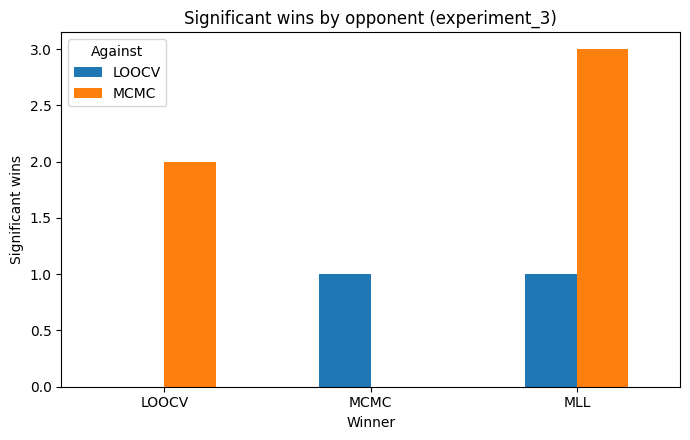

In [139]:
plot_significant_distribution(exp_path= Path("functions/experiments/experiment_3"))

In [143]:
summary = show_significant("functions/experiments/experiment_3/summary_table.csv")
display(summary)

,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Matérn2.5→RBF,MLL,0.0010,0.3295,MCMC,0.2205,2.2364,1.00,87.21,0.0008,MLL
1,Matérn0.5→Matérn2.5,MLL,0.0523,3.0201,MCMC,0.2884,0.1155,1.00,86.99,0.0014,MLL
2,Matérn0.5→Matérn2.5,LOOCV,0.1058,2.2128,MCMC,0.2884,0.1155,1.43,86.99,0.0030,LOOCV
3,Matérn2.5→Matérn0.5,LOOCV,0.1965,2.2260,MCMC,0.0501,2.1928,1.67,39.54,0.0051,MCMC
4,Matérn2.5→RBF,MLL,0.0010,0.3295,LOOCV,0.1418,2.2183,1.00,1.47,0.0167,MLL
5,RBF→Matérn2.5,LOOCV,-0.2303,2.1609,MCMC,0.0443,0.3323,1.49,65.62,0.0192,LOOCV
6,RBF→Matérn2.5,MLL,-0.1223,2.9650,MCMC,0.0443,0.3323,1.00,65.62,0.0219,MLL


In [144]:
all_wins = compute_all_wins("functions/experiments/experiment_3/summary_table.csv")
display(all_wins)

,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
MLL,13,4,9,17,7,6,0,30.8
LOOCV,8,2,6,17,0,6,2,25.0
MCMC,4,1,3,16,2,0,2,25.0


In [145]:
for experiment in summary["Experiment"]:
    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_3/{experiment}")
    display(sig)
    sig = test_significance(Path(f"functions/experiments/experiment_3/{experiment}"))
    display(sig)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,2.111852,2.160738,0.625000,False
1,MLL vs. LOOCV,20,1.654275,1.715184,0.492188,False
2,MLL vs. LOOCV,30,1.247333,1.524846,0.322266,False
3,MLL vs. LOOCV,40,1.241705,1.403755,0.064453,False
4,MLL vs. LOOCV,50,1.021573,1.258510,0.013672,True
5,MLL vs. MCMC,10,2.111852,2.245542,0.570312,False
6,MLL vs. MCMC,20,1.654275,1.649746,0.193359,False
7,MLL vs. MCMC,30,1.247333,1.649746,0.009766,True
8,MLL vs. MCMC,40,1.241705,1.588834,0.037109,True
9,MLL vs. MCMC,50,1.021573,1.461804,0.027344,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Matérn2.5→RBF,MLL,LOOCV,-0.8940,-0.1242,0.999
1,Matérn2.5→RBF,MLL,MCMC,-1.1489,-0.3488,1.000
2,Matérn2.5→RBF,LOOCV,MCMC,-0.7169,0.1757,0.814


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,2.246826,2.556981,0.195312,False
1,MLL vs. LOOCV,20,1.619718,1.935215,1.000000,False
2,MLL vs. LOOCV,30,1.304979,1.794188,0.232422,False
3,MLL vs. LOOCV,40,1.304979,1.521367,0.375000,False
4,MLL vs. LOOCV,50,0.986502,1.157402,0.375000,False
5,MLL vs. MCMC,10,2.246826,2.538037,0.039062,True
6,MLL vs. MCMC,20,1.619718,2.521806,0.019531,True
7,MLL vs. MCMC,30,1.304979,2.388172,0.001953,True
8,MLL vs. MCMC,40,1.304979,2.267578,0.001953,True
9,MLL vs. MCMC,50,0.986502,1.942552,0.001953,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Matérn0.5→Matérn2.5,MLL,LOOCV,-0.6936,0.3013,0.792
1,Matérn0.5→Matérn2.5,MLL,MCMC,-1.1649,-0.5541,1.000
2,Matérn0.5→Matérn2.5,LOOCV,MCMC,-1.2076,-0.1822,0.991


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,2.246826,2.556981,0.195312,False
1,MLL vs. LOOCV,20,1.619718,1.935215,1.000000,False
2,MLL vs. LOOCV,30,1.304979,1.794188,0.232422,False
3,MLL vs. LOOCV,40,1.304979,1.521367,0.375000,False
4,MLL vs. LOOCV,50,0.986502,1.157402,0.375000,False
5,MLL vs. MCMC,10,2.246826,2.538037,0.039062,True
6,MLL vs. MCMC,20,1.619718,2.521806,0.019531,True
7,MLL vs. MCMC,30,1.304979,2.388172,0.001953,True
8,MLL vs. MCMC,40,1.304979,2.267578,0.001953,True
9,MLL vs. MCMC,50,0.986502,1.942552,0.001953,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Matérn0.5→Matérn2.5,MLL,LOOCV,-0.6660,0.2870,0.769
1,Matérn0.5→Matérn2.5,MLL,MCMC,-1.1569,-0.5526,0.999
2,Matérn0.5→Matérn2.5,LOOCV,MCMC,-1.1982,-0.1925,0.990


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,1.812887,1.770079,0.820312,False
1,MLL vs. LOOCV,20,1.490445,1.571046,0.064453,False
2,MLL vs. LOOCV,30,1.469897,1.516299,0.019531,True
3,MLL vs. LOOCV,40,1.301772,1.404011,0.064453,False
4,MLL vs. LOOCV,50,1.163963,1.385350,0.048828,True
5,MLL vs. MCMC,10,1.812887,2.036830,0.910156,False
6,MLL vs. MCMC,20,1.490445,1.858767,0.921875,False
7,MLL vs. MCMC,30,1.469897,1.690306,0.921875,False
8,MLL vs. MCMC,40,1.301772,1.271062,0.492188,False
9,MLL vs. MCMC,50,1.163963,1.122282,0.193359,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Matérn2.5→Matérn0.5,MLL,LOOCV,-0.5910,0.2928,0.695
1,Matérn2.5→Matérn0.5,MLL,MCMC,0.0062,0.8370,0.016
2,Matérn2.5→Matérn0.5,LOOCV,MCMC,0.1686,0.8102,0.001


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,2.111852,2.160738,0.625000,False
1,MLL vs. LOOCV,20,1.654275,1.715184,0.492188,False
2,MLL vs. LOOCV,30,1.247333,1.524846,0.322266,False
3,MLL vs. LOOCV,40,1.241705,1.403755,0.064453,False
4,MLL vs. LOOCV,50,1.021573,1.258510,0.013672,True
5,MLL vs. MCMC,10,2.111852,2.245542,0.570312,False
6,MLL vs. MCMC,20,1.654275,1.649746,0.193359,False
7,MLL vs. MCMC,30,1.247333,1.649746,0.009766,True
8,MLL vs. MCMC,40,1.241705,1.588834,0.037109,True
9,MLL vs. MCMC,50,1.021573,1.461804,0.027344,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Matérn2.5→RBF,MLL,LOOCV,-0.8820,-0.1217,1.000
1,Matérn2.5→RBF,MLL,MCMC,-1.1349,-0.3283,1.000
2,Matérn2.5→RBF,LOOCV,MCMC,-0.7221,0.1653,0.813


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,1.430928,2.050360,0.148438,False
1,MLL vs. LOOCV,20,1.274895,1.561782,0.275391,False
2,MLL vs. LOOCV,30,1.220478,1.221405,0.375000,False
3,MLL vs. LOOCV,40,0.823422,0.954874,0.193359,False
4,MLL vs. LOOCV,50,0.681071,0.594848,1.000000,False
5,MLL vs. MCMC,10,1.430928,2.196909,0.078125,False
6,MLL vs. MCMC,20,1.274895,1.952415,0.009766,True
7,MLL vs. MCMC,30,1.220478,1.672035,0.001953,True
8,MLL vs. MCMC,40,0.823422,1.220395,0.009766,True
9,MLL vs. MCMC,50,0.681071,1.040254,0.130859,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,RBF→Matérn2.5,MLL,LOOCV,-0.3793,0.4935,0.264
1,RBF→Matérn2.5,MLL,MCMC,-0.7480,-0.0487,0.989
2,RBF→Matérn2.5,LOOCV,MCMC,-0.9754,-0.0004,0.976


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,1.430928,2.050360,0.148438,False
1,MLL vs. LOOCV,20,1.274895,1.561782,0.275391,False
2,MLL vs. LOOCV,30,1.220478,1.221405,0.375000,False
3,MLL vs. LOOCV,40,0.823422,0.954874,0.193359,False
4,MLL vs. LOOCV,50,0.681071,0.594848,1.000000,False
5,MLL vs. MCMC,10,1.430928,2.196909,0.078125,False
6,MLL vs. MCMC,20,1.274895,1.952415,0.009766,True
7,MLL vs. MCMC,30,1.220478,1.672035,0.001953,True
8,MLL vs. MCMC,40,0.823422,1.220395,0.009766,True
9,MLL vs. MCMC,50,0.681071,1.040254,0.130859,False


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,RBF→Matérn2.5,MLL,LOOCV,-0.3992,0.5008,0.280
1,RBF→Matérn2.5,MLL,MCMC,-0.7371,-0.0490,0.986
2,RBF→Matérn2.5,LOOCV,MCMC,-0.9479,0.0020,0.972


In [104]:
df = pd.read_csv("functions/experiments/experiment_3/summary_table.csv")

all_exp_paths = df["Experiment"].unique()

for name in all_exp_paths:
    folder = Path(f"functions/experiments/experiment_3/{name}")
    seeds = load_all_seeds(folder)
    save_path = folder/ "plot_overview.pdf"

    has_mcmc = "MCMC" in seeds[0]["methods"] if seeds else False
    
    if has_mcmc:
        plot_overview(seeds, title=name, save_path=save_path)
    else:
        print(f"Überspringe {name} (kein MCMC vorhanden)")


Überspringe RBF→Periodic (kein MCMC vorhanden)


In [ ]:
from functions.analyze import aggregate

results = aggregate("functions/experiments/experiment_3/Matérn2.5→RBF", n_runs=20)

final_mll = results["regrets"]["MLL"][:, -1]
print("Anzahl MLL-Seeds nahe/unter Null:", (final_mll < 0.01).sum(), "von", len(final_mll))
print("MLL-Werte:", final_mll)

final_mcmc = results["regrets"]["MCMC"][:, -1]
print("Anzahl MCMC-Seeds nahe/unter Null:", (final_mcmc < 0.01).sum(), "von", len(final_mcmc))
print("MCMC-Werte:", final_mcmc)

final_mcmc = results["regrets"]["LOOCV"][:, -1]
print("Anzahl MCMC-Seeds nahe/unter Null:", (final_mcmc < 0.01).sum(), "von", len(final_mcmc))
print("LOOCV-Werte:", final_mcmc)

### Experiment 4:

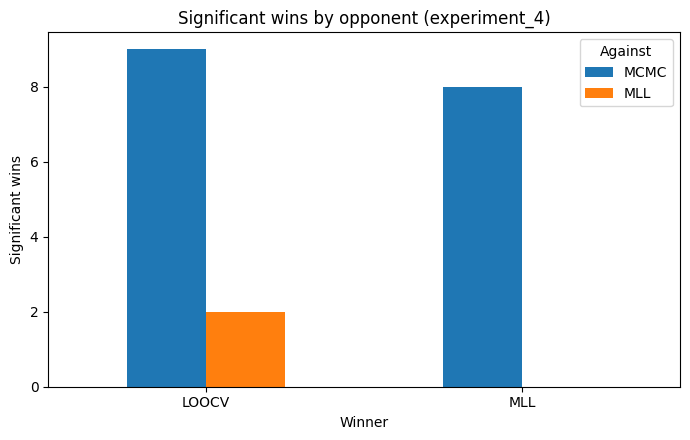

In [122]:
plot_significant_distribution(exp_path= Path("functions/experiments/experiment_4"))

In [128]:
summary = show_significant("functions/experiments/experiment_4/summary_table.csv")
display(summary)

,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,d20/Ellipsoid,LOOCV,5.9633,0.2095,MCMC,6.3690,0.1175,3.18,13.71,0.0059,LOOCV
1,d20/Rosenbrock,LOOCV,3.7357,0.2380,MCMC,4.9879,0.1487,2.85,16.07,0.0059,LOOCV
2,d20/Rosenbrock,MLL,4.1471,0.2518,MCMC,4.9879,0.1487,1.00,16.07,0.0059,MLL
3,d20/Rastrigin,LOOCV,2.4944,0.0809,MCMC,2.8206,0.0940,2.90,15.71,0.0059,LOOCV
4,d20/Rastrigin,MLL,2.5090,0.0716,MCMC,2.8206,0.0940,1.00,15.71,0.0059,MLL
5,d20/Gallagher,MLL,1.5099,0.1208,MCMC,1.8698,0.0930,1.00,13.16,0.0059,MLL
6,d20/Sphere,MLL,1.0659,0.3075,MCMC,1.9494,0.1197,1.00,20.68,0.0059,MLL
7,d20/Ellipsoid,MLL,5.9348,0.1408,MCMC,6.3690,0.1175,1.00,13.71,0.0059,MLL
8,d20/Sphere,LOOCV,-1.1281,0.9111,MCMC,1.9494,0.1197,2.94,20.68,0.0059,LOOCV
9,d10/Sphere,MLL,-1.0967,0.1951,LOOCV,-2.4055,0.3170,1.00,6.47,0.0059,LOOCV


In [129]:
all_wins = compute_all_wins("functions/experiments/experiment_4/summary_table.csv")
display(all_wins)

,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,17,11,6,20,0,10,7,64.7
MLL,13,8,5,20,3,10,0,61.5


In [ ]:
#summary = summary[summary["Winner"] == "LOOCV"]
#summary = summary[summary["Method A"] == "MLL"]
for experiment in summary["Experiment"]:
    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_4/{experiment}")
    display(sig)
    sig = test_significance(Path(f"functions/experiments/experiment_4/{experiment}"))
    display(sig)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,17.339656,6.418338,0.013672,True
1,MLL vs. LOOCV,20,4.681331,0.026747,0.001953,True
2,MLL vs. LOOCV,30,0.808468,0.006560,0.001953,True
3,MLL vs. LOOCV,40,0.154783,0.005213,0.001953,True
4,MLL vs. LOOCV,50,0.080137,0.003979,0.001953,True
5,MLL vs. MCMC,10,17.339656,43.204991,0.011719,True
6,MLL vs. MCMC,20,4.681331,37.018421,0.001953,True
7,MLL vs. MCMC,30,0.808468,24.048744,0.001953,True
8,MLL vs. MCMC,40,0.154783,6.380868,0.003906,True
9,MLL vs. MCMC,50,0.080137,0.467187,0.005859,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere,MLL,LOOCV,0.0640,0.1542,0.000
1,Sphere,MLL,MCMC,-0.8460,-0.1634,0.999
2,Sphere,LOOCV,MCMC,-0.9154,-0.2669,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,69906.093199,27158.088516,0.001953,True
1,MLL vs. LOOCV,20,50400.145352,18984.951474,0.001953,True
2,MLL vs. LOOCV,30,40839.772716,10622.872917,0.001953,True
3,MLL vs. LOOCV,40,35184.562919,8053.815955,0.001953,True
4,MLL vs. LOOCV,50,14057.785086,5485.419366,0.003906,True
5,MLL vs. MCMC,10,69906.093199,201519.261929,0.001953,True
6,MLL vs. MCMC,20,50400.145352,157353.645427,0.001953,True
7,MLL vs. MCMC,30,40839.772716,134303.180892,0.001953,True
8,MLL vs. MCMC,40,35184.562919,119685.496434,0.001953,True
9,MLL vs. MCMC,50,14057.785086,97253.883059,0.001953,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Rosenbrock,MLL,LOOCV,1958.2603,28508.0395,0.003
1,Rosenbrock,MLL,MCMC,-108217.7551,-54465.2657,1.000
2,Rosenbrock,LOOCV,MCMC,-114421.7055,-69544.5893,1.000


### Experiment 5 (Low Dim):

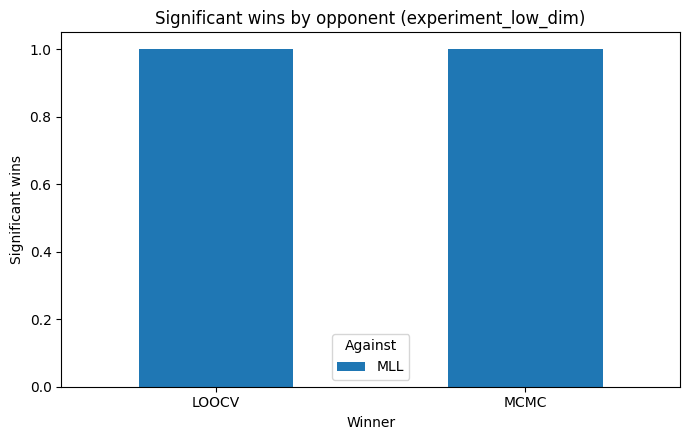

In [133]:
plot_significant_distribution(exp_path= Path("functions/experiments/experiment_low_dim"))

In [ ]:
summary = show_significant("functions/experiments/experiment_low_dim/summary_table.csv")
display(summary)

,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Sphere,MLL,-3.8194,0.4284,LOOCV,-5.3126,0.7188,1.0,2.47,0.0059,LOOCV
1,Sphere,MLL,-3.8194,0.4284,MCMC,-4.3240,0.6161,1.0,92.47,0.0293,MCMC


In [135]:
all_wins = compute_all_wins("functions/experiments/experiment_low_dim/summary_table.csv")
display(all_wins)

,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,7,1,6,10,0,3,4,14.3
MCMC,5,1,4,10,2,0,3,20.0
MLL,3,0,3,10,1,2,0,0.0


In [138]:
for experiment in summary["Experiment"]:
    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_low_dim/{experiment}")
    display(sig)
    sig = test_significance(Path(f"functions/experiments/experiment_low_dim/{experiment}"))
    display(sig)

,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,0.001284,0.000010,0.001953,True
1,MLL vs. LOOCV,20,0.000157,0.000008,0.001953,True
2,MLL vs. LOOCV,30,0.000157,0.000006,0.001953,True
3,MLL vs. LOOCV,40,0.000153,0.000005,0.001953,True
4,MLL vs. LOOCV,50,0.000153,0.000005,0.001953,True
5,MLL vs. MCMC,10,0.001284,0.001006,0.695312,False
6,MLL vs. MCMC,20,0.000157,0.000077,0.375000,False
7,MLL vs. MCMC,30,0.000157,0.000055,0.130859,False
8,MLL vs. MCMC,40,0.000153,0.000048,0.027344,True
9,MLL vs. MCMC,50,0.000153,0.000047,0.009766,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere,MLL,LOOCV,0.0001,0.0003,0.000
1,Sphere,MLL,MCMC,0.0000,0.0003,0.005
2,Sphere,LOOCV,MCMC,-0.0001,-0.0000,1.000


,methods,num_loop,median_a,median_b,p_value,significant
0,MLL vs. LOOCV,10,0.001284,0.000010,0.001953,True
1,MLL vs. LOOCV,20,0.000157,0.000008,0.001953,True
2,MLL vs. LOOCV,30,0.000157,0.000006,0.001953,True
3,MLL vs. LOOCV,40,0.000153,0.000005,0.001953,True
4,MLL vs. LOOCV,50,0.000153,0.000005,0.001953,True
5,MLL vs. MCMC,10,0.001284,0.001006,0.695312,False
6,MLL vs. MCMC,20,0.000157,0.000077,0.375000,False
7,MLL vs. MCMC,30,0.000157,0.000055,0.130859,False
8,MLL vs. MCMC,40,0.000153,0.000048,0.027344,True
9,MLL vs. MCMC,50,0.000153,0.000047,0.009766,True


,folder,method_a,method_b,ci_lower,ci_upper,pct_a_better
0,Sphere,MLL,LOOCV,0.0001,0.0003,0.000
1,Sphere,MLL,MCMC,0.0000,0.0002,0.004
2,Sphere,LOOCV,MCMC,-0.0001,-0.0000,0.998


### Experiment Analysis Experiments

#### Initial Data Point Sensitivity

In [224]:
#plot_significant_distribution(exp_path= Path("functions/experiments/experiment_init_sensitivity"))
#no sig results

In [225]:
summary = show_significant("functions/experiments/experiment_init_sensitivity/summary_table.csv")
display(summary)

,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Sphere/n_init_10,LOOCV,-3.2089,0.3933,MCMC,-2.0565,0.3190,5.66,40.77,0.0059,LOOCV
1,Sphere/n_init_20,MLL,-2.0347,0.2176,LOOCV,-3.9540,0.4220,1.00,5.57,0.0059,LOOCV
2,Sphere/n_init_20,LOOCV,-3.9540,0.4220,MCMC,-2.1523,0.4063,5.57,38.39,0.0059,LOOCV
3,Sphere/n_init_5,MLL,-1.9148,0.2785,LOOCV,-3.3503,0.2887,1.00,4.74,0.0059,LOOCV
4,Sphere/n_init_5,LOOCV,-3.3503,0.2887,MCMC,-1.9994,0.3584,4.74,39.94,0.0059,LOOCV
5,Sum_of_different_Powers/n_init_10,LOOCV,-0.4161,0.4740,MCMC,0.5118,0.4677,1.98,45.80,0.0059,LOOCV
6,Ellipsoid/n_init_10,MLL,4.0444,0.4127,LOOCV,3.5315,0.2795,1.00,1.95,0.0117,LOOCV
7,Sphere/n_init_10,MLL,-2.0205,0.3811,LOOCV,-3.2089,0.3933,1.00,5.66,0.0117,LOOCV
8,Sum_of_different_Powers/n_init_20,MLL,0.2619,0.3749,LOOCV,-0.2923,0.3769,1.00,1.62,0.0117,LOOCV
9,Ellipsoid/n_init_20,MLL,4.2206,0.2962,LOOCV,3.5990,0.3478,1.00,2.05,0.0176,LOOCV


In [ ]:
print("Experiment Init Sensitivity")
all_wins = compute_all_wins("functions/experiments/experiment_init_sensitivity/summary_table.csv")
display(all_wins)

print("Baseline to compare")
functions = pd.read_csv(
    "functions/experiments/experiment_init_sensitivity/summary_table.csv"
)["Experiment"].str.rsplit("/", n=1).str[0]

all_wins_baseline = compute_all_filtered(
    "functions/experiments/experiment_1/summary_table.csv", functions
)
display(all_wins_baseline)

Experiment Init Sensitivity


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,22,13,9,24,0,10,12,59.1
MCMC,11,0,11,24,2,0,9,0.0
MLL,3,0,3,24,0,3,0,0.0


Baseline to compare


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,7,6,1,8,0,3,4,85.7
MCMC,4,0,4,8,1,0,3,0.0
MLL,1,0,1,8,0,1,0,0.0


In [232]:
df = pd.read_csv("functions/experiments/experiment_init_sensitivity/summary_table.csv")

for n in [5, 10, 20]:
    subset = df[df["Experiment"].str.endswith(f"/n_init_{n}")]
    subset.to_csv("../tmp/n_init_subset.csv", index=False)
    print(f"n_init={n}")
    display(compute_all_wins("../tmp/n_init_subset.csv"))

n_init=5


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,7,2,5,8,0,3,4,28.6
MCMC,4,0,4,8,1,0,3,0.0
MLL,1,0,1,8,0,1,0,0.0


n_init=10


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,7,6,1,8,0,3,4,85.7
MCMC,4,0,4,8,1,0,3,0.0
MLL,1,0,1,8,0,1,0,0.0


n_init=20


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,
LOOCV,8,5,3,8,4,4,62.5
MCMC,3,0,3,8,0,3,0.0
MLL,1,0,1,8,1,0,0.0


In [230]:
"""
for function in functions:
    print("Baseline:")
    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_1/{function}")
    display(sig)
    sig = test_significance(Path(f"functions/experiments/experiment_1/{function}"))
    display(sig)

for experiment in summary["Experiment"]:
    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_init_sensitivity/{experiment}")
    display(sig)
    sig = test_significance(Path(f"functions/experiments/experiment_init_sensitivity/{experiment}"))
    display(sig)
    """

'\nfor function in functions:\n    print("Baseline:")\n    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_1/{function}")\n    display(sig)\n    sig = test_significance(Path(f"functions/experiments/experiment_1/{function}"))\n    display(sig)\n\nfor experiment in summary["Experiment"]:\n    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_init_sensitivity/{experiment}")\n    display(sig)\n    sig = test_significance(Path(f"functions/experiments/experiment_init_sensitivity/{experiment}"))\n    display(sig)\n    '

#### More Iterations Experiment

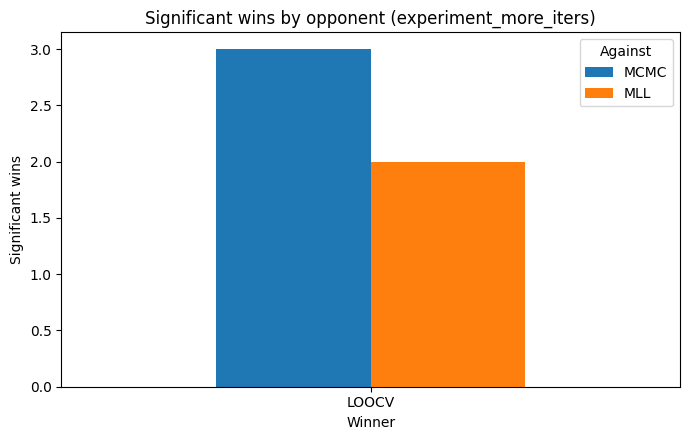

In [181]:
plot_significant_distribution(exp_path= Path("functions/experiments/experiment_more_iters"))

In [233]:
summary = show_significant("functions/experiments/experiment_more_iters/summary_table.csv")
display(summary)

,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,loop_count100/Sphere,MLL,-2.2955,0.2426,LOOCV,-3.6648,0.4663,1.00,5.26,0.0059,LOOCV
1,loop_count100/Sphere,LOOCV,-3.6648,0.4663,MCMC,-2.3270,0.2285,5.26,37.47,0.0059,LOOCV
2,loop_count200/Sphere,MLL,-2.5778,0.2232,LOOCV,-4.3571,0.4915,1.00,5.20,0.0059,LOOCV
3,loop_count200/Sphere,LOOCV,-4.3571,0.4915,MCMC,-2.7491,0.1211,5.20,30.58,0.0059,LOOCV
4,loop_count200/Ellipsoid,LOOCV,2.6964,0.4285,MCMC,3.0655,0.3752,2.20,21.79,0.0293,LOOCV


In [ ]:
print("Experiment More Iters")
all_wins = compute_all_wins("functions/experiments/experiment_more_iters/summary_table.csv")
display(all_wins)

functions = (
    pd.read_csv("functions/experiments/experiment_more_iters/summary_table.csv")
    ["Experiment"]
    .str.rsplit("/", n=1).str[-1]
    .unique()
)

# Gallagher heißt in der Baseline "Gallagher_101"
functions = pd.Series(functions).replace("Gallagher", "Gallagher_101").unique()

print("Baseline to compare")
all_wins_baseline = compute_all_filtered(
    "functions/experiments/experiment_1/summary_table.csv", functions
)
display(all_wins_baseline)

Experiment More Iters


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,13,5,8,20,0,7,6,38.5
MLL,9,0,9,20,4,5,0,0.0
MCMC,8,0,8,20,3,0,5,0.0


Baseline to compare


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,7,5,2,10,0,4,3,71.4
MCMC,4,0,4,10,1,0,3,0.0
MLL,4,1,3,10,2,2,0,25.0


In [241]:
df = pd.read_csv("functions/experiments/experiment_more_iters/summary_table.csv")

for n in ["loop_count100", "loop_count200"]:
    subset = df[df["Experiment"].str.startswith(f"{n}/")]
    subset.to_csv("../tmp/loop_count_subset.csv", index=False)
    print(n)
    display(compute_all_wins("../tmp/loop_count_subset.csv"))

loop_count100


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,8,2,6,10,0,4,4,25.0
MLL,4,0,4,10,1,3,0,0.0
MCMC,3,0,3,10,1,0,2,0.0


loop_count200


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,5,3,2,10,0,3,2,60.0
MLL,5,0,5,10,3,2,0,0.0
MCMC,5,0,5,10,2,0,3,0.0


#### MCMC with more Resources Experiment

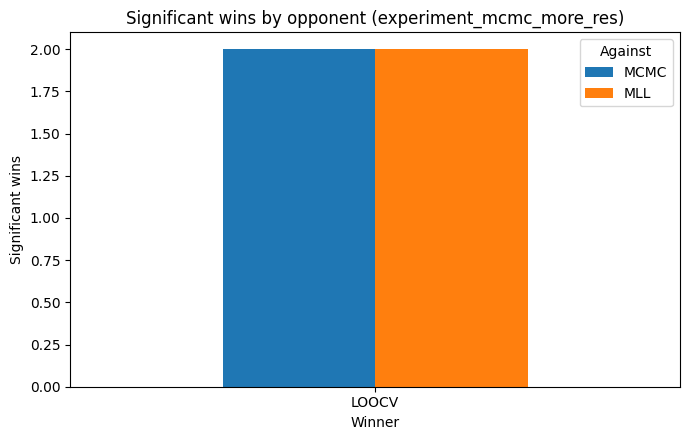

In [169]:
plot_significant_distribution(exp_path= Path("functions/experiments/experiment_mcmc_more_res"))

In [170]:
summary = show_significant("functions/experiments/experiment_mcmc_more_res/summary_table.csv")
display(summary)

,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Sphere,LOOCV,-3.2089,0.3933,MCMC,-2.1215,0.2996,5.63,49.78,0.0059,LOOCV
1,Sphere,MLL,-2.0205,0.3811,LOOCV,-3.2089,0.3933,1.00,5.63,0.0117,LOOCV
2,Sum_of_diferent_Powers,LOOCV,-0.4161,0.4740,MCMC,0.4301,0.4530,1.90,52.40,0.0117,LOOCV
3,Sum_of_diferent_Powers,MLL,0.1604,0.5448,LOOCV,-0.4161,0.4740,1.00,1.90,0.0410,LOOCV


In [267]:
print("Experiment MCMC More Resources")
all_wins = compute_all_wins("functions/experiments/experiment_mcmc_more_res/summary_table.csv")
display(all_wins)

print("Baseline to compare")

functions = pd.read_csv(
    "functions/experiments/experiment_mcmc_more_res/summary_table.csv"
)["Experiment"].unique()

functions = pd.Series(functions).replace({
    "Sum_of_diferent_Powers": "Sum_of_different_Powers",
    "Sharp Ridge": "Sharp_Ridge"
}).unique()

all_wins_baseline = compute_all_filtered(
    "functions/experiments/experiment_1/summary_table.csv", functions
)
display(all_wins_baseline)

Experiment MCMC More Resources


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,
LOOCV,10,4,6,10,5,5,40.0
MLL,3,0,3,10,3,0,0.0
MCMC,2,0,2,10,0,2,0.0


Baseline to compare


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,
LOOCV,10,4,6,10,5,5,40.0
MCMC,3,0,3,10,0,3,0.0
MLL,2,0,2,10,2,0,0.0


In [268]:
"""
for experiment in summary["Experiment"]:
    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_mcmc_more_res/{experiment}")
    display(sig)
    sig = test_significance(Path(f"functions/experiments/experiment_mcmc_more_res/{experiment}"))
    display(sig)
"""

'\nfor experiment in summary["Experiment"]:\n    sig = test_sensitivity_over_iterations(f"functions/experiments/experiment_mcmc_more_res/{experiment}")\n    display(sig)\n    sig = test_significance(Path(f"functions/experiments/experiment_mcmc_more_res/{experiment}"))\n    display(sig)\n'

#### MCMC more res high dim

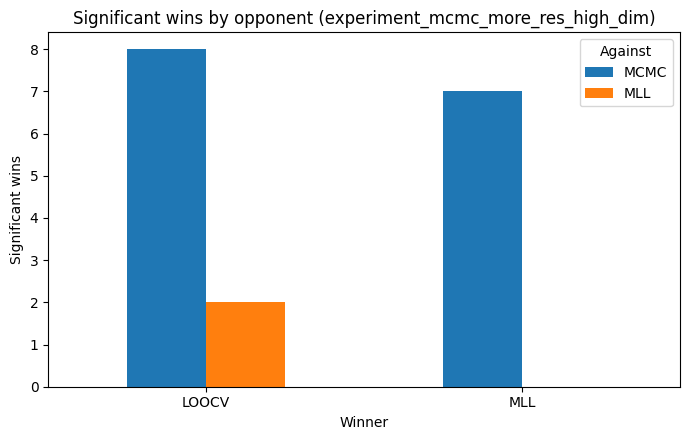

In [269]:
plot_significant_distribution(exp_path= Path("functions/experiments/experiment_mcmc_more_res_high_dim"))

In [270]:
summary = show_significant("functions/experiments/experiment_mcmc_more_res_high_dim/summary_table.csv")
display(summary)

,Experiment,Method A,Log 10 Median A,Log 10 Std A,Method B,Log 10 Median B,Log 10 Std B,Fit Time Ratio A,Fit Time Ratio B,p-value,Winner
0,Ellipsoid_dim10,LOOCV,5.0057,0.2696,MCMC,5.5692,0.1901,2.42,22.31,0.0059,LOOCV
1,Sphere_dim10,LOOCV,-2.4055,0.3170,MCMC,-0.6654,0.3356,6.45,27.81,0.0059,LOOCV
2,Sphere_dim10,MLL,-1.0967,0.1951,LOOCV,-2.4055,0.3170,1.00,6.45,0.0059,LOOCV
3,Rosenbrock_dim20,LOOCV,3.7357,0.2380,MCMC,4.9654,0.1850,2.91,18.80,0.0059,LOOCV
4,Rosenbrock_dim20,MLL,4.1471,0.2518,MCMC,4.9654,0.1850,1.00,18.80,0.0059,MLL
5,Sphere_dim20,MLL,1.0659,0.3075,MCMC,1.8861,0.1018,1.00,24.60,0.0059,MLL
6,Rastrigin_dim20,MLL,2.5090,0.0716,MCMC,2.8166,0.0909,1.00,17.62,0.0059,MLL
7,Rastrigin_dim20,LOOCV,2.4944,0.0809,MCMC,2.8166,0.0909,2.99,17.62,0.0059,LOOCV
8,Gallagher_dim20,LOOCV,1.5815,0.1557,MCMC,1.8600,0.0289,2.47,15.30,0.0059,LOOCV
9,Gallagher_dim20,MLL,1.5099,0.1208,MCMC,1.8600,0.0289,1.00,15.30,0.0059,MLL


In [271]:
print("Experiment MCMC More Resources High Dim")
all_wins = compute_all_wins("functions/experiments/experiment_mcmc_more_res_high_dim/summary_table.csv")
display(all_wins)

print("Baseline High Dim to compare")
all_wins_baseline = compute_all_wins("functions/experiments/experiment_4/summary_table.csv")
display(all_wins_baseline)

Experiment MCMC More Resources High Dim


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,17,10,7,20,0,10,7,58.8
MLL,13,7,6,20,3,10,0,53.8


Baseline High Dim to compare


,all_wins,significant_wins,non_significant_wins,total_comparisons,wins_vs_LOOCV,wins_vs_MCMC,wins_vs_MLL,Conv. Rate
Winner,,,,,,,,
LOOCV,17,11,6,20,0,10,7,64.7
MLL,13,8,5,20,3,10,0,61.5


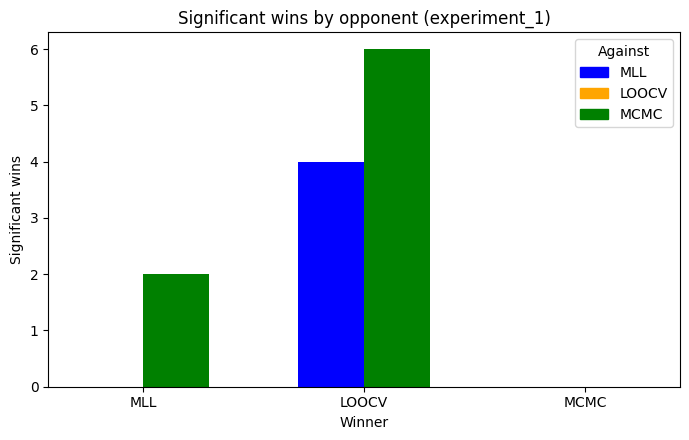

In [64]:
plot_significant_distribution(exp_path= Path("functions/experiments/experiment_1"))

# Appendix
Make bigger Plot grids out of the existing plots for the Appendix

In [ ]:
#AI GENERATED SCRIPT, TO MAKE GRIDS OUT OF THE EXISTING SMALLER PLOTS 

import pymupdf  # PyMuPDF
import matplotlib.pyplot as plt
import math
from pathlib import Path

def load_pdf_as_image(pdf_path: Path, dpi: int = 150):
    """returns image array for the given pdf"""
    doc = pymupdf.open(pdf_path)
    page = doc[0]
    zoom = dpi / 72  # PDF-Standard ist 72 dpi
    mat = pymupdf.Matrix(zoom, zoom)
    pix = page.get_pixmap(matrix=mat)
    img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    doc.close()
    return img


def select_pdf_plots(exp_path: Path, mode: str = "significant", explicit_list: list = None, pdf_name = "plot_regret.pdf"):
    """Chooses Functions based on given mode or explicit list of experiments"""
    if explicit_list is not None:
        function_names = explicit_list
    else:
        df = pd.read_csv(exp_path / "summary_table.csv")
        if mode == "significant":
            selected_df = df[df["Signifikant?"] == "Ja"]
        elif mode == "all":
            selected_df = df
        function_names = selected_df["Experiment"].unique().tolist()

    items = []
    for name in function_names:
        pdf_path = exp_path / name / pdf_name
        if not pdf_path.exists():
            print(f"Warning: {pdf_path} not found, skipping.")
            continue
        items.append((name, pdf_path))
    return items


def plot_pdf_grid(items: list, ncols: int = 3, save_path: Path = None, figsize_per=(3.5, 2.8), dpi: int = 150):
    """Builds grid out of given plots"""
    n = len(items)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per[0]*ncols, figsize_per[1]*nrows))
    axes = axes.flatten()

    for ax, (title, pdf_path) in zip(axes, items):
        img = load_pdf_as_image(pdf_path, dpi=dpi)
        ax.imshow(img)
        ax.set_title(title, fontsize=9)
        ax.axis("off")  # Achsen weg, da die Achsenbeschriftung schon im Bild selbst steckt

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=dpi, bbox_inches="tight")

## Regret Plots

### Significant

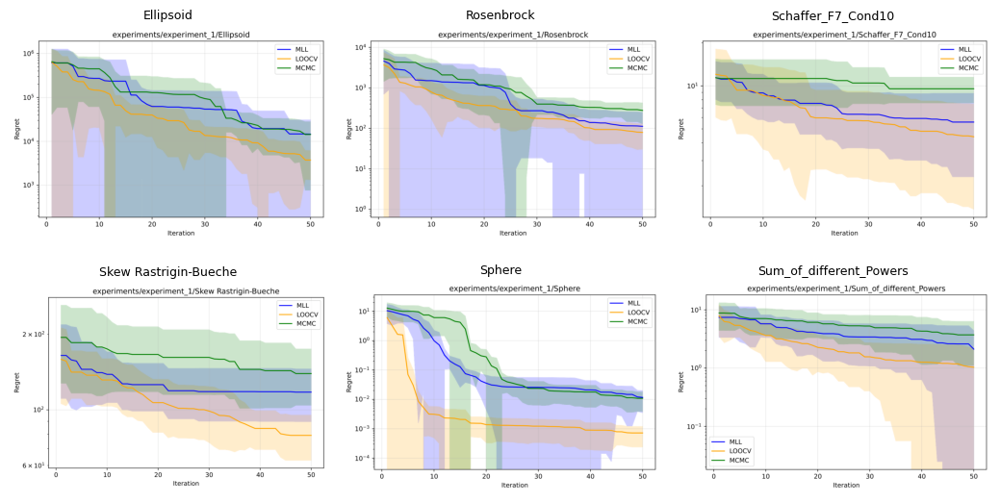

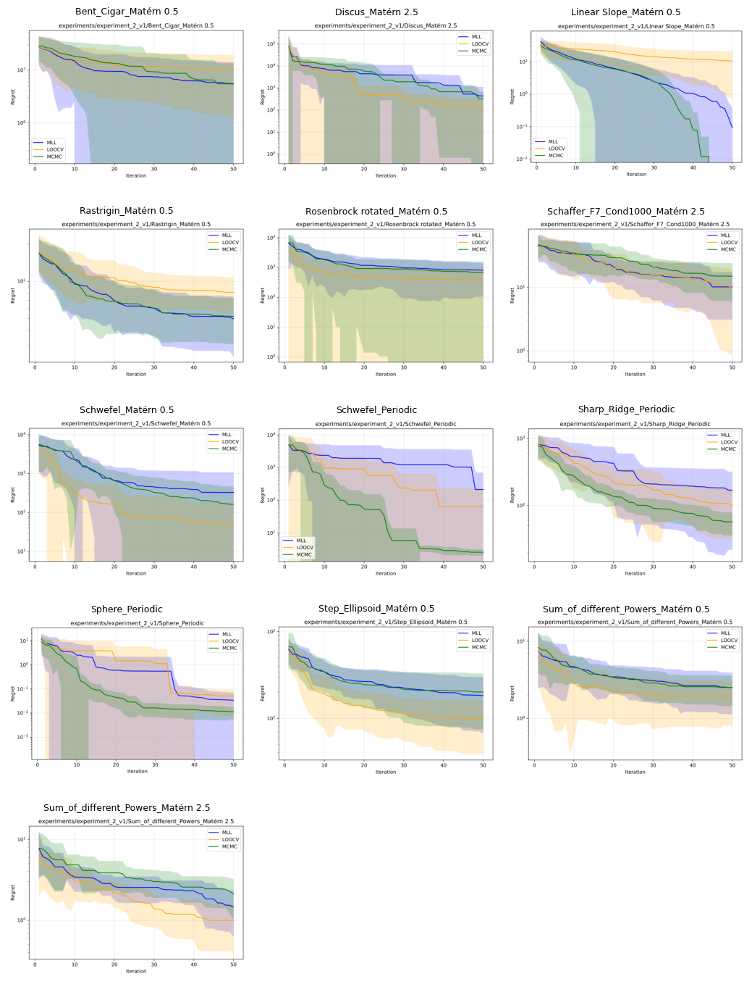

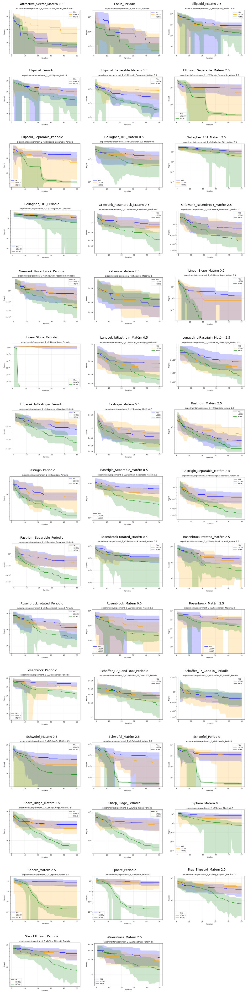

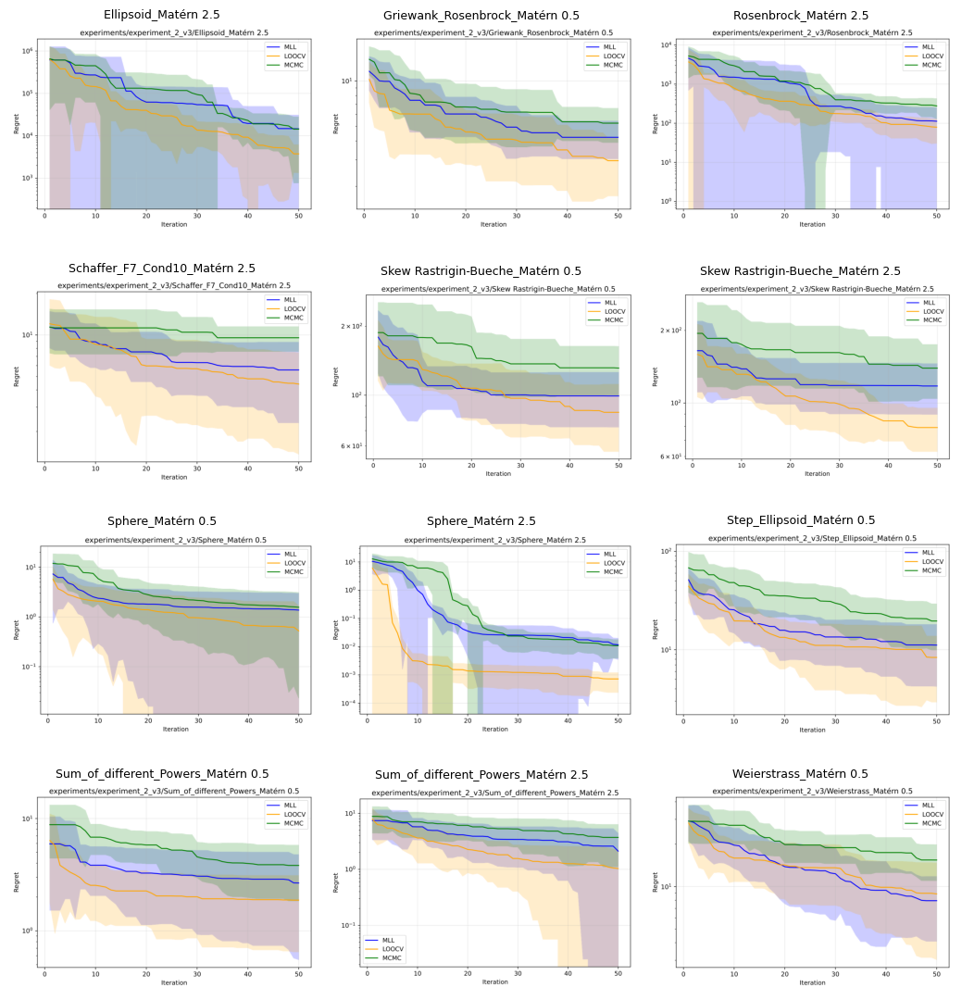

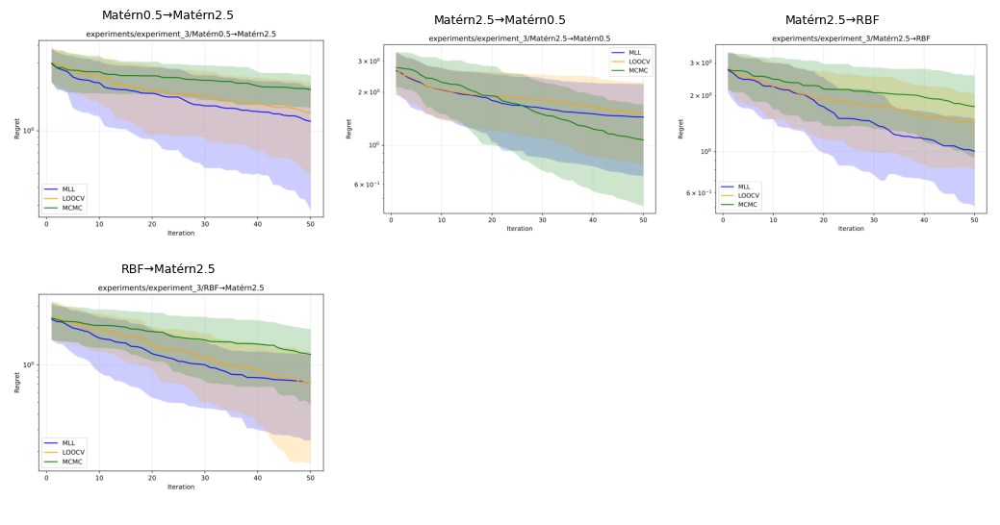

...

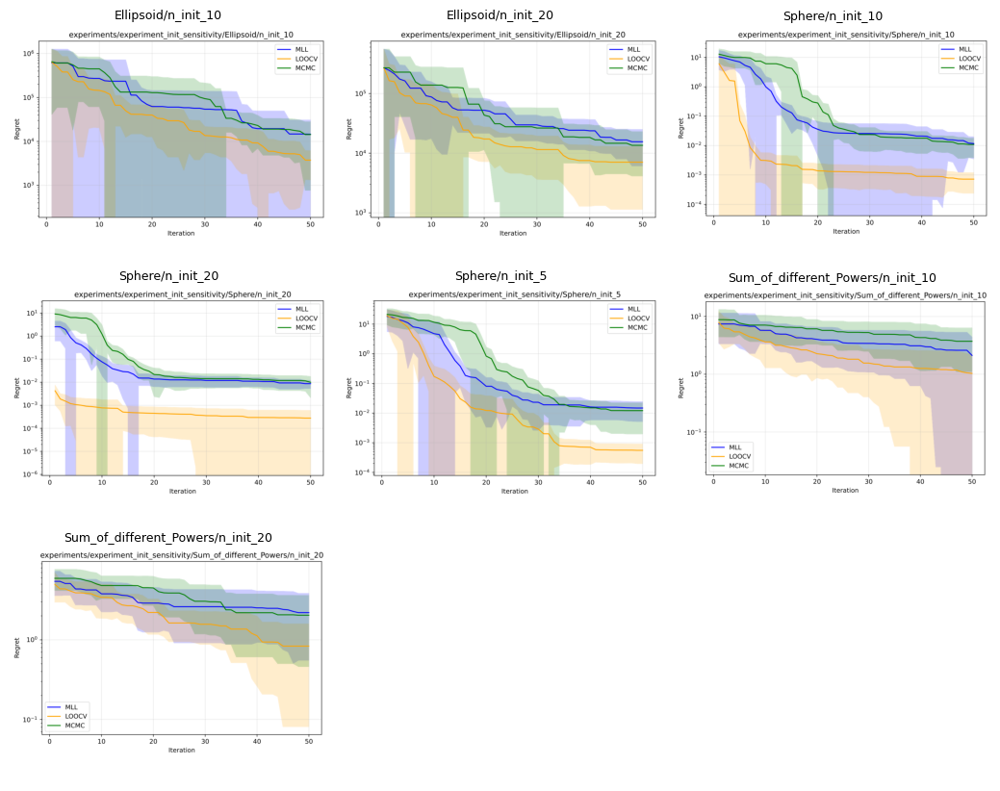

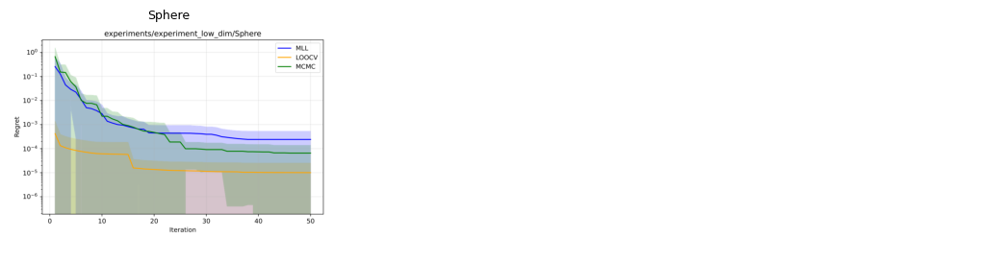

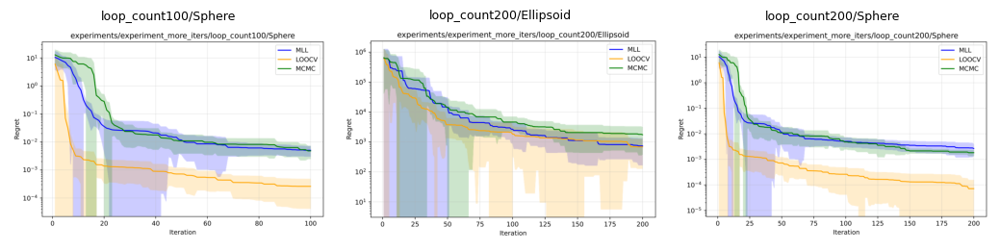

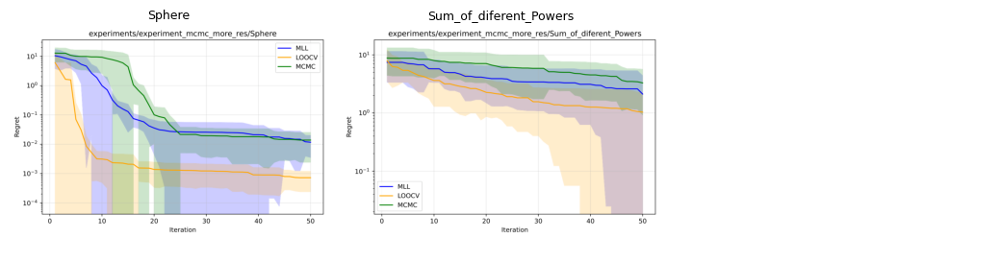

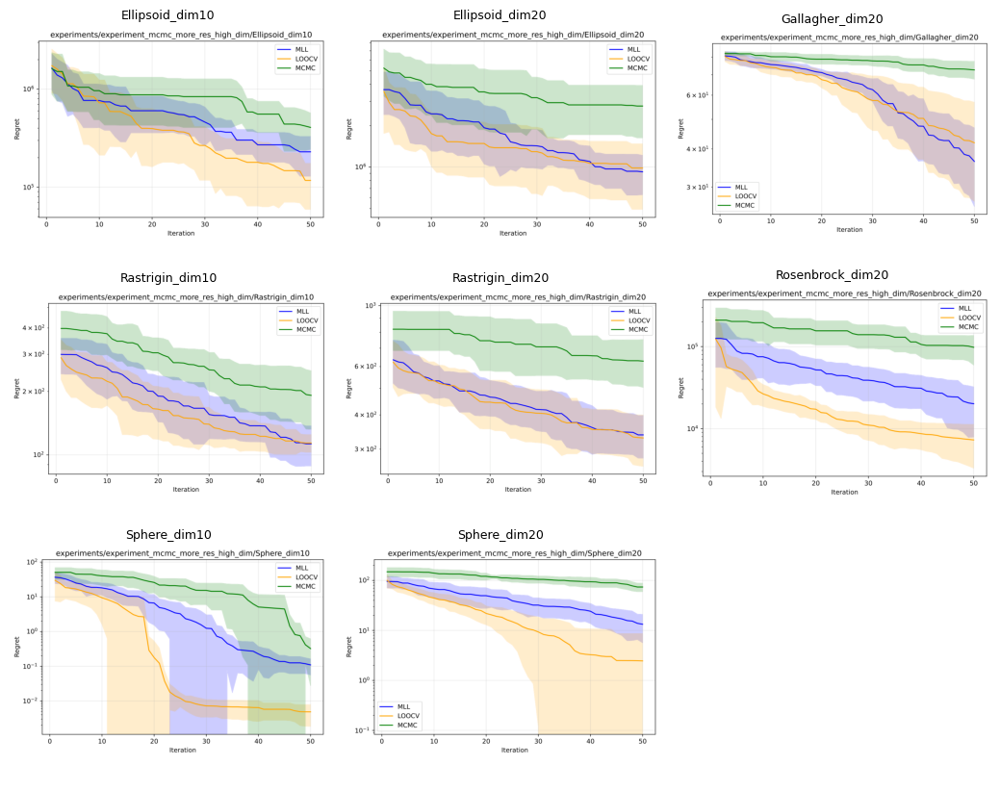

In [81]:
from pathlib import Path

for path_str in ["experiment_1", "experiment_2_v1", "experiment_2_v2", "experiment_2_v3", "experiment_3", "experiment_4", "experiment_init_sensitivity", "experiment_low_dim", "experiment_more_iters", "experiment_mcmc_more_res", "experiment_mcmc_more_res_high_dim"]:
    path = "functions/experiments/" + path_str
    exp_path = Path(path)
    appendix_path = Path("appendix")
    appendix_path.mkdir(parents=True, exist_ok=True)

    items = select_pdf_plots(exp_path, mode="significant")
    save_str = path_str + "_significant_grid.pdf"
    save_path = appendix_path / save_str
    plot_pdf_grid(
        items,
        ncols=3,
        save_path= save_path,
        dpi=150
    )

In [78]:
def plot_pdf_grid_chunked(items: list, ncols: int = 3, max_per_page: int = 15,
                           save_path_template: str = "grid_part{}.pdf", dpi: int = 150,
                           figsize_per=(3.5, 2.8)):
    """
    Teilt eine lange Liste von (Titel, PDF-Pfad)-Tupeln in mehrere Grids auf,
    je max_per_page Plots pro Seite/Datei.
    """
    n_total = len(items)
    n_chunks = math.ceil(n_total / max_per_page)

    for chunk_idx in range(n_chunks):
        start = chunk_idx * max_per_page
        end = start + max_per_page
        chunk_items = items[start:end]

        save_path = Path(save_path_template.format(chunk_idx + 1))
        plot_pdf_grid(chunk_items, ncols=ncols, save_path=save_path, dpi=dpi, figsize_per=figsize_per)

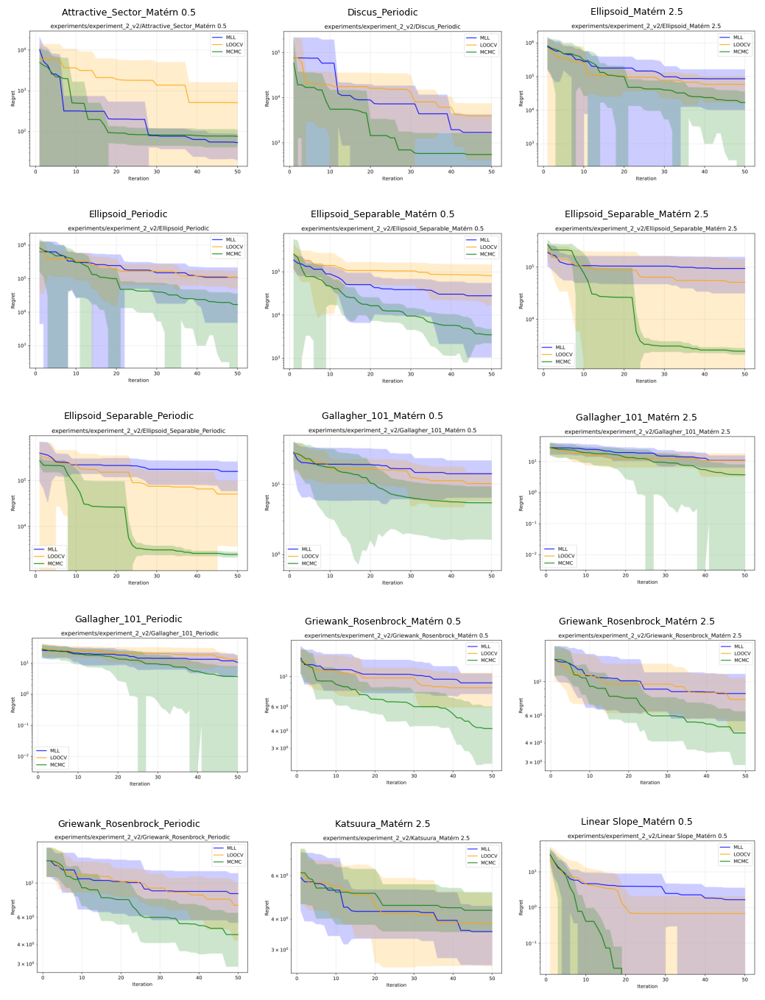

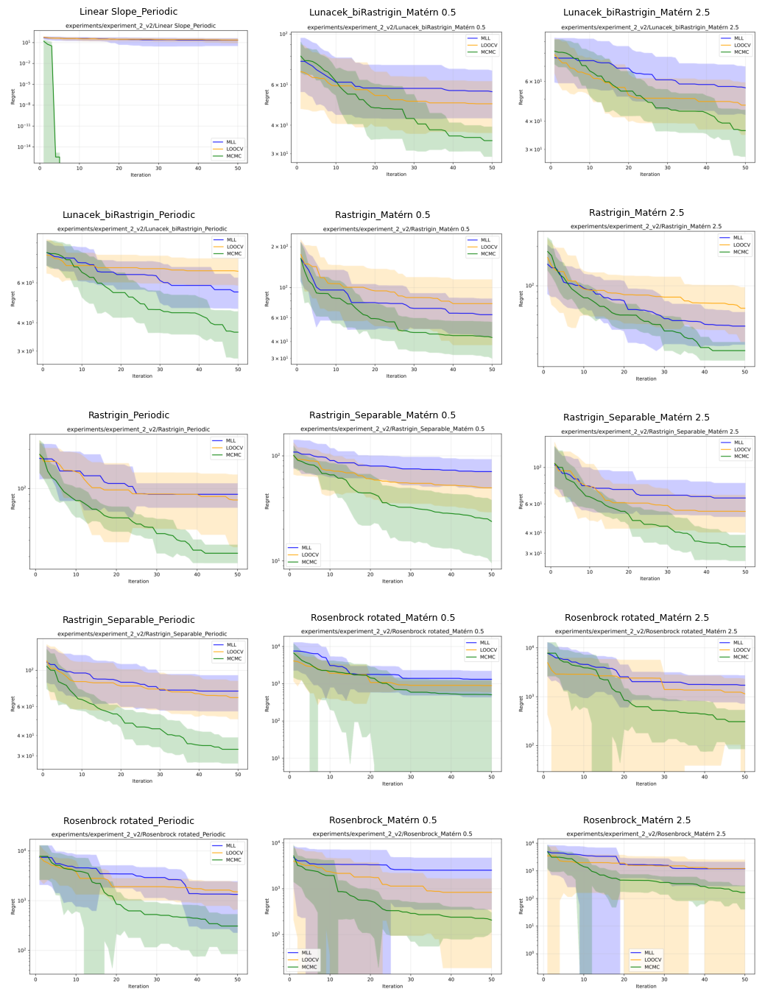

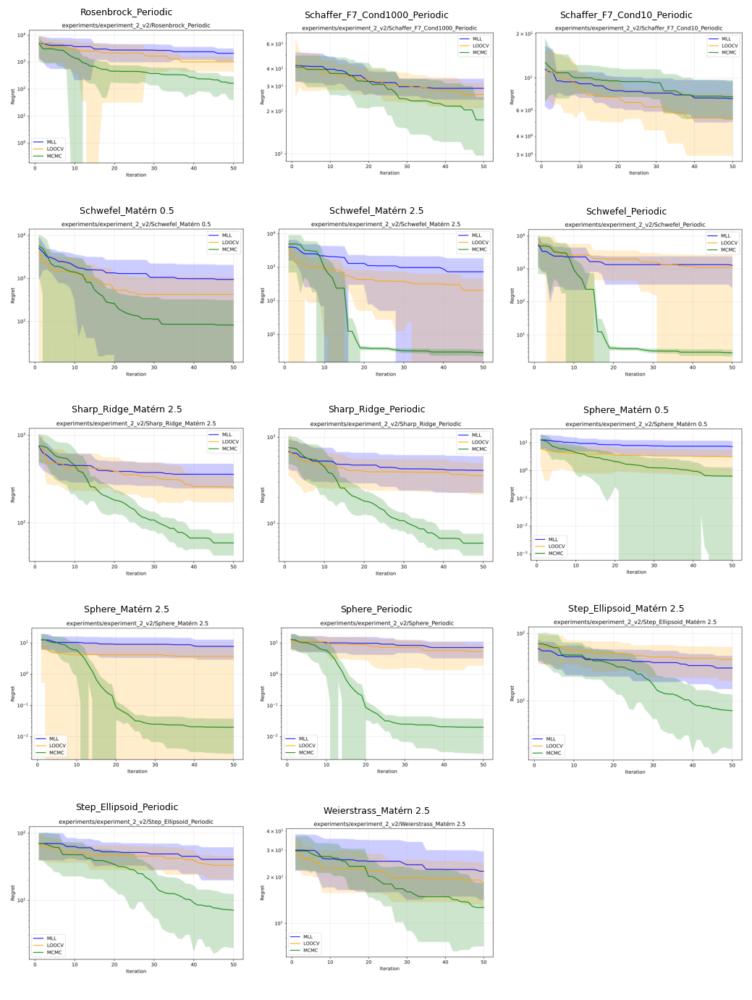

In [80]:
path = "functions/experiments/experiment_2_v2"
exp_path = Path(path)
appendix_path = Path("appendix")

items = select_pdf_plots(exp_path, mode="significant")

plot_pdf_grid_chunked(
    items,
    ncols=3,
    max_per_page=15,
    save_path_template=str(appendix_path / "exp2_v2_grid_part{}.pdf")
)

### Insignificant

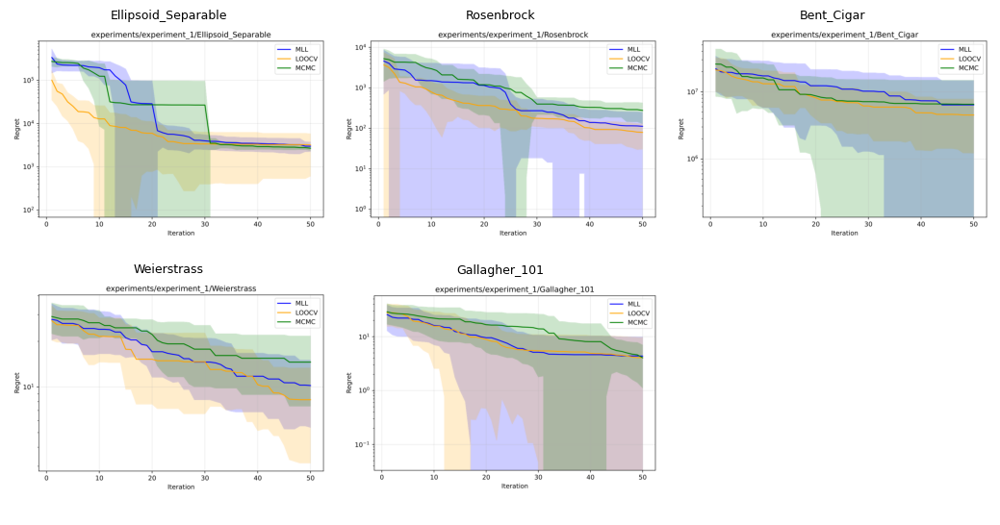

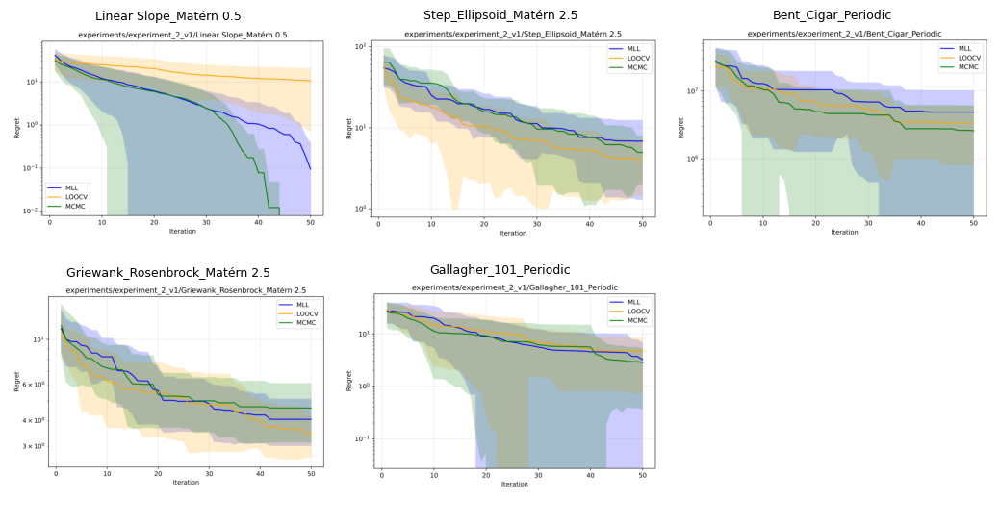

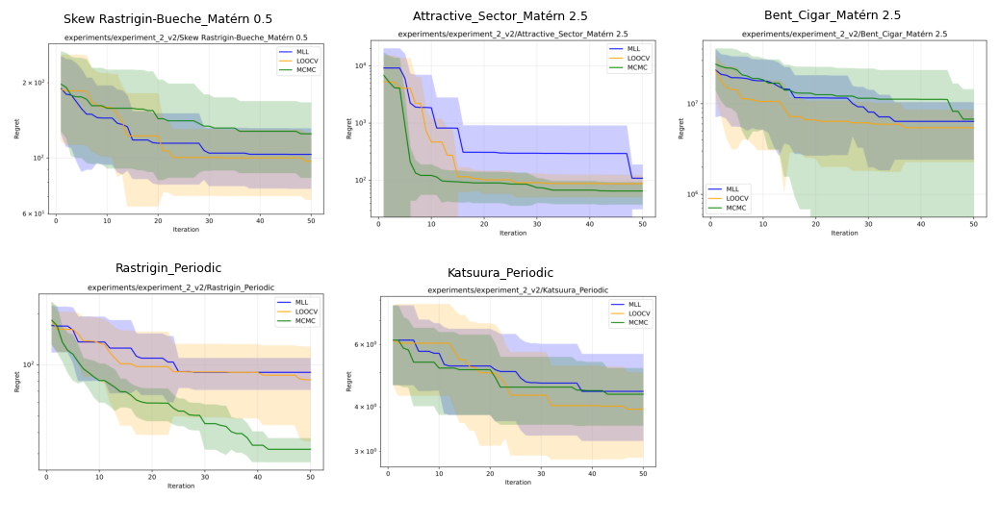

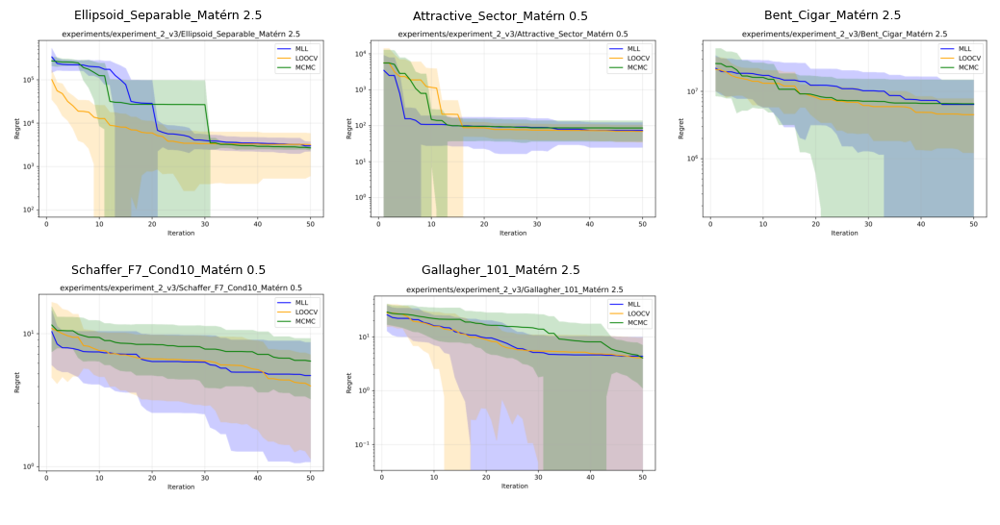

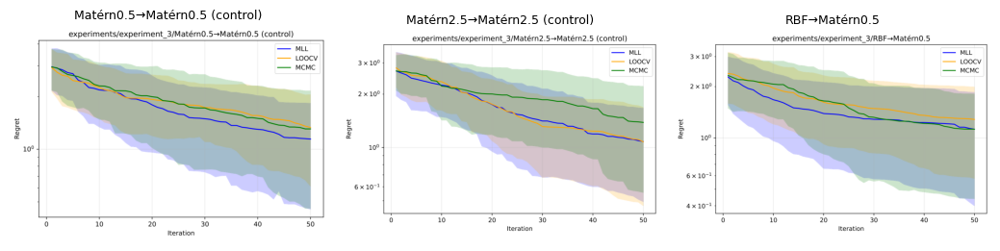

...

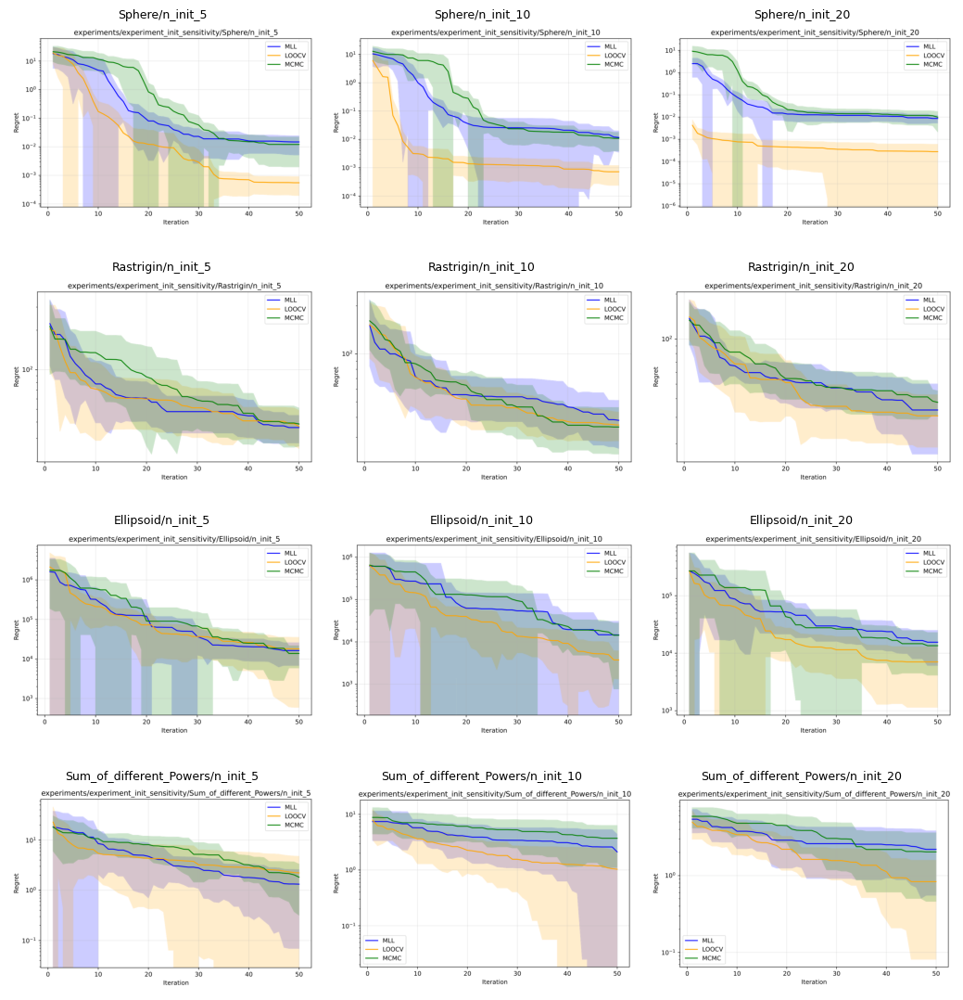

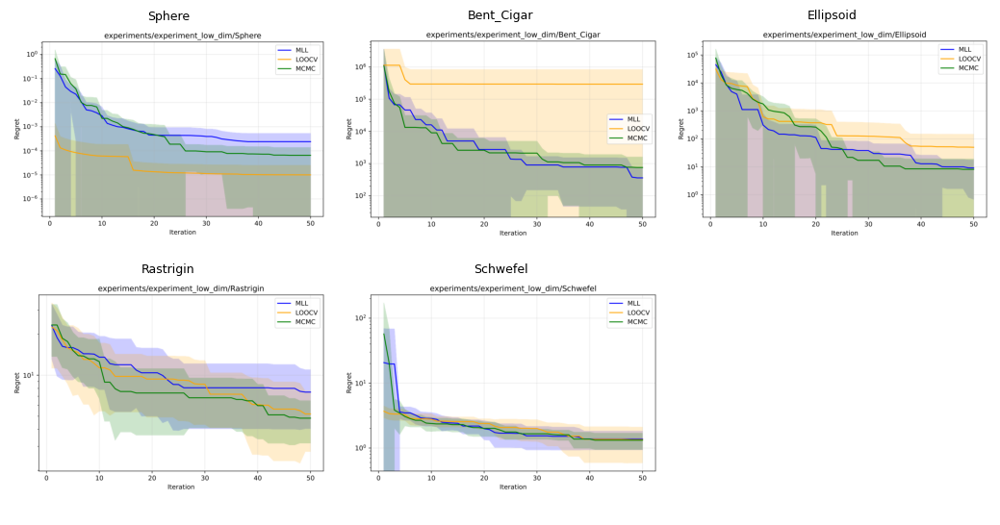

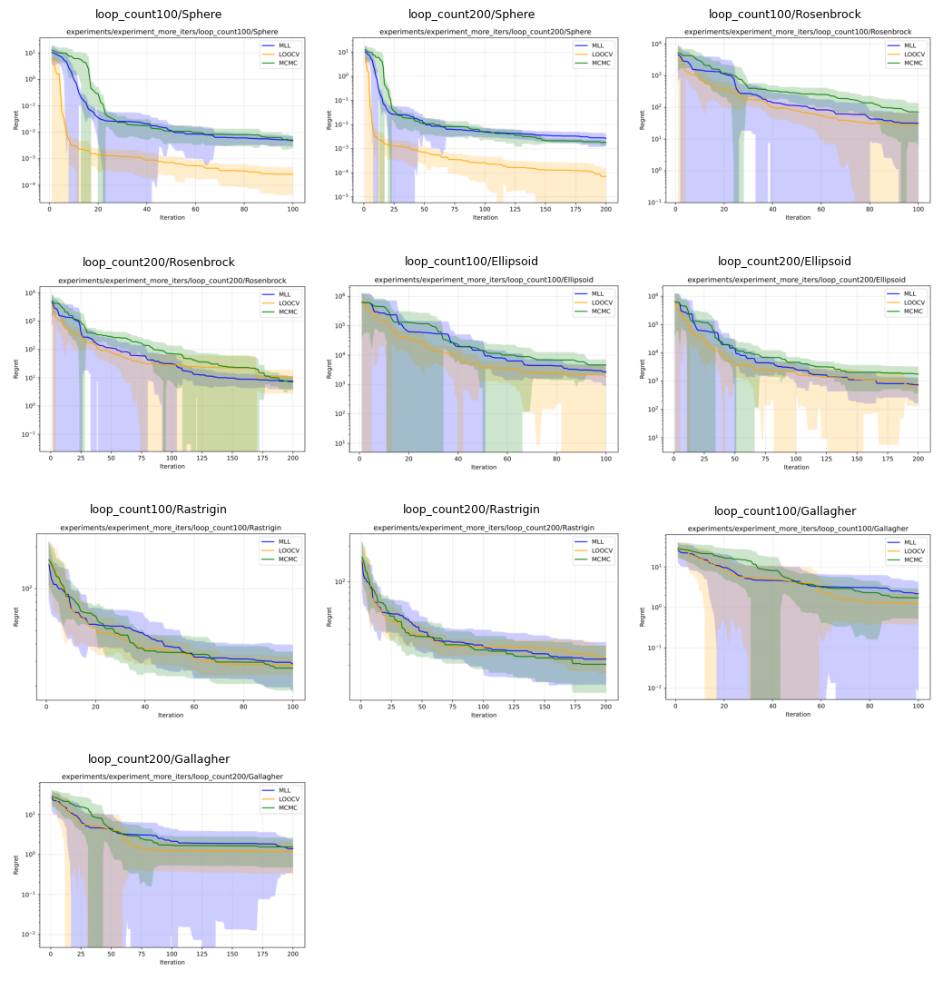

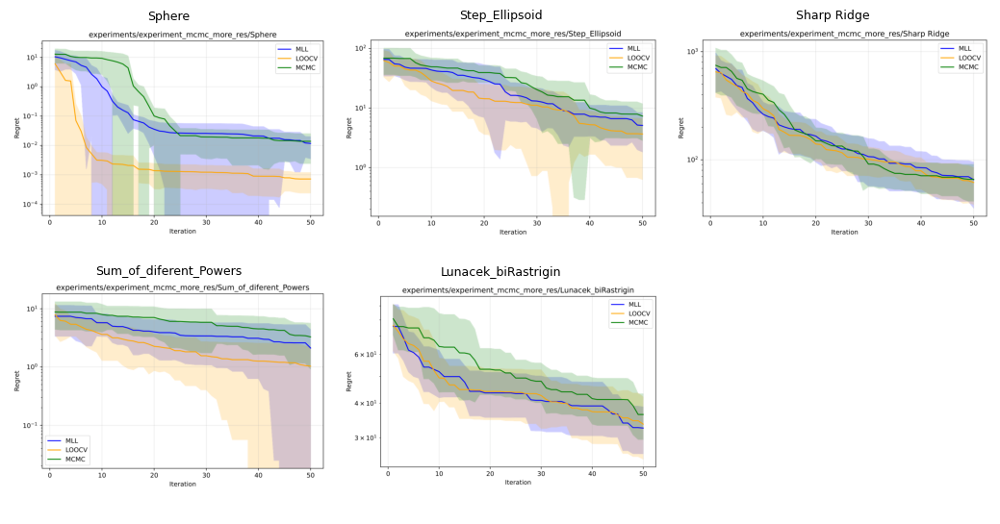

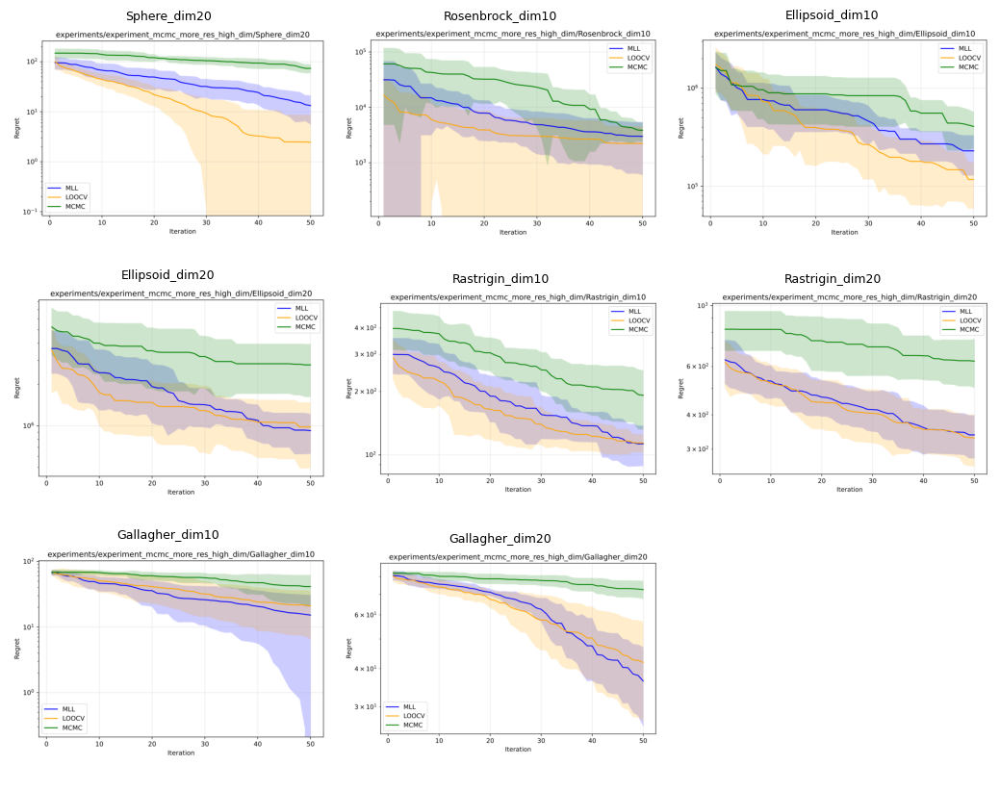

In [96]:
from pathlib import Path

# Kuratierte Ordnernamen pro Experiment (repräsentativ insignifikant bzw. alle insignifikant bei den kleinen Experimenten)
curated_lists = {
    "experiment_1": [
        "Ellipsoid_Separable", "Rosenbrock", "Bent_Cigar", "Weierstrass", "Gallagher_101",
    ],
    "experiment_2_v1": [
        "Linear Slope_Matérn 0.5", "Step_Ellipsoid_Matérn 2.5", "Bent_Cigar_Periodic",
        "Griewank_Rosenbrock_Matérn 2.5", "Gallagher_101_Periodic",
    ],
    "experiment_2_v2": [
        "Skew Rastrigin-Bueche_Matérn 0.5", "Attractive_Sector_Matérn 2.5", "Bent_Cigar_Matérn 2.5",
        "Rastrigin_Periodic", "Katsuura_Periodic",
    ],
    "experiment_2_v3": [
        "Ellipsoid_Separable_Matérn 2.5", "Attractive_Sector_Matérn 0.5", "Bent_Cigar_Matérn 2.5",
        "Schaffer_F7_Cond10_Matérn 0.5", "Gallagher_101_Matérn 2.5",
    ],
    "experiment_3": [
        "Matérn0.5→Matérn0.5 (control)", "Matérn2.5→Matérn2.5 (control)", "RBF→Matérn0.5",
    ],
    "experiment_4": [
        "d20/Sphere", "d10/Rosenbrock", "d10/Ellipsoid", "d20/Ellipsoid",
        "d10/Rastrigin", "d20/Rastrigin", "d10/Gallagher", "d20/Gallagher",
    ],
    "experiment_init_sensitivity": [
        "Sphere/n_init_5", "Sphere/n_init_10", "Sphere/n_init_20",
        "Rastrigin/n_init_5", "Rastrigin/n_init_10", "Rastrigin/n_init_20",
        "Ellipsoid/n_init_5", "Ellipsoid/n_init_10", "Ellipsoid/n_init_20",
        "Sum_of_different_Powers/n_init_5", "Sum_of_different_Powers/n_init_10", "Sum_of_different_Powers/n_init_20",
    ],
    "experiment_low_dim": [
        "Sphere", "Bent_Cigar", "Ellipsoid", "Rastrigin", "Schwefel",
    ],
    "experiment_more_iters": [
        "loop_count100/Sphere", "loop_count200/Sphere",
        "loop_count100/Rosenbrock", "loop_count200/Rosenbrock",
        "loop_count100/Ellipsoid", "loop_count200/Ellipsoid",
        "loop_count100/Rastrigin", "loop_count200/Rastrigin",
        "loop_count100/Gallagher", "loop_count200/Gallagher",
    ],
    "experiment_mcmc_more_res": [
        "Sphere", "Step_Ellipsoid", "Sharp Ridge", "Sum_of_diferent_Powers", "Lunacek_biRastrigin",
    ],
    "experiment_mcmc_more_res_high_dim": [
        "Sphere_dim20", "Rosenbrock_dim10",
        "Ellipsoid_dim10", "Ellipsoid_dim20",
        "Rastrigin_dim10", "Rastrigin_dim20",
        "Gallagher_dim10", "Gallagher_dim20",
    ],
}

for path_str, explicit_list in curated_lists.items():
    path = "functions/experiments/" + path_str
    exp_path = Path(path)
    appendix_path = Path("appendix")
    appendix_path.mkdir(parents=True, exist_ok=True)

    items = select_pdf_plots(exp_path, explicit_list=explicit_list)
    save_str = path_str + "_insignificant_grid.pdf"
    save_path = appendix_path / save_str
    plot_pdf_grid(
        items,
        ncols=3,
        save_path=save_path,
        dpi=150
    )

## Mixed Plots

/var/folders/fb/1zjmvd791gx5pp626gsbffpm0000gn/T/ipykernel_55321/3365856160.py:44: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per[0]*ncols, figsize_per[1]*nrows))


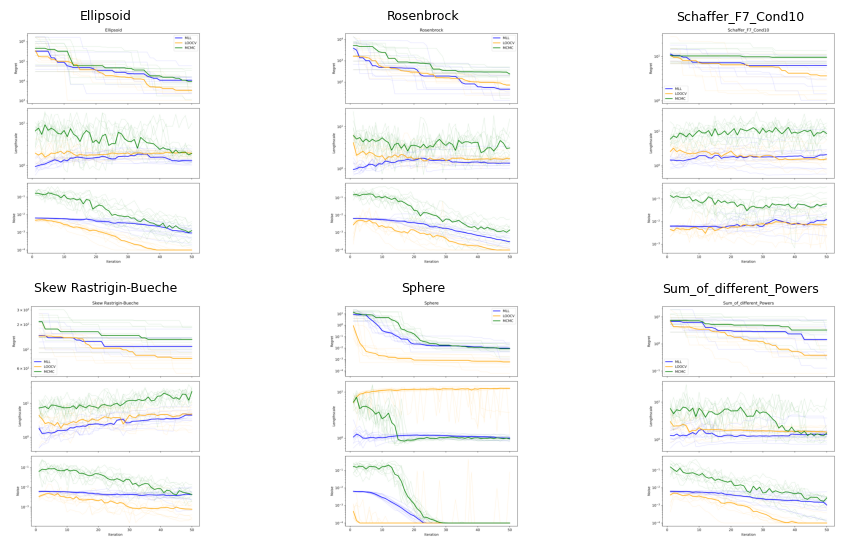

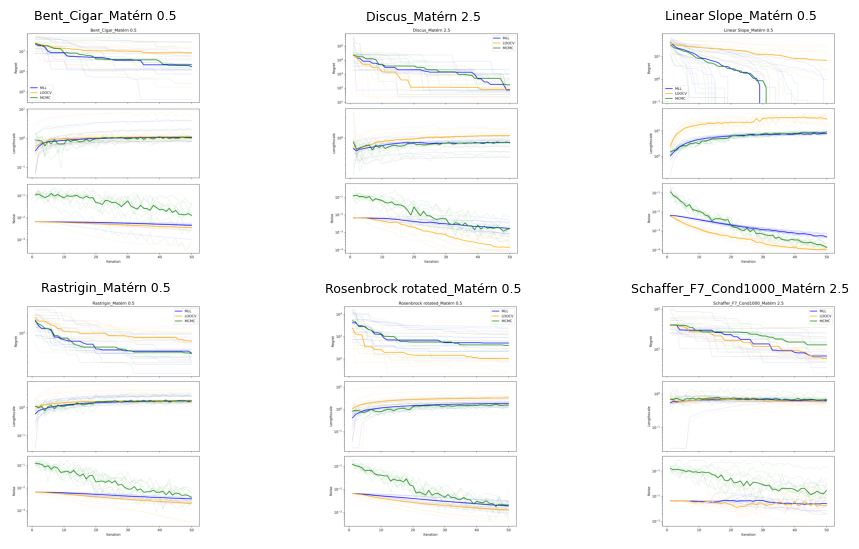

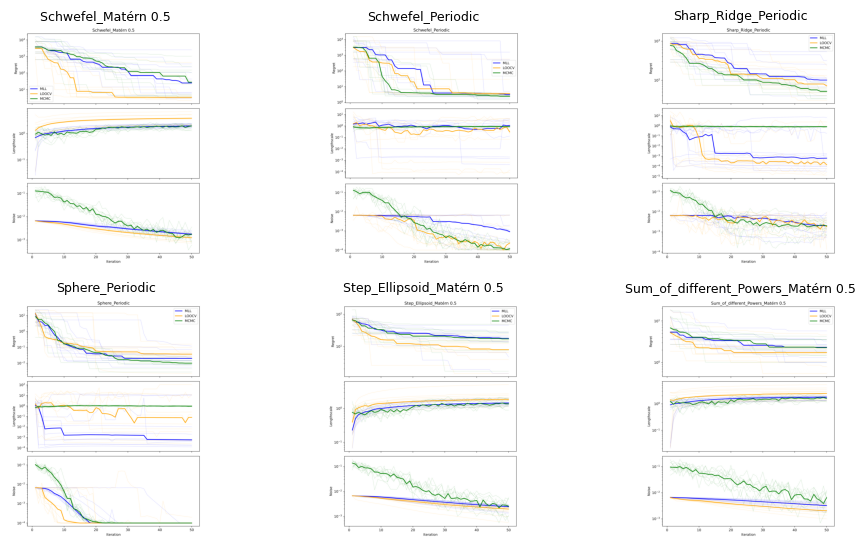

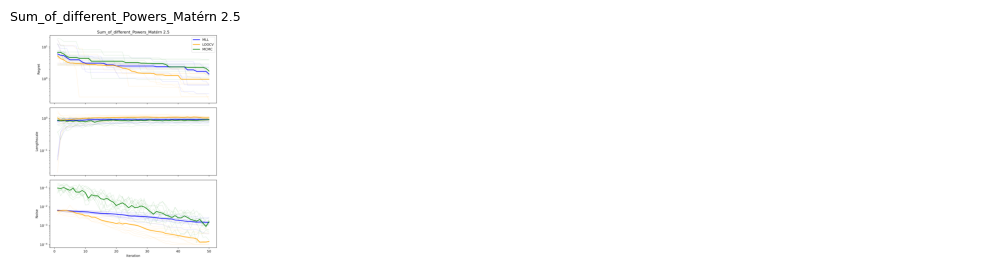

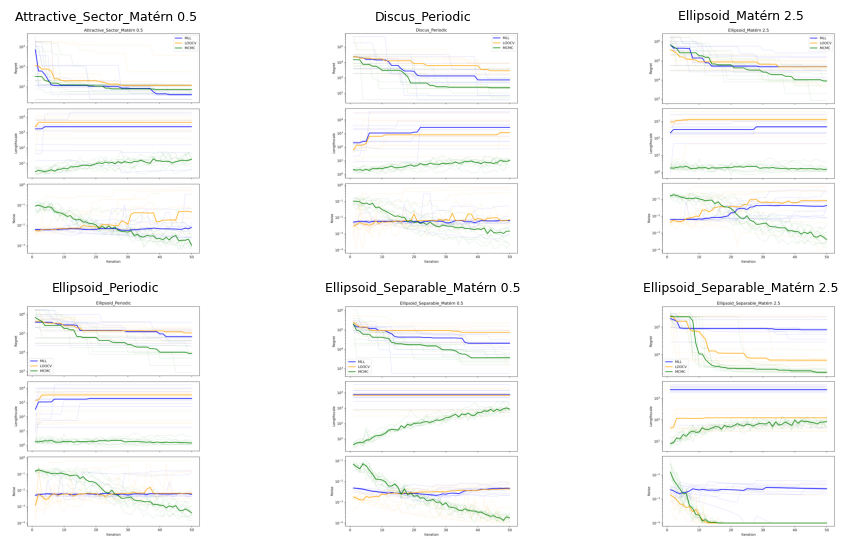

...

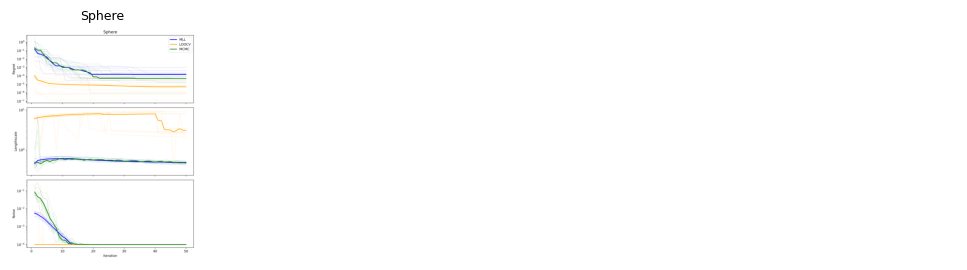

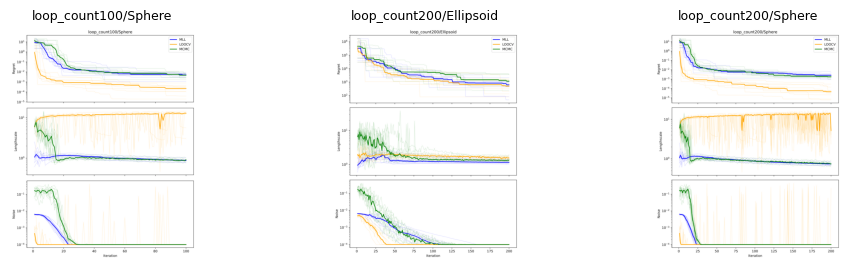

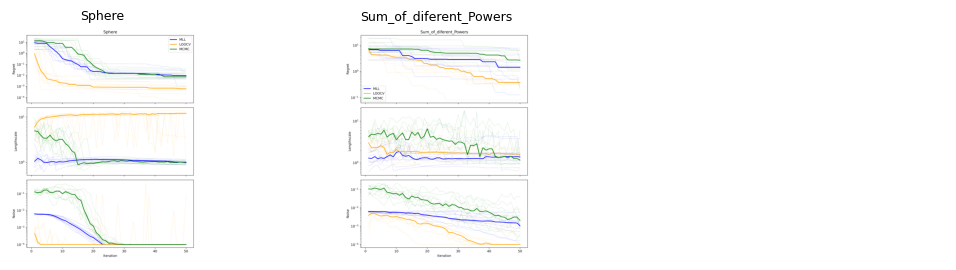

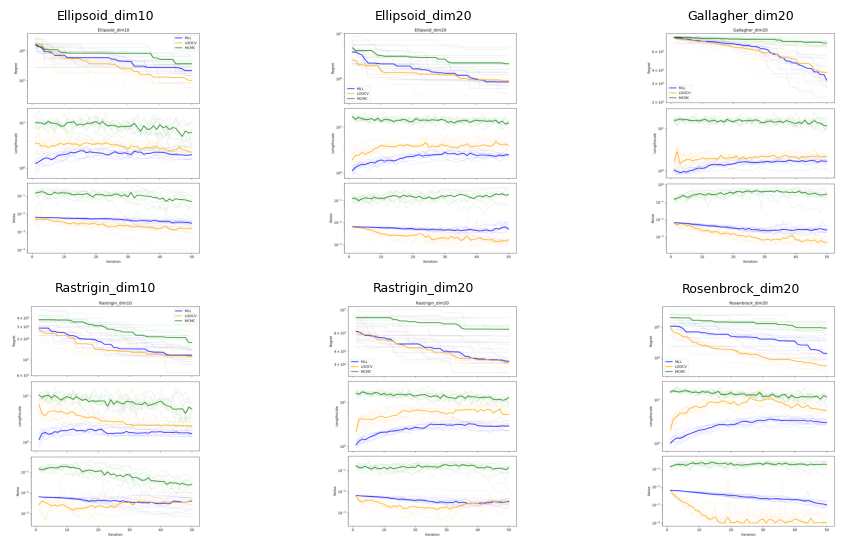

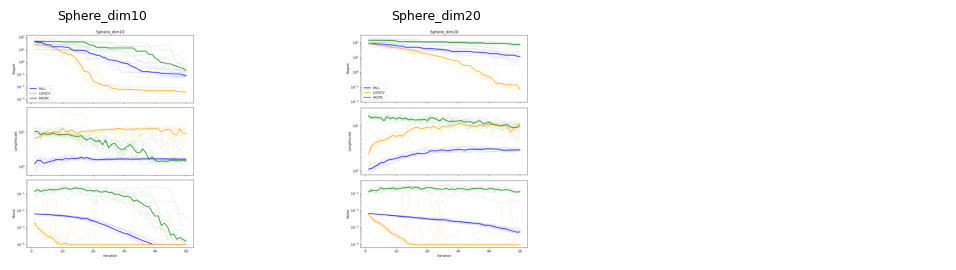

In [95]:
for path_str in ["experiment_1", "experiment_2_v1", "experiment_2_v2", "experiment_2_v3", "experiment_3",
                  "experiment_4", "experiment_init_sensitivity", "experiment_low_dim",
                  "experiment_more_iters", "experiment_mcmc_more_res", "experiment_mcmc_more_res_high_dim"]:
    path = "functions/experiments/" + path_str
    exp_path = Path(path)
    appendix_path = Path("appendix")
    appendix_path.mkdir(parents=True, exist_ok=True)

    items_diag = select_pdf_plots(exp_path, mode="significant", pdf_name="plot_overview.pdf")

    save_str = path_str + "_significant_grid_part{}.pdf"
    save_path_template = str(appendix_path / save_str)

    plot_pdf_grid_chunked(
        items_diag, ncols=3, max_per_page=6,
        save_path_template=save_path_template
    )